# How well is the decoding step of the primal attack predicted?

The last step of the primal attack on LWE decodes a target against a reduced basis. Attack-cost tools predict how often that step succeeds; the [lattice estimator](https://github.com/malb/lattice-estimator) does it with a simulated basis profile and Wunderer's Babai formula, which treats the error as spread evenly over a sphere of radius √d·σ and the levels as independent. This notebook measures how good that prediction is on real reduced bases, splits the error into its causes, and tests whether the exact centred binomial (CBD) error of ML-KEM helps pick the final candidate.

**Toy parameters only.** q = 3329, m = n samples, n = 70-100, lattice dimension 2n, CBD with η = 2 and 3, LLL and BKZ-10/20 from fplll. ML-KEM's real dimensions are far beyond any attack; nothing here is a statement about its security.

**Instance.** b = A s + e mod q, s and e from CBD(η). Lattice {(y, x) : x = A y mod q}, target (0, b), true offset o = (−s, e). With unit Gram-Schmidt directions u_i, Babai succeeds **exactly** when |⟨o, u_i⟩| < ‖b*_i‖/2 at every level, and Lindner-Peikert with d_i planes keeps the true leaf exactly when |⟨o, u_i⟩| < d_i‖b*_i‖/2. Both identities are asserted on every target in the run.

**Rules, set before any run** (docstring of `decoding_study.py`):

- **R1, calibration.** A model is off at a setting when its prediction falls outside the 99% Wilson interval of the measured rate. Babai and Lindner-Peikert (budgets 1024, 16384); 9 (reduction, n) settings × η ∈ {2, 3}; 16 held-out lattices × 100 targets each.
- **R2, final candidate.** On identical final lists, so at equal cost: CBD likelihood within a ±η box, and the box followed by Euclidean distance, against plain Euclidean distance. A rule helps only if McNemar's exact test is significant at Bonferroni α = 0.05/48. The share of targets whose true point is anywhere in the list bounds what any rule can gain.

**How it ran.** Bases: the held-out bases of `toy_lwe_test.py` (fplll in WSL). Decoding: `toy_lwe_gpu.py` on an RTX A1000, same output as the CPU decoders (216 decodes checked). Estimator: commit printed below, run under SageMath 10 in WSL by `estimator_predictions.py`, calling `PrimalHybrid.beta_params` with our lattice (d = 2n, n q-vectors).

In [1]:
import json, math
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

RED = {2: "LLL", 10: "BKZ-10", 20: "BKZ-20"}
Z99 = 2.5758293035489
INK, GRID, AXIS, SURFACE = "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"


def table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def wilson(k, n, z=Z99):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (0.0 if k == 0 else c - h), (1.0 if k == n else c + h)  # exact ends, no float spill past 0 or 1


def mcnemar(a, b):
    x, y = sum(1 for u, v in zip(a, b) if u and not v), sum(1 for u, v in zip(a, b) if v and not u)
    p = 1.0 if x + y == 0 else min(1.0, 2 * sum(math.comb(x + y, k) for k in range(min(x, y) + 1)) / 2 ** (x + y))
    return x, y, p


name = lambda s: f"{RED[s['beta']]} n={s['n']}"
pct = lambda p: f"{100 * p:.1f}%"

In [2]:
CAL = json.loads(r"""[{"beta":2,"n":70,"eta":2,"lattices":16,"babai":{"k":706,"N":1600,"per_lattice":[63,45,45,44,37,33,49,46,30,49,46,45,38,46,48,42],"in_leaves":706,"nodes":140.0,"gauss":0.45808849306973054,"sphere":0.46108810459069166,"cbd_joint":0.45643999999999996,"cbd_marginals":0.4590383657902809},"lp1024":{"k":1435,"N":1600,"per_lattice":[99,92,89,89,83,85,92,95,76,92,91,94,88,88,94,88],"in_leaves":1435,"nodes":134015.0,"gauss":0.8938167293538901,"sphere":0.8985236249478854,"cbd_joint":0.895164375,"cbd_marginals":0.8954216932315174},"lp16384":{"k":1551,"N":1600,"per_lattice":[100,100,95,97,96,95,99,100,94,97,95,98,97,94,98,96],"in_leaves":1551,"nodes":2076927.0,"gauss":0.9659702686765663,"sphere":0.9690127694580195,"cbd_joint":0.9668659375,"cbd_marginals":0.9669187326801374},"estimator":{"GSA":0.3510513097236204,"ZGSA":0.23033843288479322,"CN11":1.784546325849118e-19,"beta_params_babai":0.3510513097236204,"real":0.4610881045906914},"zshape":{"s4_mean":0.021914660689731292,"s4_failweighted":0.022733038868577353,"worst_s4":0.02287112635865076,"worst_fail_cbd":0.10588437499999995,"worst_fail_gauss":0.10593834886418957,"fail_share_last10":0.8621911226872916}},{"beta":2,"n":80,"eta":2,"lattices":16,"babai":{"k":41,"N":1600,"per_lattice":[1,1,3,0,0,7,6,10,0,0,1,4,0,2,3,3],"in_leaves":41,"nodes":160.0,"gauss":0.029683386637786652,"sphere":0.029465798318499083,"cbd_joint":0.028485000000000003,"cbd_marginals":0.029604035489716133},"lp1024":{"k":443,"N":1600,"per_lattice":[20,16,38,20,16,35,33,54,25,16,18,34,14,35,35,34],"in_leaves":443,"nodes":154231.0,"gauss":0.2688037097560817,"sphere":0.27085789797820964,"cbd_joint":0.26612375,"cbd_marginals":0.2693025548205782},"lp16384":{"k":769,"N":1600,"per_lattice":[28,28,62,46,29,58,55,80,44,41,35,52,38,61,54,58],"in_leaves":769,"nodes":2402559.0,"gauss":0.45670686355163514,"sphere":0.46138983596735905,"cbd_joint":0.45495375000000005,"cbd_marginals":0.4579670944744064},"estimator":{"GSA":0.015559786284962213,"ZGSA":0.005004396946646041,"CN11":6.720304845400039e-23,"beta_params_babai":0.015559786284962213,"real":0.02946579831849918},"zshape":{"s4_mean":0.01968989764273188,"s4_failweighted":0.02061848387130655,"worst_s4":0.021543567970305433,"worst_fail_cbd":0.30069437499999996,"worst_fail_gauss":0.3004401694246578,"fail_share_last10":0.6801098781967796}},{"beta":10,"n":70,"eta":2,"lattices":16,"babai":{"k":1575,"N":1600,"per_lattice":[97,98,98,98,99,100,98,100,98,99,98,99,100,95,99,99],"in_leaves":1575,"nodes":140.0,"gauss":0.9819894422077122,"sphere":0.9840673956861027,"cbd_joint":0.9824090624999999,"cbd_marginals":0.9824196185100125},"lp1024":{"k":1600,"N":1600,"per_lattice":[100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100],"in_leaves":1600,"nodes":134015.0,"gauss":0.9996355742840293,"sphere":0.9997568579517082,"cbd_joint":0.9996609375,"cbd_marginals":0.9996609808486666},"lp16384":{"k":1600,"N":1600,"per_lattice":[100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100],"in_leaves":1600,"nodes":2078207.0,"gauss":0.999958829456355,"sphere":0.9999782864540612,"cbd_joint":0.9999609374999999,"cbd_marginals":0.9999609381109336},"estimator":{"GSA":0.9951436615612278,"ZGSA":0.5385361302893314,"CN11":0.9913807596376721,"beta_params_babai":0.9951436615612278,"real":0.9840673956861016},"zshape":{"s4_mean":0.021299121626579296,"s4_failweighted":0.021255796141843534,"worst_s4":0.02160052799667303,"worst_fail_cbd":0.004573124999999914,"worst_fail_gauss":0.0045754986806185935,"fail_share_last10":0.9788816574424118}},{"beta":10,"n":80,"eta":2,"lattices":16,"babai":{"k":1065,"N":1600,"per_lattice":[61,67,69,60,63,77,64,80,66,73,57,70,63,68,58,69],"in_leaves":1065,"nodes":160.0,"gauss":0.6684353486048996,"sphere":0.6734087323085302,"cbd_joint":0.6684625,"cbd_marginals":0.669602133868099},"lp1024":{"k":1519,"N":1600,"per_lattice":[91,98,95,92,93,96,98,99,97,93,97,97,93,92,90,98],"in_leaves":1519,"nodes":154319.0,"gauss":0.9483701452522607,"sphere":0.9516359812945296,"cbd_joint":0.9493168750000001,"cbd_marginals":0.9493961469361057},"lp16384":{"k":1576,"N":1600,"per_lattice":[97,99,98,97,98,99,100,100,100,97,99,100,96,99,97,100],"in_leaves":1576,"nodes":2404607.0,"gauss":0.9826140931739626,"sphere":0.9843956747501427,"cbd_joint":0.9831053125,"cbd_marginals":0.9831021253913343},"estimator":{"GSA":0.8951204769006705,"ZGSA":0.05628466764214577,"CN11":0.8156273234914859,"beta_params_babai":0.8951204769006705,"real":0.6734087323085298},"zshape":{"s4_mean":0.018837264816925204,"s4_failweighted":0.01901283880137738,"worst_s4":0.017824119440704753,"worst_fail_cbd":0.06039843749999993,"worst_fail_gauss":0.060261070595131354,"fail_share_last10":0.867091708014123}},{"beta":10,"n":100,"eta":2,"lattices":16,"babai":{"k":0,"N":1600,"per_lattice":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"in_leaves":0,"nodes":200.0,"gauss":0.0005511537208221532,"sphere":0.0005377890056232152,"cbd_joint":0.0005134375,"cbd_marginals":0.0005492247143407303},"lp1024":{"k":31,"N":1600,"per_lattice":[2,2,2,1,3,4,2,0,1,1,2,2,1,4,3,1],"in_leaves":31,"nodes":195263.0,"gauss":0.019359699385539515,"sphere":0.0192869032401393,"cbd_joint":0.018488437500000003,"cbd_marginals":0.019380040769151605},"lp16384":{"k":84,"N":1600,"per_lattice":[8,7,7,5,8,8,5,2,4,2,5,4,4,6,5,4],"in_leaves":84,"nodes":3060351.0,"gauss":0.05499465138263239,"sphere":0.05515355268013973,"cbd_joint":0.05303375,"cbd_marginals":0.055107301713540446},"estimator":{"GSA":0.07071172190374467,"ZGSA":7.406317016006533e-08,"CN11":0.016369959356699625,"beta_params_babai":0.07071172190374467,"real":0.0005377890056232186},"zshape":{"s4_mean":0.01572735578286569,"s4_failweighted":0.016106436171170635,"worst_s4":0.015850661966867297,"worst_fail_cbd":0.4030590624999999,"worst_fail_gauss":0.4028379339941398,"fail_share_last10":0.5286971358366235}},{"beta":20,"n":70,"eta":2,"lattices":16,"babai":{"k":1597,"N":1600,"per_lattice":[99,100,100,100,100,100,100,100,100,100,99,99,100,100,100,100],"in_leaves":1597,"nodes":140.0,"gauss":0.998864333969739,"sphere":0.999161351347191,"cbd_joint":0.9989046875,"cbd_marginals":0.9989051890083804},"lp1024":{"k":1600,"N":1600,"per_lattice":[100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100],"in_leaves":1600,"nodes":133767.0,"gauss":0.9999952810749293,"sphere":0.9999982079434073,"cbd_joint":0.9999959375,"cbd_marginals":0.9999959375046875},"lp16384":{"k":1600,"N":1600,"per_lattice":[100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100],"in_leaves":1600,"nodes":2078719.0,"gauss":0.9999998430094756,"sphere":0.9999999700326,"cbd_joint":1.0,"cbd_marginals":1.0},"estimator":{"GSA":0.9999330611532165,"ZGSA":0.994452904053833,"CN11":0.999388120590816,"beta_params_babai":0.9999330611532165,"real":0.99916135134719},"zshape":{"s4_mean":0.021175859426137852,"s4_failweighted":0.02132735629833296,"worst_s4":0.02101396373130594,"worst_fail_cbd":0.00041312499999992397,"worst_fail_gauss":0.00042783701613033354,"fail_share_last10":0.9922962813874273}},{"beta":20,"n":80,"eta":2,"lattices":16,"babai":{"k":1495,"N":1600,"per_lattice":[91,95,93,92,93,94,92,99,95,91,93,92,95,92,93,95],"in_leaves":1495,"nodes":160.0,"gauss":0.9345046587935517,"sphere":0.9381381553033249,"cbd_joint":0.9354146875,"cbd_marginals":0.9355051489874364},"lp1024":{"k":1597,"N":1600,"per_lattice":[99,100,100,100,100,100,99,100,100,100,100,99,100,100,100,100],"in_leaves":1597,"nodes":154479.0,"gauss":0.9969737985384036,"sphere":0.9975229662155571,"cbd_joint":0.99709,"cbd_marginals":0.9970905105471227},"lp16384":{"k":1598,"N":1600,"per_lattice":[99,100,100,100,100,100,100,100,100,100,100,99,100,100,100,100],"in_leaves":1598,"nodes":2405887.0,"gauss":0.9994109270249698,"sphere":0.9995716863688898,"cbd_joint":0.9994468750000001,"cbd_marginals":0.9994470026695867},"estimator":{"GSA":0.993461731024204,"ZGSA":0.886037040976816,"CN11":0.9721962519391841,"beta_params_babai":0.993461731024204,"real":0.9381381553033241},"zshape":{"s4_mean":0.018557941009925125,"s4_failweighted":0.0184420404531472,"worst_s4":0.01819195248441931,"worst_fail_cbd":0.014848437499999916,"worst_fail_gauss":0.014874732351087841,"fail_share_last10":0.9548139308381718}},{"beta":20,"n":90,"eta":2,"lattices":16,"babai":{"k":798,"N":1600,"per_lattice":[54,52,46,62,50,52,45,53,50,53,49,45,45,47,47,48],"in_leaves":798,"nodes":180.0,"gauss":0.4925161212075776,"sphere":0.4957940375602744,"cbd_joint":0.49185218750000004,"cbd_marginals":0.493672949014074},"lp1024":{"k":1442,"N":1600,"per_lattice":[94,88,89,91,90,91,89,91,87,88,92,91,92,93,88,88],"in_leaves":1442,"nodes":174975.0,"gauss":0.8892728540055279,"sphere":0.8936395124322837,"cbd_joint":0.8904615625,"cbd_marginals":0.8907054718894499},"lp16384":{"k":1531,"N":1600,"per_lattice":[100,94,96,95,95,97,97,95,96,92,96,95,95,95,97,96],"in_leaves":1531,"nodes":2733567.0,"gauss":0.9538585101125238,"sphere":0.9569307327860643,"cbd_joint":0.95475875,"cbd_marginals":0.9547926225394335},"estimator":{"GSA":0.9017866831117759,"ZGSA":0.4518588495119738,"CN11":0.7514783900593327,"beta_params_babai":0.9017866831117759,"real":0.4957940375602738},"zshape":{"s4_mean":0.01662016899309552,"s4_failweighted":0.016646594120681056,"worst_s4":0.016737088995042067,"worst_fail_cbd":0.09706999999999993,"worst_fail_gauss":0.09726181816598214,"fail_share_last10":0.834757969061011}},{"beta":20,"n":100,"eta":2,"lattices":16,"babai":{"k":65,"N":1600,"per_lattice":[2,5,5,5,6,1,8,3,4,4,6,4,4,4,3,1],"in_leaves":65,"nodes":200.0,"gauss":0.03970148638399239,"sphere":0.03956131225010062,"cbd_joint":0.038490625,"cbd_marginals":0.03965149562004092},"lp1024":{"k":468,"N":1600,"per_lattice":[17,33,28,31,31,29,33,21,32,32,24,40,30,32,30,25],"in_leaves":468,"nodes":195327.0,"gauss":0.3048565850663756,"sphere":0.3074342849004126,"cbd_joint":0.30254499999999995,"cbd_marginals":0.305511681575745},"lp16384":{"k":756,"N":1600,"per_lattice":[37,45,46,55,52,51,45,36,54,43,47,57,47,54,48,39],"in_leaves":756,"nodes":3058687.0,"gauss":0.47638405092164865,"sphere":0.48103186686060023,"cbd_joint":0.4748396875,"cbd_marginals":0.4772551805379388},"estimator":{"GSA":0.5410103054139501,"ZGSA":0.06230606624632517,"CN11":0.2734001590555345,"beta_params_babai":0.5410103054139501,"real":0.039561312250101},"zshape":{"s4_mean":0.015140889382903876,"s4_failweighted":0.015275735960583549,"worst_s4":0.015519175898537341,"worst_fail_cbd":0.25417906249999994,"worst_fail_gauss":0.25332485180815356,"fail_share_last10":0.649709869249913}},{"beta":2,"n":70,"eta":3,"lattices":16,"babai":{"k":282,"N":1600,"per_lattice":[28,17,21,22,9,10,22,26,10,20,16,13,17,20,16,15],"in_leaves":282,"nodes":140.0,"gauss":0.17464308320097266,"sphere":0.17484246177476456,"cbd_joint":0.1726965625,"cbd_marginals":0.17462190375476963},"lp1024":{"k":1065,"N":1600,"per_lattice":[78,80,65,73,60,52,79,71,50,70,66,60,66,68,73,54],"in_leaves":1065,"nodes":134015.0,"gauss":0.6714860008414345,"sphere":0.6774722338737442,"cbd_joint":0.6715915625,"cbd_marginals":0.6724924924919413},"lp16384":{"k":1368,"N":1600,"per_lattice":[91,93,85,86,85,76,92,91,82,86,83,82,85,83,84,84],"in_leaves":1368,"nodes":2076927.0,"gauss":0.8405382952653436,"sphere":0.8471108128379838,"cbd_joint":0.8415703124999999,"cbd_marginals":0.8417789357749949},"estimator":{"GSA":0.11568400946619621,"ZGSA":0.05987978462828474,"CN11":1.090212289808848e-23,"beta_params_babai":0.11568400946619621,"real":0.1748424617747648},"zshape":{"s4_mean":0.021914660689731292,"s4_failweighted":0.022750371710445343,"worst_s4":0.02356733500635575,"worst_fail_cbd":0.18662999999999993,"worst_fail_gauss":0.1864058153272211,"fail_share_last10":0.7860299871768275}},{"beta":2,"n":80,"eta":3,"lattices":16,"babai":{"k":4,"N":1600,"per_lattice":[0,0,0,0,0,0,3,1,0,0,0,0,0,0,0,0],"in_leaves":4,"nodes":160.0,"gauss":0.0031959440267335954,"sphere":0.0031353112693200125,"cbd_joint":0.0030628125000000004,"cbd_marginals":0.0031886332897646864},"lp1024":{"k":108,"N":1600,"per_lattice":[3,2,6,6,1,8,19,23,0,0,3,6,7,9,3,12],"in_leaves":108,"nodes":154231.0,"gauss":0.06779640890352731,"sphere":0.06793941129093006,"cbd_joint":0.066364375,"cbd_marginals":0.067751629876192},"lp16384":{"k":259,"N":1600,"per_lattice":[7,5,24,12,6,23,30,44,5,6,9,18,11,21,13,25],"in_leaves":259,"nodes":2402559.0,"gauss":0.15768729425509453,"sphere":0.15893703446176335,"cbd_joint":0.155605625,"cbd_marginals":0.15765214904253216},"estimator":{"GSA":0.0012405264063179416,"ZGSA":0.0002847429061564354,"CN11":7.937804872664934e-28,"beta_params_babai":0.0012405264063179416,"real":0.0031353112693200255},"zshape":{"s4_mean":0.01968989764273188,"s4_failweighted":0.020606218196864465,"worst_s4":0.021543567970305433,"worst_fail_cbd":0.3976215624999999,"worst_fail_gauss":0.3970706456560755,"fail_share_last10":0.6046652603018297}},{"beta":10,"n":70,"eta":3,"lattices":16,"babai":{"k":1447,"N":1600,"per_lattice":[91,83,93,92,94,92,89,91,92,90,88,91,92,87,89,93],"in_leaves":1447,"nodes":140.0,"gauss":0.8991023724026932,"sphere":0.9041001179896968,"cbd_joint":0.8999009375,"cbd_marginals":0.8999871198729172},"lp1024":{"k":1591,"N":1600,"per_lattice":[100,99,100,100,100,96,100,100,99,100,100,99,99,99,100,100],"in_leaves":1591,"nodes":134015.0,"gauss":0.9937803144548742,"sphere":0.9948073078654313,"cbd_joint":0.9939915625,"cbd_marginals":0.9939924590095908},"lp16384":{"k":1599,"N":1600,"per_lattice":[100,100,100,100,100,100,100,100,99,100,100,100,100,100,100,100],"in_leaves":1599,"nodes":2078207.0,"gauss":0.9986930081262542,"sphere":0.9990237097959445,"cbd_joint":0.998791875,"cbd_marginals":0.9987924896202349},"estimator":{"GSA":0.9587970943520474,"ZGSA":0.23827230356369788,"CN11":0.9382034581609496,"beta_params_babai":0.9587970943520474,"real":0.9041001179896959},"zshape":{"s4_mean":0.021299121626579296,"s4_failweighted":0.021270149328985105,"worst_s4":0.021161459076476645,"worst_fail_cbd":0.02023093749999992,"worst_fail_gauss":0.020407155502364105,"fail_share_last10":0.9408565850817636}},{"beta":10,"n":80,"eta":3,"lattices":16,"babai":{"k":522,"N":1600,"per_lattice":[34,27,40,20,37,42,32,34,33,35,26,27,31,33,29,42],"in_leaves":522,"nodes":160.0,"gauss":0.33657059932350875,"sphere":0.3386801906756519,"cbd_joint":0.33471937500000004,"cbd_marginals":0.33665754537436066},"lp1024":{"k":1275,"N":1600,"per_lattice":[80,80,82,81,82,82,76,81,80,85,71,79,81,78,79,78],"in_leaves":1275,"nodes":154319.0,"gauss":0.7900721886372408,"sphere":0.795719160428929,"cbd_joint":0.7904424999999999,"cbd_marginals":0.7908909418915311},"lp16384":{"k":1437,"N":1600,"per_lattice":[87,91,95,90,89,93,85,90,87,93,85,96,89,93,87,87],"in_leaves":1437,"nodes":2404607.0,"gauss":0.9002861456959285,"sphere":0.9051379902005038,"cbd_joint":0.9011137499999999,"cbd_marginals":0.9012272653719862},"estimator":{"GSA":0.6656586412353543,"ZGSA":0.007062828235408747,"CN11":0.5240803891406813,"beta_params_babai":0.6656586412353543,"real":0.33868019067565197},"zshape":{"s4_mean":0.018837264816925204,"s4_failweighted":0.019041927422951556,"worst_s4":0.017941115385744288,"worst_fail_cbd":0.12489531249999991,"worst_fail_gauss":0.12449379390650771,"fail_share_last10":0.7838078409055427}},{"beta":10,"n":100,"eta":3,"lattices":16,"babai":{"k":0,"N":1600,"per_lattice":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"in_leaves":0,"nodes":200.0,"gauss":1.017432955569146e-05,"sphere":9.766101247200102e-06,"cbd_joint":9.687500000000002e-06,"cbd_marginals":1.013073435971365e-05},"lp1024":{"k":1,"N":1600,"per_lattice":[0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0],"in_leaves":1,"nodes":195263.0,"gauss":0.0008505704945868205,"sphere":0.0008338130450284823,"cbd_joint":0.0008065625,"cbd_marginals":0.0008486266694158023},"lp16384":{"k":7,"N":1600,"per_lattice":[0,0,2,0,1,0,0,0,0,1,1,1,0,1,0,0],"in_leaves":7,"nodes":3060351.0,"gauss":0.003574467979862582,"sphere":0.0035337679923534713,"cbd_joint":0.0033959374999999997,"cbd_marginals":0.003576173077549249},"estimator":{"GSA":0.007914359663541263,"ZGSA":2.797994063195943e-10,"CN11":0.000955215611092666,"beta_params_babai":0.007914359663541263,"real":9.76610124720031e-06},"zshape":{"s4_mean":0.01572735578286569,"s4_failweighted":0.0161021709688607,"worst_s4":0.015850661966867297,"worst_fail_cbd":0.49412749999999994,"worst_fail_gauss":0.49450489341729886,"fail_share_last10":0.4634569215792115}},{"beta":20,"n":70,"eta":3,"lattices":16,"babai":{"k":1578,"N":1600,"per_lattice":[100,99,99,100,100,100,99,98,97,96,98,99,98,98,97,100],"in_leaves":1578,"nodes":140.0,"gauss":0.9859216800375039,"sphere":0.9877032636981204,"cbd_joint":0.98631875,"cbd_marginals":0.986318618607249},"lp1024":{"k":1600,"N":1600,"per_lattice":[100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100],"in_leaves":1600,"nodes":133767.0,"gauss":0.9997143736255001,"sphere":0.999813738500078,"cbd_joint":0.9997253125000001,"cbd_marginals":0.9997253418812061},"lp16384":{"k":1600,"N":1600,"per_lattice":[100,100,100,100,100,100,100,100,100,100,100,100,100,100,100,100],"in_leaves":1600,"nodes":2078719.0,"gauss":0.9999727107160973,"sphere":0.999986713504081,"cbd_joint":0.99998,"cbd_marginals":0.9999800001484372},"estimator":{"GSA":0.9977595349238934,"ZGSA":0.9548596647795463,"CN11":0.9900133911275841,"beta_params_babai":0.9977595349238934,"real":0.9877032636981193},"zshape":{"s4_mean":0.021175859426137852,"s4_failweighted":0.02145273453302488,"worst_s4":0.02101396373130594,"worst_fail_cbd":0.003941874999999921,"worst_fail_gauss":0.003966502931292672,"fail_share_last10":0.9762242158481695}},{"beta":20,"n":80,"eta":3,"lattices":16,"babai":{"k":1216,"N":1600,"per_lattice":[74,78,75,75,71,78,69,81,74,79,85,76,75,74,78,74],"in_leaves":1216,"nodes":160.0,"gauss":0.7552824561653706,"sphere":0.7605074773192261,"cbd_joint":0.756224375,"cbd_marginals":0.7566685689795205},"lp1024":{"k":1554,"N":1600,"per_lattice":[98,97,95,99,94,99,94,99,98,98,99,98,96,97,97,96],"in_leaves":1554,"nodes":154479.0,"gauss":0.971375459859751,"sphere":0.9738303885439931,"cbd_joint":0.9719115625,"cbd_marginals":0.9719409694744283},"lp16384":{"k":1586,"N":1600,"per_lattice":[99,98,99,100,100,99,97,99,99,99,99,100,99,100,100,99],"in_leaves":1586,"nodes":2405887.0,"gauss":0.9909811871963329,"sphere":0.9921943880971553,"cbd_joint":0.9912665625,"cbd_marginals":0.9912646020429167},"estimator":{"GSA":0.9477911744611542,"ZGSA":0.6477806497171138,"CN11":0.8599639176110174,"beta_params_babai":0.9477911744611542,"real":0.7605074773192254},"zshape":{"s4_mean":0.018557941009925125,"s4_failweighted":0.018479189455590597,"worst_s4":0.01810436617237592,"worst_fail_cbd":0.04642437499999992,"worst_fail_gauss":0.04659112337087967,"fail_share_last10":0.8959837809028395}},{"beta":20,"n":90,"eta":3,"lattices":16,"babai":{"k":308,"N":1600,"per_lattice":[16,15,22,16,18,23,19,22,16,17,16,23,22,20,15,28],"in_leaves":308,"nodes":180.0,"gauss":0.18408353870794722,"sphere":0.1847235804547953,"cbd_joint":0.1825178125,"cbd_marginals":0.18424018187088834},"lp1024":{"k":1028,"N":1600,"per_lattice":[69,62,60,64,63,64,66,65,65,56,64,67,66,61,69,67],"in_leaves":1028,"nodes":174975.0,"gauss":0.6415575649130408,"sphere":0.647059620686704,"cbd_joint":0.6412975000000001,"cbd_marginals":0.6422456392131197},"lp16384":{"k":1270,"N":1600,"per_lattice":[79,77,71,80,81,78,82,75,83,77,79,82,82,78,81,85],"in_leaves":1270,"nodes":2733567.0,"gauss":0.793420748665846,"sphere":0.7994354976900189,"cbd_joint":0.7938303125,"cbd_marginals":0.79431853409837},"estimator":{"GSA":0.6713813287630194,"ZGSA":0.15896071300267822,"CN11":0.42915828565493835,"beta_params_babai":0.6713813287630194,"real":0.1847235804547959},"zshape":{"s4_mean":0.01662016899309552,"s4_failweighted":0.01665239379942264,"worst_s4":0.016737088995042067,"worst_fail_cbd":0.17540968749999994,"worst_fail_gauss":0.17536822015276854,"fail_share_last10":0.7425972388381077}},{"beta":20,"n":100,"eta":3,"lattices":16,"babai":{"k":5,"N":1600,"per_lattice":[0,0,0,0,1,0,0,0,1,0,1,1,1,0,0,0],"in_leaves":5,"nodes":200.0,"gauss":0.0031850154618039053,"sphere":0.003136253696694143,"cbd_joint":0.0030215625,"cbd_marginals":0.0031816840958662426},"lp1024":{"k":95,"N":1600,"per_lattice":[5,6,11,8,9,2,3,5,3,4,4,7,8,9,7,4],"in_leaves":95,"nodes":195327.0,"gauss":0.06515155694198088,"sphere":0.06536841262021925,"cbd_joint":0.06402687500000001,"cbd_marginals":0.0652538411570252},"lp16384":{"k":225,"N":1600,"per_lattice":[12,16,20,15,12,8,12,16,15,8,12,16,16,21,16,10],"in_leaves":225,"nodes":3058687.0,"gauss":0.14422107431841757,"sphere":0.14538154313202023,"cbd_joint":0.14262,"cbd_marginals":0.14455740559689742},"estimator":{"GSA":0.21291178254484777,"ZGSA":0.006582873408372694,"CN11":0.06376253587504553,"beta_params_babai":0.21291178254484777,"real":0.003136253696694179},"zshape":{"s4_mean":0.015140889382903876,"s4_failweighted":0.01529399590109436,"worst_s4":0.015519175898537341,"worst_fail_cbd":0.3506509374999999,"worst_fail_gauss":0.35078536871931865,"fail_share_last10":0.5639558622804841}}]""")
LISTS = json.loads(r"""[{"beta":2,"n":80,"eta":2,"cfg":"('beam_T', 3, 4.0, 64)","list_size":1.0,"boxed":0.25375,"nodes":2618.09875,"euclid":[0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,1,0,1,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,1,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,1,1,1,1,1,1,0,0,1,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,1,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,0,1,1,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,1,1,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,1,0,0,0,0,1,1,1,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0,1,1,1,1,0,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,1,0,1,1],"box":[0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,1,0,1,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,1,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,1,1,1,1,1,1,0,0,1,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,1,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,0,1,1,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,1,1,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,1,0,0,0,0,1,1,1,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0,1,1,1,1,0,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,1,0,1,1],"cbd":[0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,1,0,1,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,1,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,1,1,1,1,1,1,0,0,1,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,1,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,0,1,1,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,1,1,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,1,0,0,0,0,1,1,1,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0,1,1,1,1,0,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,1,0,1,1],"in_list":[0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,1,0,1,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,1,0,0,0,0,1,0,0,0,1,0,1,1,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,1,1,1,1,1,1,0,0,1,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,1,0,0,1,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,1,0,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,1,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,1,0,1,1,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,1,1,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,1,0,0,0,0,1,1,1,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,0,1,1,1,1,0,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,1,0,1,1]},{"beta":2,"n":80,"eta":2,"cfg":"('beam_T', 3, 8.0, 64)","list_size":1.0,"boxed":0.71,"nodes":77470.37625,"euclid":[0,0,1,1,1,0,1,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,0,0,0,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,0,0,1,0,0,1,1,1,0,1,0,0,0,1,0,1,1,1,0,1,0,0,1,1,1,1,0,1,1,0,0,0,1,1,1,1,0,1,0,0,1,1,0,1,0,1,0,1,0,1,1,0,1,0,0,1,1,1,1,1,1,1,1,0,1,0,1,1,0,1,0,1,1,0,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,0,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,0,1,0,1,1,1,1,1,0,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,0,1,0,0,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,0,1,0,1,1,1,0,0,0,0,1,0,1,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,1,0,1,0,1,1,0,0,1,1,1,1,1,0,1,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,0,1,1,1,0,0,0,0,0,1,1,1,0,0,1,0,1,0,1,0,1,1,0,0,1,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,0,0,1,1,0,1,1,0,0,1,0,0,1,1,1,0,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,0,1,1,0,0,0,0,0,1,0,1,0,1,1,1,1,1,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,1,1,0,1,0,0,1,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,1,0,1,0,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,1,1,1],"box":[0,0,1,1,1,0,1,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,0,0,0,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,0,0,1,0,0,1,1,1,0,1,0,0,0,1,0,1,1,1,0,1,0,0,1,1,1,1,0,1,1,0,0,0,1,1,1,1,0,1,0,0,1,1,0,1,0,1,0,1,0,1,1,0,1,0,0,1,1,1,1,1,1,1,1,0,1,0,1,1,0,1,0,1,1,0,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,0,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,0,1,0,1,1,1,1,1,0,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,0,1,0,0,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,0,1,0,1,1,1,0,0,0,0,1,0,1,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,1,0,1,0,1,1,0,0,1,1,1,1,1,0,1,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,0,1,1,1,0,0,0,0,0,1,1,1,0,0,1,0,1,0,1,0,1,1,0,0,1,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,0,0,1,1,0,1,1,0,0,1,0,0,1,1,1,0,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,0,1,1,0,0,0,0,0,1,0,1,0,1,1,1,1,1,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,1,1,0,1,0,0,1,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,1,0,1,0,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,1,1,1],"cbd":[0,0,1,1,1,0,1,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,0,0,0,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,0,0,1,0,0,1,1,1,0,1,0,0,0,1,0,1,1,1,0,1,0,0,1,1,1,1,0,1,1,0,0,0,1,1,1,1,0,1,0,0,1,1,0,1,0,1,0,1,0,1,1,0,1,0,0,1,1,1,1,1,1,1,1,0,1,0,1,1,0,1,0,1,1,0,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,0,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,0,1,0,1,1,1,1,1,0,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,0,1,0,0,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,0,1,0,1,1,1,0,0,0,0,1,0,1,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,1,0,1,0,1,1,0,0,1,1,1,1,1,0,1,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,0,1,1,1,0,0,0,0,0,1,1,1,0,0,1,0,1,0,1,0,1,1,0,0,1,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,0,0,1,1,0,1,1,0,0,1,0,0,1,1,1,0,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,0,1,1,0,0,0,0,0,1,0,1,0,1,1,1,1,1,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,1,1,0,1,0,0,1,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,1,0,1,0,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,1,1,1],"in_list":[0,0,1,1,1,0,1,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,1,0,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,0,0,0,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,0,0,1,0,0,1,1,1,0,1,0,0,0,1,0,1,1,1,0,1,0,0,1,1,1,1,0,1,1,0,0,0,1,1,1,1,0,1,0,0,1,1,0,1,0,1,0,1,0,1,1,0,1,0,0,1,1,1,1,1,1,1,1,0,1,0,1,1,0,1,0,1,1,0,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,0,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,0,1,0,1,1,1,1,1,0,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,0,1,0,0,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,0,1,0,1,1,1,0,0,0,0,1,0,1,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,1,0,1,0,1,1,0,0,1,1,1,1,1,0,1,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,0,1,1,1,0,0,0,0,0,1,1,1,0,0,1,0,1,0,1,0,1,1,0,0,1,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,0,0,1,1,0,1,1,0,0,1,0,0,1,1,1,0,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,0,1,1,0,0,0,0,0,1,0,1,0,1,1,1,1,1,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,1,1,0,1,0,0,1,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,1,0,1,0,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,1,1,1]},{"beta":2,"n":80,"eta":2,"cfg":"('beam_T', 3, 12.0, 64)","list_size":1.0,"boxed":0.84875,"nodes":205602.46375,"euclid":[0,0,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1,0,0,0,0,1,1,1,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,0,0,1,0,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,0,1,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,0,0,1,0,0,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,0,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,0,1,0,1,1,1,0,1,0,1,1,0,1,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,0,0,1,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,0,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"box":[0,0,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1,0,0,0,0,1,1,1,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,0,0,1,0,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,0,1,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,0,0,1,0,0,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,0,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,0,1,0,1,1,1,0,1,0,1,1,0,1,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,0,0,1,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,0,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"cbd":[0,0,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1,0,0,0,0,1,1,1,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,0,0,1,0,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,0,1,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,0,0,1,0,0,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,0,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,0,1,0,1,1,1,0,1,0,1,1,0,1,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,0,0,1,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,0,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"in_list":[0,0,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1,0,0,0,0,1,1,1,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,0,0,1,0,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,0,1,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,0,0,1,0,0,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,0,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,0,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,0,1,0,1,1,1,0,1,0,1,1,0,1,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,0,0,1,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,0,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1]},{"beta":10,"n":100,"eta":2,"cfg":"('beam_T', 3, 4.0, 64)","list_size":1.0,"boxed":0.02875,"nodes":21392.71125,"euclid":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"box":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"cbd":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"in_list":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]},{"beta":10,"n":100,"eta":2,"cfg":"('beam_T', 3, 8.0, 64)","list_size":1.0,"boxed":0.20875,"nodes":345740.42,"euclid":[1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,1,1,0,0,0,1,1,1,0,1,0,1,1,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0],"box":[1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,1,1,0,0,0,1,1,1,0,1,0,1,1,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0],"cbd":[1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,1,1,0,0,0,1,1,1,0,1,0,1,1,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0],"in_list":[1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,1,1,0,0,0,1,1,1,0,1,0,1,1,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0]},{"beta":10,"n":100,"eta":2,"cfg":"('beam_T', 3, 12.0, 64)","list_size":1.0,"boxed":0.24875,"nodes":452125.0475,"euclid":[1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,1,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,1,1,1,0,1,0,1,1,1,1,1,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,1,1,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,0],"box":[1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,1,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,1,1,1,0,1,0,1,1,1,1,1,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,1,1,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,0],"cbd":[1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,1,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,1,1,1,0,1,0,1,1,1,1,1,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,1,1,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,0],"in_list":[1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,1,1,0,0,1,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,1,1,1,1,0,0,1,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,1,1,1,0,0,1,1,0,0,0,0,1,1,0,0,0,1,1,1,0,1,0,1,1,1,1,1,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,1,1,1,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0,0,1,0,1,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,0]},{"beta":20,"n":90,"eta":2,"cfg":"('beam_T', 3, 4.0, 64)","list_size":1.0,"boxed":0.87,"nodes":226.64,"euclid":[1,1,1,0,0,0,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1],"box":[1,1,1,0,0,0,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1],"cbd":[1,1,1,0,0,0,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1],"in_list":[1,1,1,0,0,0,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,1,0,1,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1]},{"beta":20,"n":90,"eta":2,"cfg":"('beam_T', 3, 8.0, 64)","list_size":1.0,"boxed":0.9825,"nodes":563.535,"euclid":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"box":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"cbd":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"in_list":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1]},{"beta":20,"n":90,"eta":2,"cfg":"('beam_T', 3, 12.0, 64)","list_size":1.0,"boxed":1.0,"nodes":2128.815,"euclid":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"box":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"cbd":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"in_list":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1]},{"beta":20,"n":100,"eta":2,"cfg":"('beam_T', 3, 4.0, 64)","list_size":1.0,"boxed":0.3175,"nodes":1255.905,"euclid":[1,1,0,1,0,0,0,0,0,0,0,1,1,0,0,1,0,1,0,1,1,0,1,0,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,1,0,1,0,0,0,1,1,0,0,1,1,1,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,1,1,1,1,1,0,0,1,1,0,0,0,0,0,1,1,0,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,0,0,1,1,1,0,0,1,1,1,0,0,0,0,1,1,0,1,0,0,1,0,0,1,1,1,1,1,0,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,1,0,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0,1,1,0,1,1,0,1,0,0,0,0,0,0,0,1,1,1,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,1,0,1,1,1,0,1,0,1,1,0,1,0,1,1,1,1,0,1,0,1,0,0,0,0,0,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,1,1,0,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,0,1,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,1,0,1,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,1,1,0,1,0,1,1,0,0,1,0,0,0,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,1,1,1,1,0,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,1,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,1,0,1],"box":[1,1,0,1,0,0,0,0,0,0,0,1,1,0,0,1,0,1,0,1,1,0,1,0,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,1,0,1,0,0,0,1,1,0,0,1,1,1,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,1,1,1,1,1,0,0,1,1,0,0,0,0,0,1,1,0,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,0,0,1,1,1,0,0,1,1,1,0,0,0,0,1,1,0,1,0,0,1,0,0,1,1,1,1,1,0,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,1,0,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0,1,1,0,1,1,0,1,0,0,0,0,0,0,0,1,1,1,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,1,0,1,1,1,0,1,0,1,1,0,1,0,1,1,1,1,0,1,0,1,0,0,0,0,0,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,1,1,0,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,0,1,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,1,0,1,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,1,1,0,1,0,1,1,0,0,1,0,0,0,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,1,1,1,1,0,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,1,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,1,0,1],"cbd":[1,1,0,1,0,0,0,0,0,0,0,1,1,0,0,1,0,1,0,1,1,0,1,0,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,1,0,1,0,0,0,1,1,0,0,1,1,1,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,1,1,1,1,1,0,0,1,1,0,0,0,0,0,1,1,0,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,0,0,1,1,1,0,0,1,1,1,0,0,0,0,1,1,0,1,0,0,1,0,0,1,1,1,1,1,0,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,1,0,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0,1,1,0,1,1,0,1,0,0,0,0,0,0,0,1,1,1,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,1,0,1,1,1,0,1,0,1,1,0,1,0,1,1,1,1,0,1,0,1,0,0,0,0,0,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,1,1,0,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,0,1,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,1,0,1,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,1,1,0,1,0,1,1,0,0,1,0,0,0,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,1,1,1,1,0,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,1,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,1,0,1],"in_list":[1,1,0,1,0,0,0,0,0,0,0,1,1,0,0,1,0,1,0,1,1,0,1,0,0,0,0,1,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,1,0,1,0,0,0,1,1,0,0,1,1,1,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,1,1,1,1,1,0,0,1,1,0,0,0,0,0,1,1,0,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,0,0,1,1,1,0,0,1,1,1,0,0,0,0,1,1,0,1,0,0,1,0,0,1,1,1,1,1,0,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,1,0,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,1,0,1,1,0,1,1,0,1,0,0,0,0,0,0,0,1,1,1,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,1,0,1,1,1,0,1,0,1,1,0,1,0,1,1,1,1,0,1,0,1,0,0,0,0,0,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,1,1,0,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,0,1,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,1,0,0,1,0,0,1,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,1,1,0,1,0,1,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,1,1,0,1,0,1,1,0,0,1,0,0,0,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1,0,0,0,1,0,1,1,1,1,0,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,1,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,1,0,1]},{"beta":20,"n":100,"eta":2,"cfg":"('beam_T', 3, 8.0, 64)","list_size":1.0,"boxed":0.76625,"nodes":27206.175,"euclid":[1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,0,1,0,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,0,0,1,0,1,1,0,1,0,1,0,1,1,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,0,0,1,0,1,1,1,0,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,0,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,0,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,1,1,0,0,1,0,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,0,1,0,1,1,1,0,1,0,0,1,0,0,1,0,0,0,1,1,0,0,1,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,1,1,1,0,1,1,1,0,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,0,1,1,0,0,0,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,0,0,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,0,1,1,0,1,1,0,1,0,0,1,1,0,1,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,1,0,0,0,1,1,1,1,1,0,1,1,0,1,1,1,0,1,0,0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,0,1,1,0,1,0,1,1,1,1,1,1],"box":[1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,0,1,0,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,0,0,1,0,1,1,0,1,0,1,0,1,1,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,0,0,1,0,1,1,1,0,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,0,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,0,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,1,1,0,0,1,0,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,0,1,0,1,1,1,0,1,0,0,1,0,0,1,0,0,0,1,1,0,0,1,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,1,1,1,0,1,1,1,0,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,0,1,1,0,0,0,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,0,0,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,0,1,1,0,1,1,0,1,0,0,1,1,0,1,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,1,0,0,0,1,1,1,1,1,0,1,1,0,1,1,1,0,1,0,0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,0,1,1,0,1,0,1,1,1,1,1,1],"cbd":[1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,0,1,0,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,0,0,1,0,1,1,0,1,0,1,0,1,1,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,0,0,1,0,1,1,1,0,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,0,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,0,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,1,1,0,0,1,0,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,0,1,0,1,1,1,0,1,0,0,1,0,0,1,0,0,0,1,1,0,0,1,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,1,1,1,0,1,1,1,0,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,0,1,1,0,0,0,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,0,0,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,0,1,1,0,1,1,0,1,0,0,1,1,0,1,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,1,0,0,0,1,1,1,1,1,0,1,1,0,1,1,1,0,1,0,0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,0,1,1,0,1,0,1,1,1,1,1,1],"in_list":[1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,0,1,0,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,0,0,1,0,1,1,0,1,0,1,0,1,1,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,1,0,0,1,0,1,1,1,0,1,0,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,0,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,0,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,0,1,1,0,0,0,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,1,1,0,0,1,0,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,0,1,0,1,1,1,0,1,0,0,1,0,0,1,0,0,0,1,1,0,0,1,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,1,1,1,0,1,1,1,0,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,0,1,1,1,0,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,0,1,1,0,0,0,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,0,1,1,1,0,1,1,1,0,0,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,0,1,1,0,1,1,0,1,0,0,1,1,0,1,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,1,0,0,0,1,1,1,1,1,0,1,1,0,1,1,1,0,1,0,0,0,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,0,1,1,0,1,0,1,1,1,1,1,1]},{"beta":20,"n":100,"eta":2,"cfg":"('beam_T', 3, 12.0, 64)","list_size":1.0,"boxed":0.945,"nodes":236781.1975,"euclid":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1],"box":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1],"cbd":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1],"in_list":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1]},{"beta":2,"n":80,"eta":3,"cfg":"('beam_T', 3, 4.0, 64)","list_size":1.0,"boxed":0.0975,"nodes":17153.78,"euclid":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"box":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"cbd":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"in_list":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]},{"beta":2,"n":80,"eta":3,"cfg":"('beam_T', 3, 8.0, 64)","list_size":1.0,"boxed":0.35875,"nodes":209802.93375,"euclid":[0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,0,0,1,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,1,0,0,0,1,0,0,1,0,1,1,1,0,1,1,1,0,1,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,0,0,0,1,1,0,1,1,1,1,1,0,1,1,0,1,0,0,1,1,1,0,0,1,0,1,1,1,0,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,0,0,0,1,1,1,0,1,1,0,1,0,0,1,0,1,0,1,1,0,1,0,1,0,1,1,0,0,0,0,1,1,1,1,0,1,1,1,1,1,0,0,0,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1,1,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,1,1,1,1,0,1,1,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,0,1,1,0,0,0,0,1,1,0,0,1,1,0,1,1,1,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,1,1,1,1,1,1,1,1,0,1,0,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,0,1,0,0,1,0,1,0,0,0,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,1,0,1,0,1,0,1,0,1,1,1,1,0,0,0,1,0,1,0,0,0,0,0,0,1,1,1,0,0,1,0,1,0,0,0,1,1,1,0,1,1,0,1,0,0,1,1,0,1,1,1,0,0,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,0,0,0,1,1,0],"box":[0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,0,0,1,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,1,0,0,0,1,0,0,1,0,1,1,1,0,1,1,1,0,1,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,0,0,0,1,1,0,1,1,1,1,1,0,1,1,0,1,0,0,1,1,1,0,0,1,0,1,1,1,0,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,0,0,0,1,1,1,0,1,1,0,1,0,0,1,0,1,0,1,1,0,1,0,1,0,1,1,0,0,0,0,1,1,1,1,0,1,1,1,1,1,0,0,0,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1,1,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,1,1,1,1,0,1,1,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,0,1,1,0,0,0,0,1,1,0,0,1,1,0,1,1,1,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,1,1,1,1,1,1,1,1,0,1,0,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,0,1,0,0,1,0,1,0,0,0,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,1,0,1,0,1,0,1,0,1,1,1,1,0,0,0,1,0,1,0,0,0,0,0,0,1,1,1,0,0,1,0,1,0,0,0,1,1,1,0,1,1,0,1,0,0,1,1,0,1,1,1,0,0,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,0,0,0,1,1,0],"cbd":[0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,0,0,1,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,1,0,0,0,1,0,0,1,0,1,1,1,0,1,1,1,0,1,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,0,0,0,1,1,0,1,1,1,1,1,0,1,1,0,1,0,0,1,1,1,0,0,1,0,1,1,1,0,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,0,0,0,1,1,1,0,1,1,0,1,0,0,1,0,1,0,1,1,0,1,0,1,0,1,1,0,0,0,0,1,1,1,1,0,1,1,1,1,1,0,0,0,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1,1,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,1,1,1,1,0,1,1,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,0,1,1,0,0,0,0,1,1,0,0,1,1,0,1,1,1,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,1,1,1,1,1,1,1,1,0,1,0,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,0,1,0,0,1,0,1,0,0,0,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,1,0,1,0,1,0,1,0,1,1,1,1,0,0,0,1,0,1,0,0,0,0,0,0,1,1,1,0,0,1,0,1,0,0,0,1,1,1,0,1,1,0,1,0,0,1,1,0,1,1,1,0,0,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,0,0,0,1,1,0],"in_list":[0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,0,0,1,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,1,0,0,0,1,0,0,1,0,1,1,1,0,1,1,1,0,1,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,0,0,0,1,1,0,1,1,1,1,1,0,1,1,0,1,0,0,1,1,1,0,0,1,0,1,1,1,0,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,0,0,0,0,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,0,0,0,1,1,1,0,1,1,0,1,0,0,1,0,1,0,1,1,0,1,0,1,0,1,1,0,0,0,0,1,1,1,1,0,1,1,1,1,1,0,0,0,0,0,1,1,0,1,1,1,1,0,1,0,1,0,0,0,1,1,0,0,0,1,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1,1,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,1,1,1,1,0,1,1,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,0,1,1,0,0,0,0,1,1,0,0,1,1,0,1,1,1,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,0,1,1,1,1,1,1,1,1,0,1,0,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,0,1,0,0,1,0,1,0,0,0,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,1,0,1,0,1,0,1,0,1,1,1,1,0,0,0,1,0,1,0,0,0,0,0,0,1,1,1,0,0,1,0,1,0,0,0,1,1,1,0,1,1,0,1,0,0,1,1,0,1,1,1,0,0,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,0,0,0,1,1,0]},{"beta":2,"n":80,"eta":3,"cfg":"('beam_T', 3, 12.0, 64)","list_size":1.0,"boxed":0.425,"nodes":296905.89875,"euclid":[0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,0,0,1,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,1,0,0,0,1,1,0,1,1,1,1,1,0,1,1,1,0,1,0,1,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,0,0,0,1,1,1,1,1,1,1,1,0,1,1,0,1,0,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,0,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,0,0,1,0,1,0,0,0,0,1,1,1,0,1,1,0,1,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,1,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,1,1,1,1,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0,0,1,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,0,0,0,0,1,1,0,0,1,1,0,1,1,1,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,1,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,1,1,0,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,0,1,0,0,1,0,1,1,1,0,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,1,0,1,0,1,0,1,0,1,1,1,1,0,1,0,1,0,1,0,0,1,0,0,0,1,1,1,0,0,1,0,1,1,0,0,1,1,1,1,1,1,0,1,0,0,1,1,0,1,1,1,0,0,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,0,1,0,1,1,0],"box":[0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,0,0,1,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,1,0,0,0,1,1,0,1,1,1,1,1,0,1,1,1,0,1,0,1,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,0,0,0,1,1,1,1,1,1,1,1,0,1,1,0,1,0,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,0,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,0,0,1,0,1,0,0,0,0,1,1,1,0,1,1,0,1,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,1,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,1,1,1,1,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0,0,1,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,0,0,0,0,1,1,0,0,1,1,0,1,1,1,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,1,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,1,1,0,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,0,1,0,0,1,0,1,1,1,0,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,1,0,1,0,1,0,1,0,1,1,1,1,0,1,0,1,0,1,0,0,1,0,0,0,1,1,1,0,0,1,0,1,1,0,0,1,1,1,1,1,1,0,1,0,0,1,1,0,1,1,1,0,0,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,0,1,0,1,1,0],"cbd":[0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,0,0,1,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,1,0,0,0,1,1,0,1,1,1,1,1,0,1,1,1,0,1,0,1,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,0,0,0,1,1,1,1,1,1,1,1,0,1,1,0,1,0,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,0,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,0,0,1,0,1,0,0,0,0,1,1,1,0,1,1,0,1,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,1,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,1,1,1,1,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0,0,1,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,0,0,0,0,1,1,0,0,1,1,0,1,1,1,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,1,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,1,1,0,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,0,1,0,0,1,0,1,1,1,0,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,1,0,1,0,1,0,1,0,1,1,1,1,0,1,0,1,0,1,0,0,1,0,0,0,1,1,1,0,0,1,0,1,1,0,0,1,1,1,1,1,1,0,1,0,0,1,1,0,1,1,1,0,0,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,0,1,0,1,1,0],"in_list":[0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,0,0,1,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,1,0,0,0,1,1,0,1,1,1,1,1,0,1,1,1,0,1,0,1,0,0,0,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,1,0,1,1,1,1,0,0,1,0,0,0,1,1,1,1,1,1,1,1,0,1,1,0,1,0,0,1,1,1,0,1,1,1,1,1,1,1,0,0,1,0,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,0,0,1,0,1,0,0,0,0,1,1,1,0,1,1,0,1,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,1,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,1,1,1,1,0,1,1,0,0,0,1,0,1,1,0,0,0,0,0,0,1,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,0,0,0,1,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,0,0,0,0,1,1,0,0,1,1,0,1,1,1,0,1,0,0,0,0,1,0,1,0,0,1,0,0,0,1,1,0,0,0,1,1,1,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,0,1,1,1,0,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,0,0,0,1,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,0,1,0,0,1,0,1,1,1,0,1,0,0,1,1,1,0,1,1,1,1,0,0,0,0,1,1,0,1,0,1,0,1,0,1,1,1,1,0,1,0,1,0,1,0,0,1,0,0,0,1,1,1,0,0,1,0,1,1,0,0,1,1,1,1,1,1,0,1,0,0,1,1,0,1,1,1,0,0,0,0,1,0,1,0,0,0,1,1,0,1,1,0,0,0,1,0,1,1,0]},{"beta":10,"n":100,"eta":3,"cfg":"('beam_T', 3, 4.0, 64)","list_size":1.0,"boxed":0.00125,"nodes":204367.135,"euclid":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"box":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"cbd":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"in_list":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]},{"beta":10,"n":100,"eta":3,"cfg":"('beam_T', 3, 8.0, 64)","list_size":1.0,"boxed":0.02625,"nodes":452991.68125,"euclid":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"box":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"cbd":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"in_list":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]},{"beta":10,"n":100,"eta":3,"cfg":"('beam_T', 3, 12.0, 64)","list_size":1.0,"boxed":0.02875,"nodes":534906.71875,"euclid":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"box":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"cbd":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0],"in_list":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]},{"beta":20,"n":90,"eta":3,"cfg":"('beam_T', 3, 4.0, 64)","list_size":1.0,"boxed":0.62875,"nodes":411.22,"euclid":[0,0,1,0,0,1,1,1,1,0,1,1,1,0,1,0,1,0,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,0,0,0,1,0,1,1,1,0,0,1,0,1,0,1,1,1,1,1,1,0,0,1,1,1,1,0,1,0,1,1,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,1,1,1,1,0,0,1,0,1,1,0,0,1,1,1,0,1,0,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,1,0,0,1,0,1,1,1,0,1,0,0,1,0,1,1,1,0,1,0,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,0,0,0,1,1,0,1,1,0,1,1,1,0,1,1,1,0,0,0,1,1,1,1,1,0,0,1,1,1,1,1,0,0,1,0,1,0,0,1,1,1,1,1,1,1,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,0,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,0,0,1,0,0,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,0,1,0,1,0,1,1,0,0,1,1,0,1,1,0,1,1,0,0,1,0,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,0,0,1,0,1,1,0,1,0,1,1,1,1,1,1,1,1,1,0,1,0,0,1,0,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,1,1,1,1,1,0,1,1,0,1,1,1,1,0,0,0,1,0,0,1,0,1,0,0,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,1,0,0,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,0,1,1,0,1,0,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,1,1,0,1,0,0,1,1,1,1,1,1,0,0,1,1,1,0,1,1,0,1,0,1,0,0,1,1,1,1,1,0,0,1,0,0,0,0,0,0,1,0,0,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,1,0,1,1,1,1,0,0,1,0,1,1,0,1,1,1,1,1,1,1,0,0,0,1,0,0,0,0,0,0,1,1,0,1,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,1,0,0,0,1,0,1,1,0,0,1,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,0,1,0,1,0],"box":[0,0,1,0,0,1,1,1,1,0,1,1,1,0,1,0,1,0,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,0,0,0,1,0,1,1,1,0,0,1,0,1,0,1,1,1,1,1,1,0,0,1,1,1,1,0,1,0,1,1,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,1,1,1,1,0,0,1,0,1,1,0,0,1,1,1,0,1,0,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,1,0,0,1,0,1,1,1,0,1,0,0,1,0,1,1,1,0,1,0,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,0,0,0,1,1,0,1,1,0,1,1,1,0,1,1,1,0,0,0,1,1,1,1,1,0,0,1,1,1,1,1,0,0,1,0,1,0,0,1,1,1,1,1,1,1,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,0,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,0,0,1,0,0,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,0,1,0,1,0,1,1,0,0,1,1,0,1,1,0,1,1,0,0,1,0,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,0,0,1,0,1,1,0,1,0,1,1,1,1,1,1,1,1,1,0,1,0,0,1,0,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,1,1,1,1,1,0,1,1,0,1,1,1,1,0,0,0,1,0,0,1,0,1,0,0,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,1,0,0,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,0,1,1,0,1,0,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,1,1,0,1,0,0,1,1,1,1,1,1,0,0,1,1,1,0,1,1,0,1,0,1,0,0,1,1,1,1,1,0,0,1,0,0,0,0,0,0,1,0,0,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,1,0,1,1,1,1,0,0,1,0,1,1,0,1,1,1,1,1,1,1,0,0,0,1,0,0,0,0,0,0,1,1,0,1,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,1,0,0,0,1,0,1,1,0,0,1,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,0,1,0,1,0],"cbd":[0,0,1,0,0,1,1,1,1,0,1,1,1,0,1,0,1,0,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,0,0,0,1,0,1,1,1,0,0,1,0,1,0,1,1,1,1,1,1,0,0,1,1,1,1,0,1,0,1,1,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,1,1,1,1,0,0,1,0,1,1,0,0,1,1,1,0,1,0,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,1,0,0,1,0,1,1,1,0,1,0,0,1,0,1,1,1,0,1,0,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,0,0,0,1,1,0,1,1,0,1,1,1,0,1,1,1,0,0,0,1,1,1,1,1,0,0,1,1,1,1,1,0,0,1,0,1,0,0,1,1,1,1,1,1,1,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,0,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,0,0,1,0,0,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,0,1,0,1,0,1,1,0,0,1,1,0,1,1,0,1,1,0,0,1,0,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,0,0,1,0,1,1,0,1,0,1,1,1,1,1,1,1,1,1,0,1,0,0,1,0,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,1,1,1,1,1,0,1,1,0,1,1,1,1,0,0,0,1,0,0,1,0,1,0,0,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,1,0,0,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,0,1,1,0,1,0,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,1,1,0,1,0,0,1,1,1,1,1,1,0,0,1,1,1,0,1,1,0,1,0,1,0,0,1,1,1,1,1,0,0,1,0,0,0,0,0,0,1,0,0,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,1,0,1,1,1,1,0,0,1,0,1,1,0,1,1,1,1,1,1,1,0,0,0,1,0,0,0,0,0,0,1,1,0,1,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,1,0,0,0,1,0,1,1,0,0,1,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,0,1,0,1,0],"in_list":[0,0,1,0,0,1,1,1,1,0,1,1,1,0,1,0,1,0,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,0,0,0,1,0,1,1,1,0,0,1,0,1,0,1,1,1,1,1,1,0,0,1,1,1,1,0,1,0,1,1,1,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,1,1,1,1,0,0,1,0,1,1,0,0,1,1,1,0,1,0,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,0,0,0,0,0,0,1,1,0,0,1,0,1,1,1,0,0,1,0,1,1,1,0,1,0,0,1,0,1,1,1,0,1,0,1,0,0,1,1,1,1,1,1,1,0,1,1,1,0,0,0,0,1,1,0,1,1,0,1,1,1,0,1,1,1,0,0,0,1,1,1,1,1,0,0,1,1,1,1,1,0,0,1,0,1,0,0,1,1,1,1,1,1,1,0,0,0,0,1,0,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,0,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,0,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,0,0,1,0,0,1,1,1,1,1,1,1,0,1,0,0,1,1,1,1,0,1,0,1,0,1,1,0,0,1,1,0,1,1,0,1,1,0,0,1,0,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,0,0,1,1,0,1,0,0,1,0,1,1,0,1,0,1,1,1,1,1,1,1,1,1,0,1,0,0,1,0,1,0,1,1,1,1,1,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,1,1,1,1,1,0,1,1,0,1,1,1,1,0,0,0,1,0,0,1,0,1,0,0,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,1,0,0,0,0,1,1,1,1,1,0,0,1,1,1,0,1,1,1,0,0,1,0,1,1,1,1,1,1,0,1,1,0,1,0,1,1,0,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,1,0,1,1,1,1,0,1,0,1,1,1,0,1,0,0,1,1,1,1,1,1,0,0,1,1,1,0,1,1,0,1,0,1,0,0,1,1,1,1,1,0,0,1,0,0,0,0,0,0,1,0,0,1,1,0,1,1,1,1,0,1,1,1,1,1,0,0,1,1,0,1,1,1,1,0,0,1,0,1,1,0,1,1,1,1,1,1,1,0,0,0,1,0,0,0,0,0,0,1,1,0,1,1,0,0,0,1,1,1,0,1,1,1,1,0,1,0,1,1,0,0,0,1,0,1,1,0,0,1,0,0,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,0,1,1,0,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,0,1,0,1,0]},{"beta":20,"n":90,"eta":3,"cfg":"('beam_T', 3, 8.0, 64)","list_size":1.0,"boxed":0.93,"nodes":3370.825,"euclid":[0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1],"box":[0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1],"cbd":[0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1],"in_list":[0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,0,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1]},{"beta":20,"n":90,"eta":3,"cfg":"('beam_T', 3, 12.0, 64)","list_size":1.0,"boxed":0.99375,"nodes":24847.93625,"euclid":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"box":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"cbd":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],"in_list":[1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1]},{"beta":20,"n":100,"eta":3,"cfg":"('beam_T', 3, 4.0, 64)","list_size":1.0,"boxed":0.08375,"nodes":6521.74,"euclid":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0],"box":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0],"cbd":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0],"in_list":[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0]},{"beta":20,"n":100,"eta":3,"cfg":"('beam_T', 3, 8.0, 64)","list_size":1.0,"boxed":0.4,"nodes":248780.295,"euclid":[0,0,0,1,0,0,0,0,0,0,0,1,1,0,1,1,0,0,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,1,1,0,0,1,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,1,0,1,0,1,1,1,0,1,0,0,1,0,0,0,1,1,0,1,1,1,1,0,0,1,1,1,1,0,0,0,1,1,1,0,0,0,0,1,1,0,1,0,0,0,1,1,0,0,0,1,1,0,0,0,0,1,1,0,0,1,1,1,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,1,1,0,0,1,0,1,0,0,1,1,0,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,1,1,1,1,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,0,1,1,0,1,1,0,0,0,0,1,1,1,1,1,0,0,1,0,0,1,0,0,1,1,1,0,1,1,1,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,1,1,0,1,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,0,0,1,1,0,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,1,0,0,1,0,0,0,0,1,1,0,1,0,1,0,1,1,0,0,0,0,0,1,1,0,0,0,1,1,0,0,0,0,0,1,0,1,1,1,0,0,0,0,1,1,0,0,0,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1,1,1,1,0,0,1,1,1,0,0,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,0,0,1,0,1,1,0,0,0,1,0,0,1,0,1,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,0,1,0,0,1,1,0,1,0,1,1,0,1,0,0,1,0,0,1,1,0,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,0,0,1,1,0,0,0,1,1,1,1,0,1,0,1,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,1,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0,1,1,0,0,1,1,1,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,0,1,0,1,1,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,0,1,0,1,1,1,0,1,1,0,0,1,0],"box":[0,0,0,1,0,0,0,0,0,0,0,1,1,0,1,1,0,0,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,1,1,0,0,1,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,1,0,1,0,1,1,1,0,1,0,0,1,0,0,0,1,1,0,1,1,1,1,0,0,1,1,1,1,0,0,0,1,1,1,0,0,0,0,1,1,0,1,0,0,0,1,1,0,0,0,1,1,0,0,0,0,1,1,0,0,1,1,1,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,1,1,0,0,1,0,1,0,0,1,1,0,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,1,1,1,1,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,0,1,1,0,1,1,0,0,0,0,1,1,1,1,1,0,0,1,0,0,1,0,0,1,1,1,0,1,1,1,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,1,1,0,1,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,0,0,1,1,0,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,1,0,0,1,0,0,0,0,1,1,0,1,0,1,0,1,1,0,0,0,0,0,1,1,0,0,0,1,1,0,0,0,0,0,1,0,1,1,1,0,0,0,0,1,1,0,0,0,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1,1,1,1,0,0,1,1,1,0,0,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,0,0,1,0,1,1,0,0,0,1,0,0,1,0,1,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,0,1,0,0,1,1,0,1,0,1,1,0,1,0,0,1,0,0,1,1,0,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,0,0,1,1,0,0,0,1,1,1,1,0,1,0,1,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,1,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0,1,1,0,0,1,1,1,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,0,1,0,1,1,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,0,1,0,1,1,1,0,1,1,0,0,1,0],"cbd":[0,0,0,1,0,0,0,0,0,0,0,1,1,0,1,1,0,0,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,1,1,0,0,1,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,1,0,1,0,1,1,1,0,1,0,0,1,0,0,0,1,1,0,1,1,1,1,0,0,1,1,1,1,0,0,0,1,1,1,0,0,0,0,1,1,0,1,0,0,0,1,1,0,0,0,1,1,0,0,0,0,1,1,0,0,1,1,1,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,1,1,0,0,1,0,1,0,0,1,1,0,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,1,1,1,1,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,0,1,1,0,1,1,0,0,0,0,1,1,1,1,1,0,0,1,0,0,1,0,0,1,1,1,0,1,1,1,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,1,1,0,1,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,0,0,1,1,0,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,1,0,0,1,0,0,0,0,1,1,0,1,0,1,0,1,1,0,0,0,0,0,1,1,0,0,0,1,1,0,0,0,0,0,1,0,1,1,1,0,0,0,0,1,1,0,0,0,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1,1,1,1,0,0,1,1,1,0,0,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,0,0,1,0,1,1,0,0,0,1,0,0,1,0,1,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,0,1,0,0,1,1,0,1,0,1,1,0,1,0,0,1,0,0,1,1,0,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,0,0,1,1,0,0,0,1,1,1,1,0,1,0,1,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,1,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0,1,1,0,0,1,1,1,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,0,1,0,1,1,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,0,1,0,1,1,1,0,1,1,0,0,1,0],"in_list":[0,0,0,1,0,0,0,0,0,0,0,1,1,0,1,1,0,0,0,1,0,1,0,1,0,1,1,0,0,1,0,0,1,0,1,1,0,0,1,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,1,0,1,0,1,1,1,0,1,0,0,1,0,0,0,1,1,0,1,1,1,1,0,0,1,1,1,1,0,0,0,1,1,1,0,0,0,0,1,1,0,1,0,0,0,1,1,0,0,0,1,1,0,0,0,0,1,1,0,0,1,1,1,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,1,1,0,0,1,0,1,0,0,1,1,0,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,1,1,0,0,0,1,0,0,0,0,1,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,1,0,0,0,1,1,1,1,1,0,1,0,0,1,1,0,0,1,1,0,0,0,0,0,1,1,0,1,1,0,0,0,0,1,1,1,1,1,0,0,1,0,0,1,0,0,1,1,1,0,1,1,1,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,1,1,0,1,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,0,0,1,1,0,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,1,0,0,1,0,0,0,0,1,1,0,1,0,1,0,1,1,0,0,0,0,0,1,1,0,0,0,1,1,0,0,0,0,0,1,0,1,1,1,0,0,0,0,1,1,0,0,0,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1,1,1,1,0,0,1,1,1,0,0,1,1,1,1,1,0,0,1,0,0,0,1,1,1,0,0,0,1,0,1,1,0,0,0,1,0,0,1,0,1,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,0,1,0,0,1,1,0,1,0,1,1,0,1,0,0,1,0,0,1,1,0,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,0,0,1,1,0,0,0,1,1,1,1,0,1,0,1,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,1,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,0,1,0,0,1,0,1,1,0,0,1,1,1,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,0,1,0,1,1,1,1,1,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,1,1,0,1,0,1,1,0,0,0,0,1,0,1,1,1,0,1,1,0,0,1,0]},{"beta":20,"n":100,"eta":3,"cfg":"('beam_T', 3, 12.0, 64)","list_size":1.0,"boxed":0.49625,"nodes":419053.22,"euclid":[0,0,0,1,0,0,0,0,0,1,0,1,1,0,1,1,0,0,0,1,0,1,0,1,0,1,1,1,1,1,0,0,1,1,1,1,0,0,1,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,1,0,1,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1,1,0,0,1,0,1,0,1,0,1,0,0,1,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,1,0,1,0,1,1,1,0,1,0,0,1,0,0,0,1,1,0,1,1,1,1,0,0,1,1,1,1,0,0,0,1,1,1,1,1,0,0,1,1,0,1,0,0,0,1,1,1,0,0,1,1,0,0,1,1,1,1,0,1,1,1,1,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,1,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,1,0,1,0,0,0,1,1,1,1,1,0,1,1,0,1,1,0,0,1,1,0,0,0,0,0,1,1,0,1,1,1,0,0,0,1,1,1,1,1,0,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,0,0,0,1,1,0,0,1,0,1,0,1,1,0,1,1,0,1,0,1,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,1,0,0,1,1,0,0,0,1,1,1,0,0,1,1,0,1,0,1,1,0,1,1,0,1,1,0,1,0,1,0,0,1,1,0,1,1,1,1,1,1,0,0,0,0,1,1,1,0,0,0,1,1,0,0,0,1,0,1,0,1,1,1,1,0,0,0,1,1,0,0,0,0,0,1,1,1,1,1,1,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,0,1,0,1,0,0,1,1,0,1,1,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,1,0,1,0,0,0,1,1,1,1,0,0,1,0,1,1,0,1,0,1,1,0,1,0,1,1,1,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,1,1,0,1,1,0,1,0,0,1,1,0,1,0,1,1,0,1,0,0,1,0,0,1,1,0,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,1,0,1,0,1,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,1,0,0,1,1,1,0,0,0,0,1,0,0,0,0,0,1,1,1,1,1,0,1,1,1,0,0,1,0,1,1,0,1,1,0,0,1,0,0,0,1,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,0,1,0,1,1,1,1,1,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,1,1,1,1,0,1,0,1,1,0,1,0,0,1,0,1,1,1,0,1,1,1,0,1,0],"box":[0,0,0,1,0,0,0,0,0,1,0,1,1,0,1,1,0,0,0,1,0,1,0,1,0,1,1,1,1,1,0,0,1,1,1,1,0,0,1,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,1,0,1,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1,1,0,0,1,0,1,0,1,0,1,0,0,1,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,1,0,1,0,1,1,1,0,1,0,0,1,0,0,0,1,1,0,1,1,1,1,0,0,1,1,1,1,0,0,0,1,1,1,1,1,0,0,1,1,0,1,0,0,0,1,1,1,0,0,1,1,0,0,1,1,1,1,0,1,1,1,1,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,1,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,1,0,1,0,0,0,1,1,1,1,1,0,1,1,0,1,1,0,0,1,1,0,0,0,0,0,1,1,0,1,1,1,0,0,0,1,1,1,1,1,0,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,0,0,0,1,1,0,0,1,0,1,0,1,1,0,1,1,0,1,0,1,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,1,0,0,1,1,0,0,0,1,1,1,0,0,1,1,0,1,0,1,1,0,1,1,0,1,1,0,1,0,1,0,0,1,1,0,1,1,1,1,1,1,0,0,0,0,1,1,1,0,0,0,1,1,0,0,0,1,0,1,0,1,1,1,1,0,0,0,1,1,0,0,0,0,0,1,1,1,1,1,1,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,0,1,0,1,0,0,1,1,0,1,1,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,1,0,1,0,0,0,1,1,1,1,0,0,1,0,1,1,0,1,0,1,1,0,1,0,1,1,1,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,1,1,0,1,1,0,1,0,0,1,1,0,1,0,1,1,0,1,0,0,1,0,0,1,1,0,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,1,0,1,0,1,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,1,0,0,1,1,1,0,0,0,0,1,0,0,0,0,0,1,1,1,1,1,0,1,1,1,0,0,1,0,1,1,0,1,1,0,0,1,0,0,0,1,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,0,1,0,1,1,1,1,1,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,1,1,1,1,0,1,0,1,1,0,1,0,0,1,0,1,1,1,0,1,1,1,0,1,0],"cbd":[0,0,0,1,0,0,0,0,0,1,0,1,1,0,1,1,0,0,0,1,0,1,0,1,0,1,1,1,1,1,0,0,1,1,1,1,0,0,1,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,1,0,1,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1,1,0,0,1,0,1,0,1,0,1,0,0,1,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,1,0,1,0,1,1,1,0,1,0,0,1,0,0,0,1,1,0,1,1,1,1,0,0,1,1,1,1,0,0,0,1,1,1,1,1,0,0,1,1,0,1,0,0,0,1,1,1,0,0,1,1,0,0,1,1,1,1,0,1,1,1,1,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,1,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,1,0,1,0,0,0,1,1,1,1,1,0,1,1,0,1,1,0,0,1,1,0,0,0,0,0,1,1,0,1,1,1,0,0,0,1,1,1,1,1,0,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,0,0,0,1,1,0,0,1,0,1,0,1,1,0,1,1,0,1,0,1,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,1,0,0,1,1,0,0,0,1,1,1,0,0,1,1,0,1,0,1,1,0,1,1,0,1,1,0,1,0,1,0,0,1,1,0,1,1,1,1,1,1,0,0,0,0,1,1,1,0,0,0,1,1,0,0,0,1,0,1,0,1,1,1,1,0,0,0,1,1,0,0,0,0,0,1,1,1,1,1,1,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,0,1,0,1,0,0,1,1,0,1,1,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,1,0,1,0,0,0,1,1,1,1,0,0,1,0,1,1,0,1,0,1,1,0,1,0,1,1,1,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,1,1,0,1,1,0,1,0,0,1,1,0,1,0,1,1,0,1,0,0,1,0,0,1,1,0,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,1,0,1,0,1,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,1,0,0,1,1,1,0,0,0,0,1,0,0,0,0,0,1,1,1,1,1,0,1,1,1,0,0,1,0,1,1,0,1,1,0,0,1,0,0,0,1,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,0,1,0,1,1,1,1,1,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,1,1,1,1,0,1,0,1,1,0,1,0,0,1,0,1,1,1,0,1,1,1,0,1,0],"in_list":[0,0,0,1,0,0,0,0,0,1,0,1,1,0,1,1,0,0,0,1,0,1,0,1,0,1,1,1,1,1,0,0,1,1,1,1,0,0,1,0,0,0,1,1,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,1,0,1,1,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,1,1,0,0,1,0,1,0,1,0,1,0,0,1,0,1,0,1,1,0,0,0,1,1,0,0,1,1,0,0,0,1,0,1,0,1,1,1,0,1,0,0,1,0,0,0,1,1,0,1,1,1,1,0,0,1,1,1,1,0,0,0,1,1,1,1,1,0,0,1,1,0,1,0,0,0,1,1,1,0,0,1,1,0,0,1,1,1,1,0,1,1,1,1,0,1,0,1,1,1,0,0,1,1,0,0,0,1,0,1,1,0,1,1,1,1,1,1,1,0,0,1,1,0,0,0,0,1,1,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,1,0,1,0,1,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,1,1,0,1,0,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,0,0,0,0,1,1,0,0,0,0,1,0,1,1,1,0,1,0,0,0,1,1,1,1,1,0,1,1,0,1,1,0,0,1,1,0,0,0,0,0,1,1,0,1,1,1,0,0,0,1,1,1,1,1,0,1,1,1,0,1,0,1,1,1,1,0,1,1,1,1,0,1,1,0,0,0,1,1,0,0,1,0,1,0,1,1,0,1,1,0,1,0,1,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,1,0,1,1,1,0,0,1,1,0,0,0,1,1,1,0,0,1,1,0,1,0,1,1,0,1,1,0,1,1,0,1,0,1,0,0,1,1,0,1,1,1,1,1,1,0,0,0,0,1,1,1,0,0,0,1,1,0,0,0,1,0,1,0,1,1,1,1,0,0,0,1,1,0,0,0,0,0,1,1,1,1,1,1,0,0,1,0,0,1,1,0,1,0,1,0,0,1,0,0,1,0,1,0,0,1,1,0,1,1,0,0,1,0,1,0,1,1,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,1,1,1,1,1,0,1,1,1,0,0,1,1,1,1,1,1,0,1,0,0,0,1,1,1,1,0,0,1,0,1,1,0,1,0,1,1,0,1,0,1,1,1,0,0,1,1,0,1,0,0,0,0,0,0,1,0,0,1,1,0,1,1,0,1,0,0,1,1,0,1,0,1,1,0,1,0,0,1,0,0,1,1,0,1,1,1,0,0,1,0,0,0,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1,1,0,1,0,1,1,1,0,1,0,1,0,0,0,0,1,1,0,0,0,1,0,0,1,1,1,0,0,1,1,1,0,0,0,0,1,0,0,0,0,0,1,1,1,1,1,0,1,1,1,0,0,1,0,1,1,0,1,1,0,0,1,0,0,0,1,0,0,1,0,1,1,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,0,1,0,1,1,1,1,1,1,0,0,0,1,1,0,0,0,1,0,0,0,0,0,1,1,1,1,0,1,0,1,1,0,1,0,0,1,0,1,1,1,0,1,1,1,0,1,0]}]""")
PROFILES = json.loads(r"""{"2,70":{"GSA":[14.13291905639035,14.046264497846243,13.959609939302139,13.872955380758032,13.78630082221393,13.699646263669823,13.612991705125717,13.526337146581612,13.439682588037506,13.353028029493403,13.266373470949297,13.17971891240519,13.093064353861084,13.00640979531698,12.919755236772874,12.833100678228767,12.746446119684663,12.659791561140556,12.573137002596454,12.486482444052347,12.399827885508241,12.313173326964137,12.22651876842003,12.139864209875928,12.053209651331821,11.966555092787715,11.879900534243609,11.793245975699504,11.706591417155398,11.619936858611291,11.533282300067187,11.44662774152308,11.359973182978978,11.273318624434872,11.186664065890765,11.10000950734666,11.013354948802554,10.92670039025845,10.840045831714344,10.753391273170239,10.666736714626134,10.580082156082028,10.493427597537922,10.406773038993816,10.320118480449711,10.233463921905606,10.146809363361502,10.060154804817396,9.97350024627329,9.886845687729185,9.800191129185079,9.713536570640974,9.626882012096868,9.540227453552763,9.453572895008659,9.366918336464552,9.280263777920446,9.193609219376341,9.106954660832237,9.02030010228813,8.933645543744024,8.84699098519992,8.760336426655813,8.673681868111709,8.587027309567603,8.500372751023498,8.413718192479392,8.327063633935287,8.240409075391183,8.153754516847076,8.06709995830297,7.980445399758865,7.89379084121476,7.807136282670655,7.720481724126548,7.633827165582444,7.5471726070383385,7.460518048494233,7.373863489950127,7.287208931406022,7.200554372861917,7.113899814317811,7.027245255773707,6.9405906972296005,6.853936138685495,6.767281580141389,6.680627021597284,6.593972463053179,6.507317904509073,6.420663345964969,6.334008787420863,6.247354228876757,6.160699670332651,6.0740451117885454,5.987390553244441,5.9007359947003355,5.814081436156231,5.727426877612125,5.640772319068019,5.554117760523913,5.467463201979808,5.380808643435703,5.2941540848915976,5.207499526347492,5.120844967803387,5.034190409259281,4.947535850715176,4.8608812921710705,4.774226733626965,4.68757217508286,4.600917616538754,4.514263057994649,4.427608499450543,4.340953940906438,4.2542993823623325,4.167644823818227,4.080990265274122,3.9943357067300163,3.907681148185911,3.8210265896418054,3.7343720310976996,3.6477174725535946,3.5610629140094896,3.4744083554653837,3.3877537969212783,3.301099238377173,3.2144446798330675,3.1277901212889616,3.0411355627448566,2.9544810042007508,2.867826445656646,2.781171887112541,2.694517328568435,2.6078627700243295,2.521208211480224,2.4345536529361183,2.3478990943920137,2.261244535847908,2.174589977303802,2.0879354187596975],"ZGSA":[14.32789723757502,14.23843723757502,14.14897723757502,14.059517237575019,13.97005723757502,13.88059723757502,13.79113723757502,13.70167723757502,13.61221723757502,13.522757237575021,13.43329723757502,13.34383723757502,13.25437723757502,13.164917237575022,13.075457237575021,12.98599723757502,12.896537237575021,12.807077237575022,12.717617237575022,12.62815723757502,12.538697237575022,12.449237237575023,12.359777237575022,12.270317237575021,12.180857237575022,12.091397237575022,12.001937237575023,11.912477237575022,11.823017237575023,11.733557237575022,11.644097237575023,11.554637237575022,11.465177237575023,11.375717237575023,11.286257237575024,11.196797237575023,11.107337237575024,11.017877237575023,10.928417237575024,10.838957237575023,10.749497237575024,10.660037237575024,10.570577237575025,10.481117237575024,10.391657237575025,10.302197237575024,10.212737237575025,10.123277237575024,10.033817237575025,9.944357237575025,9.854897237575024,9.765437237575025,9.675977237575024,9.586517237575025,9.497057237575024,9.407597237575024,9.318137237575025,9.228677237575024,9.139217237575025,9.049757237575024,8.960297237575023,8.870837237575024,8.781377237575024,8.691917237575025,8.602457237575024,8.512997237575025,8.423537237575024,8.334077237575023,8.244617237575024,8.155157237575024,8.065697237575025,7.976237237575024,7.886777237575024,7.797317237575024,7.707857237575024,7.618397237575024,7.5289372375750245,7.439477237575025,7.350017237575024,7.260557237575024,7.171097237575024,7.081637237575024,6.992177237575024,6.902717237575024,6.813257237575024,6.723797237575024,6.634337237575024,6.544877237575024,6.455417237575023,6.3659572375750235,6.276497237575024,6.187037237575023,6.097577237575024,6.008117237575023,5.918657237575024,5.829197237575023,5.739737237575024,5.650277237575024,5.560817237575025,5.471357237575024,5.381897237575025,5.292437237575024,5.202977237575025,5.113517237575024,5.024057237575025,4.934597237575025,4.845137237575026,4.755677237575025,4.666217237575026,4.576757237575025,4.487297237575026,4.397837237575025,4.308377237575026,4.218917237575026,4.129457237575027,4.039997237575026,3.950537237575026,3.861077237575026,3.7716172375750263,3.6821572375750264,3.5926972375750266,3.5032372375750267,3.413777237575027,3.324317237575027,3.234857237575027,3.145397237575027,3.0559372375750273,2.9664772375750275,2.8770172375750276,2.7875572375750277,2.698097237575028,2.608637237575028,2.519177237575028,2.429717237575028,2.3402572375750283,2.2507972375750285,2.1613372375750286,2.0718772375750287,1.9824172375750289,1.892957237575029],"CN11":[16.25852679968379,16.255495020455623,16.252489350325487,16.249509789293384,16.2465519952165,16.243607283809215,16.240662560493924,16.237700184102685,16.234697762269768,16.231627878195212,16.228457748329173,16.225148810455508,16.221656241670217,16.21792840588369,16.213906230753174,16.209522514397694,16.20470116288592,16.199356360337667,16.193391674559074,16.186699102453073,16.179158061017617,16.17063433156774,16.16097896688877,16.150027173335644,16.13759718241774,16.123489129120138,16.107483957072887,16.089342373638758,16.06880388098777,16.045585912190045,16.019383104204472,15.989866742274218,15.956684412556417,15.919459901698524,15.877793383406626,15.831261932705761,15.779420408441187,15.721802743487,15.657923679994765,15.587280983721072,15.509358166926445,15.423627743467618,15.329555032467187,15.226602518328153,15.114234764894158,14.991923870310481,14.859155436736057,14.715435015662864,14.560294975440062,14.393301722952335,14.214063196593035,14.022236533078361,13.817535796685368,13.599739646613584,13.368698806838538,13.124343193525302,12.866688548274318,12.595842421630017,12.312009350802745,12.015495078783994,11.706709669242207,11.386169382943248,11.054497197004608,10.712421867998287,10.360775463559797,10.00048931439423,9.632588368905532,9.258183965484852,8.878465072022989,8.49468807759361,8.108165256532429,7.720252059294934,7.332333416464426,6.945809271061701,6.562079578881149,6.18252903603142,5.808511806400348,5.4413365287583675,5.082251883216108,4.7324329895277835,4.3929688952826496,4.064851390593862,3.7489653579610054,3.4460808322647853,3.156846907276838,2.881787582744108,2.621299601289781,2.3756522784152976,2.1449892831937056,1.9293322832133013,1.7285863263040313,1.5425467947900773,1.3709077365354052,1.2132713517613074,1.0691583961613225,0.9380192496106359,0.8192453958901891,0.7121810621811637,0.6161347772408663,0.5303906235230457,0.4542189802321467,0.3868865804199956,0.32766573464774384,0.2758426052795483,0.23072444795902686,0.19164576907815828,0.15797337897876534,0.12911034924021478,0.1044989079030867,0.08362232839083608,0.06600588638895734,0.05121697543088124,0.03886449017850984,0.028597614317725156,0.020104202319247897,0.013109045007456166,0.007372490637535671,0.002690186233940573,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0]},"2,80":{"GSA":[14.999464641831405,14.9128100832873,14.826155524743193,14.739500966199088,14.652846407654984,14.566191849110877,14.479537290566773,14.392882732022667,14.30622817347856,14.219573614934456,14.13291905639035,14.046264497846243,13.959609939302139,13.872955380758032,13.78630082221393,13.699646263669823,13.612991705125717,13.526337146581612,13.439682588037506,13.353028029493403,13.266373470949297,13.17971891240519,13.093064353861084,13.00640979531698,12.919755236772874,12.833100678228767,12.746446119684663,12.659791561140556,12.573137002596454,12.486482444052347,12.399827885508241,12.313173326964137,12.22651876842003,12.139864209875928,12.053209651331821,11.966555092787715,11.879900534243609,11.793245975699504,11.706591417155398,11.619936858611291,11.533282300067187,11.44662774152308,11.359973182978978,11.273318624434872,11.186664065890765,11.10000950734666,11.013354948802554,10.92670039025845,10.840045831714344,10.753391273170239,10.666736714626134,10.580082156082028,10.493427597537922,10.406773038993816,10.320118480449711,10.233463921905606,10.146809363361502,10.060154804817396,9.97350024627329,9.886845687729185,9.800191129185079,9.713536570640974,9.626882012096868,9.540227453552763,9.453572895008659,9.366918336464552,9.280263777920446,9.193609219376341,9.106954660832237,9.02030010228813,8.933645543744024,8.84699098519992,8.760336426655813,8.673681868111709,8.587027309567603,8.500372751023498,8.413718192479392,8.327063633935287,8.240409075391183,8.153754516847076,8.06709995830297,7.980445399758865,7.89379084121476,7.807136282670655,7.720481724126548,7.633827165582444,7.5471726070383385,7.460518048494233,7.373863489950127,7.287208931406022,7.200554372861917,7.113899814317811,7.027245255773707,6.9405906972296005,6.853936138685495,6.767281580141389,6.680627021597284,6.593972463053179,6.507317904509073,6.420663345964969,6.334008787420863,6.247354228876757,6.160699670332651,6.0740451117885454,5.987390553244441,5.9007359947003355,5.814081436156231,5.727426877612125,5.640772319068019,5.554117760523913,5.467463201979808,5.380808643435703,5.2941540848915976,5.207499526347492,5.120844967803387,5.034190409259281,4.947535850715176,4.8608812921710705,4.774226733626965,4.68757217508286,4.600917616538754,4.514263057994649,4.427608499450543,4.340953940906438,4.2542993823623325,4.167644823818227,4.080990265274122,3.9943357067300163,3.907681148185911,3.8210265896418054,3.7343720310976996,3.6477174725535946,3.5610629140094896,3.4744083554653837,3.3877537969212783,3.301099238377173,3.2144446798330675,3.1277901212889616,3.0411355627448566,2.9544810042007508,2.867826445656646,2.781171887112541,2.694517328568435,2.6078627700243295,2.521208211480224,2.4345536529361183,2.3478990943920137,2.261244535847908,2.174589977303802,2.0879354187596975,2.0012808602155916,1.914626301671486,1.8279717431273803,1.7413171845832758,1.65466262603917,1.5680080674950643,1.4813535089509597,1.3946989504068539,1.3080443918627482,1.2213898333186424],"ZGSA":[15.222497237575018,15.133037237575017,15.043577237575018,14.95411723757502,14.864657237575019,14.775197237575018,14.685737237575019,14.59627723757502,14.506817237575019,14.417357237575018,14.32789723757502,14.23843723757502,14.14897723757502,14.059517237575019,13.97005723757502,13.88059723757502,13.79113723757502,13.70167723757502,13.61221723757502,13.522757237575021,13.43329723757502,13.34383723757502,13.25437723757502,13.164917237575022,13.075457237575021,12.98599723757502,12.896537237575021,12.807077237575022,12.717617237575022,12.62815723757502,12.538697237575022,12.449237237575023,12.359777237575022,12.270317237575021,12.180857237575022,12.091397237575022,12.001937237575023,11.912477237575022,11.823017237575023,11.733557237575022,11.644097237575023,11.554637237575022,11.465177237575023,11.375717237575023,11.286257237575024,11.196797237575023,11.107337237575024,11.017877237575023,10.928417237575024,10.838957237575023,10.749497237575024,10.660037237575024,10.570577237575025,10.481117237575024,10.391657237575025,10.302197237575024,10.212737237575025,10.123277237575024,10.033817237575025,9.944357237575025,9.854897237575024,9.765437237575025,9.675977237575024,9.586517237575025,9.497057237575024,9.407597237575024,9.318137237575025,9.228677237575024,9.139217237575025,9.049757237575024,8.960297237575023,8.870837237575024,8.781377237575024,8.691917237575025,8.602457237575024,8.512997237575025,8.423537237575024,8.334077237575023,8.244617237575024,8.155157237575024,8.065697237575025,7.976237237575024,7.886777237575024,7.797317237575024,7.707857237575024,7.618397237575024,7.5289372375750245,7.439477237575025,7.350017237575024,7.260557237575024,7.171097237575024,7.081637237575024,6.992177237575024,6.902717237575024,6.813257237575024,6.723797237575024,6.634337237575024,6.544877237575024,6.455417237575023,6.3659572375750235,6.276497237575024,6.187037237575023,6.097577237575024,6.008117237575023,5.918657237575024,5.829197237575023,5.739737237575024,5.650277237575024,5.560817237575025,5.471357237575024,5.381897237575025,5.292437237575024,5.202977237575025,5.113517237575024,5.024057237575025,4.934597237575025,4.845137237575026,4.755677237575025,4.666217237575026,4.576757237575025,4.487297237575026,4.397837237575025,4.308377237575026,4.218917237575026,4.129457237575027,4.039997237575026,3.950537237575026,3.861077237575026,3.7716172375750263,3.6821572375750264,3.5926972375750266,3.5032372375750267,3.413777237575027,3.324317237575027,3.234857237575027,3.145397237575027,3.0559372375750273,2.9664772375750275,2.8770172375750276,2.7875572375750277,2.698097237575028,2.608637237575028,2.519177237575028,2.429717237575028,2.3402572375750283,2.2507972375750285,2.1613372375750286,2.0718772375750287,1.9824172375750289,1.892957237575029,1.803497237575029,1.7140372375750292,1.6245772375750294,1.5351172375750295,1.4456572375750296,1.3561972375750297,1.2667372375750299,1.17727723757503,1.0878172375750301,0.9983572375750303],"CN11":[16.26314008770217,16.260108308474003,16.25717149376391,16.254329643571886,16.251580985995773,16.248921977231248,16.24634727583542,16.243849691253995,16.241420106320618,16.239047373145368,16.23671818152706,16.234416898758948,16.232125379459568,16.2298227438578,16.22748512280348,16.22508536767057,16.22259272327841,16.219972461986753,16.217185477231233,16.214187834966474,16.210930281782826,16.207357708867747,16.20340857150203,16.199014264420615,16.19409845413387,16.188576370201364,16.182354058479415,16.17532760052551,16.16738230463517,16.158391875403794,16.148217570238973,16.136707352883807,16.123695055732167,16.108999564499133,16.092424040627265,16.073755198628078,16.052762657339713,16.029198385781864,16.00279626585757,15.97327179553408,15.94032195727166,15.903625277297625,15.862842101777094,15.817615115945571,15.7675701317752,15.71231716868276,15.651451850094258,15.584557136305689,15.511205410980413,15.430960934769464,15.343382674917146,15.248027514322143,15.144453837386411,15.03222548314475,14.910916048695084,14.780113517937776,14.63942518220068,14.488482810621784,14.32694801935374,14.154517779938933,13.970929998794615,13.775969091876611,13.569471471500227,13.35133085623742,13.121503310028189,12.880011913381397,12.626950968019278,12.36248963673931,12.086874922791933,11.80043389782634,11.503575094513039,11.196788989328473,10.880647512638905,10.555802537037163,10.222983310686768,9.882992819965262,9.536703084657024,9.185049408948428,8.829023632092937,8.46966644336299,8.108058846278453,7.7453128765668335,7.382561696333225,7.0209492029750615,6.661619304974417,6.305705027392329,5.954317617291738,5.608535823123561,5.269395522111154,4.9378798657520395,4.614910105722045,4.301337250830157,3.9979346904606285,3.7053919014903203,3.4243093344239464,3.155194550977689,2.8984596601661976,2.654420073768773,2.4232945755607695,2.2052066726012933,2.00018717186115,1.8081779022140396,1.6290364809000877,1.4625420055279006,1.3084015379387532,1.1662572351358347,1.0356939751866352,0.916247322619205,0.807411678312042,0.708648463063247,0.6193941916482398,0.5390683048706026,0.46708064043057046,0.402838438871285,0.3457527978640448,0.29524450609181396,0.25074920642231985,0.21172185639736887,0.17764047183478518,0.14800915617247504,0.12236043384996396,0.10025692047947676,0.08129237599080102,0.06509219973166731,0.05131343905979027,0.03964439500435715,0.029803917476638353,0.021540479443890814,0.014631081369466066,0.008879910823831234,0.004116353986253044,0.00019119687033426302,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0]},"10,70":{"GSA":[12.566994383737702,12.502871115447592,12.43874784715748,12.37462457886737,12.31050131057726,12.24637804228715,12.182254773997037,12.118131505706929,12.054008237416818,11.989884969126708,11.925761700836595,11.861638432546487,11.797515164256376,11.733391895966266,11.669268627676153,11.605145359386045,11.541022091095934,11.476898822805824,11.412775554515713,11.348652286225603,11.284529017935492,11.220405749645382,11.156282481355271,11.09215921306516,11.02803594477505,10.96391267648494,10.89978940819483,10.835666139904719,10.771542871614608,10.707419603324498,10.643296335034387,10.579173066744277,10.515049798454166,10.450926530164056,10.386803261873945,10.322679993583835,10.258556725293724,10.194433457003614,10.130310188713503,10.066186920423393,10.002063652133282,9.937940383843172,9.873817115553061,9.80969384726295,9.74557057897284,9.68144731068273,9.61732404239262,9.553200774102509,9.489077505812398,9.424954237522288,9.360830969232177,9.296707700942067,9.232584432651956,9.168461164361846,9.104337896071735,9.040214627781625,8.976091359491514,8.911968091201404,8.847844822911293,8.783721554621183,8.719598286331072,8.655475018040962,8.591351749750851,8.52722848146074,8.46310521317063,8.39898194488052,8.33485867659041,8.270735408300299,8.206612140010188,8.142488871720078,8.078365603429969,8.014242335139858,7.950119066849748,7.885995798559637,7.821872530269527,7.757749261979416,7.693625993689306,7.629502725399195,7.565379457109085,7.501256188818974,7.437132920528864,7.373009652238753,7.308886383948643,7.244763115658532,7.180639847368422,7.116516579078311,7.052393310788201,6.98827004249809,6.92414677420798,6.860023505917869,6.795900237627759,6.731776969337648,6.667653701047538,6.603530432757427,6.539407164467317,6.475283896177206,6.411160627887096,6.347037359596985,6.282914091306875,6.218790823016764,6.154667554726654,6.090544286436543,6.026421018146433,5.962297749856322,5.898174481566212,5.834051213276101,5.769927944985991,5.70580467669588,5.641681408405771,5.577558140115659,5.51343487182555,5.449311603535439,5.385188335245329,5.321065066955218,5.256941798665108,5.192818530374997,5.128695262084887,5.064571993794776,5.000448725504666,4.936325457214555,4.872202188924445,4.808078920634334,4.743955652344224,4.679832384054113,4.615709115764003,4.551585847473892,4.487462579183782,4.423339310893671,4.359216042603561,4.29509277431345,4.23096950602334,4.166846237733229,4.102722969443119,4.038599701153008,3.974476432862898,3.9103531645727876,3.846229896282677,3.7821066279925666,3.717983359702456,3.653860091412345],"ZGSA":[13.870587237575027,13.787707237575027,13.704827237575026,13.621947237575025,13.539067237575026,13.456187237575026,13.373307237575025,13.290427237575024,13.207547237575024,13.124667237575025,13.041787237575024,12.958907237575023,12.876027237575023,12.793147237575024,12.710267237575023,12.627387237575022,12.544507237575022,12.461627237575023,12.378747237575022,12.29586723757502,12.212987237575021,12.130107237575022,12.04722723757502,11.964347237575021,11.881467237575022,11.79858723757502,11.715707237575021,11.632827237575022,11.549947237575022,11.467067237575023,11.384187237575022,11.301307237575022,11.218427237575023,11.135547237575022,11.052667237575022,10.969787237575023,10.886907237575024,10.804027237575024,10.721147237575023,10.638267237575024,10.555387237575024,10.472507237575023,10.389627237575024,10.306747237575024,10.223867237575025,10.140987237575025,10.058107237575024,9.975227237575025,9.892347237575024,9.809467237575024,9.726587237575025,9.643707237575024,9.560827237575024,9.477947237575025,9.395067237575024,9.312187237575024,9.229307237575025,9.146427237575024,9.063547237575024,8.980667237575023,8.897787237575024,8.814907237575024,8.732027237575025,8.649147237575024,8.566267237575024,8.483387237575025,8.400507237575024,8.317627237575024,8.234747237575025,8.151867237575024,8.068987237575024,7.986107237575024,7.903227237575024,7.8203472375750245,7.737467237575024,7.654587237575024,7.5717072375750245,7.488827237575024,7.405947237575024,7.3230672375750245,7.240187237575024,7.157307237575024,7.074427237575025,6.991547237575024,6.908667237575024,6.825787237575025,6.742907237575024,6.660027237575024,6.577147237575024,6.494267237575023,6.411387237575024,6.328507237575024,6.2456272375750235,6.162747237575024,6.079867237575024,5.9969872375750235,5.914107237575024,5.831227237575025,5.748347237575024,5.665467237575024,5.582587237575025,5.499707237575025,5.416827237575025,5.333947237575025,5.251067237575025,5.168187237575026,5.085307237575026,5.002427237575025,4.919547237575026,4.836667237575027,4.753787237575026,4.670907237575026,4.588027237575027,4.505147237575027,4.422267237575027,4.339387237575027,4.256507237575027,4.173627237575028,4.090747237575028,4.007867237575027,3.924987237575027,3.8421072375750267,3.7592272375750264,3.676347237575026,3.593467237575026,3.5105872375750256,3.4277072375750253,3.344827237575025,3.2619472375750247,3.1790672375750244,3.096187237575024,3.013307237575024,2.9304272375750235,2.8475472375750233,2.764667237575023,2.6817872375750227,2.5989072375750224,2.516027237575022,2.433147237575022,2.3502672375750215],"CN11":[12.542860801107203,12.539829021879035,12.50580004988739,12.434650497992475,12.359003313197766,12.303170230946282,12.241125632931379,12.162103775715112,12.092257312941937,12.048610461142635,11.993052285419356,11.931657843418845,11.867222793639568,11.803533799650921,11.741173493529612,11.678087940311654,11.614886725404471,11.553443359642738,11.492933671326723,11.43055033450885,11.36741028395603,11.304078096339383,11.240870470565232,11.17771857637292,11.114481223755687,11.051229777655415,10.987975831552442,10.924524133457078,10.860749349387442,10.796824186735615,10.7328162995791,10.66873813919391,10.6045683612882,10.540290906040633,10.475903623315578,10.411396198518702,10.346755883637634,10.281990205891024,10.217121447208614,10.15215516228176,10.087090006912042,10.021923103998498,9.956653627164895,9.89128244038502,9.825810739308446,9.760240994475744,9.694577362813252,9.628823622038349,9.562981489455929,9.497052252629578,9.431037487683525,9.364939261267043,9.29875995685835,9.232502121894335,9.166168448960233,9.09976165015902,9.033284271850057,8.966738718326662,8.900127464881447,8.833453113234105,8.766718373339152,8.699926020759898,8.633078868627846,8.566179753487157,8.499231521663706,8.432237028078701,8.365199155509597,8.298120833352634,8.231005034792698,8.163854767510493,8.096673065386376,8.029462984024178,7.962227598896922,7.894970004861688,7.827693317136866,7.760400672521739,7.693095228614241,7.625780160861002,7.558458659598855,7.491133927804277,7.423809179518245,7.356487638596882,7.289172537532758,7.221867116202683,7.154574620371504,7.087298299898114,7.02004140683309,6.952807193636809,6.885598911532278,6.818419808928947,6.751273129850405,6.684162112330184,6.617089986764382,6.550059974224509,6.483075284753264,6.4161391156744765,6.349254649930802,6.282425054438886,6.215653478448993,6.148943051901693,6.0822968837808915,6.015718060466341,5.949209644090383,5.882774670903811,5.816416149653772,5.750137059973449,5.683940350781767,5.617828938692274,5.551805706431727,5.4858735012697695,5.420035133461337,5.354293374703235,5.288650956605999,5.223110569181687,5.157674859348,5.092346429449265,5.027127835794963,4.9620215872167375,4.8970301436448,4.832155914704672,4.767401258335024,4.702768479427377,4.638259828488353,4.573877500325165,4.509623632755074,4.445500305339575,4.381509538144036,4.317653290523541,4.253933459935632,4.190351880780629,4.126910323270202,4.063610492324836,4.0004540265008455,3.937442496947584,3.8745774063954608,3.811860188175405,3.749292205270352,3.6868747493993426,3.6246090401348074,3.562496224053579]},"10,80":{"GSA":[13.208227066638806,13.144103798348697,13.079980530058585,13.015857261768476,12.951733993478364,12.887610725188255,12.823487456898144,12.759364188608034,12.695240920317922,12.631117652027813,12.566994383737702,12.502871115447592,12.43874784715748,12.37462457886737,12.31050131057726,12.24637804228715,12.182254773997037,12.118131505706929,12.054008237416818,11.989884969126708,11.925761700836595,11.861638432546487,11.797515164256376,11.733391895966266,11.669268627676153,11.605145359386045,11.541022091095934,11.476898822805824,11.412775554515713,11.348652286225603,11.284529017935492,11.220405749645382,11.156282481355271,11.09215921306516,11.02803594477505,10.96391267648494,10.89978940819483,10.835666139904719,10.771542871614608,10.707419603324498,10.643296335034387,10.579173066744277,10.515049798454166,10.450926530164056,10.386803261873945,10.322679993583835,10.258556725293724,10.194433457003614,10.130310188713503,10.066186920423393,10.002063652133282,9.937940383843172,9.873817115553061,9.80969384726295,9.74557057897284,9.68144731068273,9.61732404239262,9.553200774102509,9.489077505812398,9.424954237522288,9.360830969232177,9.296707700942067,9.232584432651956,9.168461164361846,9.104337896071735,9.040214627781625,8.976091359491514,8.911968091201404,8.847844822911293,8.783721554621183,8.719598286331072,8.655475018040962,8.591351749750851,8.52722848146074,8.46310521317063,8.39898194488052,8.33485867659041,8.270735408300299,8.206612140010188,8.142488871720078,8.078365603429969,8.014242335139858,7.950119066849748,7.885995798559637,7.821872530269527,7.757749261979416,7.693625993689306,7.629502725399195,7.565379457109085,7.501256188818974,7.437132920528864,7.373009652238753,7.308886383948643,7.244763115658532,7.180639847368422,7.116516579078311,7.052393310788201,6.98827004249809,6.92414677420798,6.860023505917869,6.795900237627759,6.731776969337648,6.667653701047538,6.603530432757427,6.539407164467317,6.475283896177206,6.411160627887096,6.347037359596985,6.282914091306875,6.218790823016764,6.154667554726654,6.090544286436543,6.026421018146433,5.962297749856322,5.898174481566212,5.834051213276101,5.769927944985991,5.70580467669588,5.641681408405771,5.577558140115659,5.51343487182555,5.449311603535439,5.385188335245329,5.321065066955218,5.256941798665108,5.192818530374997,5.128695262084887,5.064571993794776,5.000448725504666,4.936325457214555,4.872202188924445,4.808078920634334,4.743955652344224,4.679832384054113,4.615709115764003,4.551585847473892,4.487462579183782,4.423339310893671,4.359216042603561,4.29509277431345,4.23096950602334,4.166846237733229,4.102722969443119,4.038599701153008,3.974476432862898,3.9103531645727876,3.846229896282677,3.7821066279925666,3.717983359702456,3.653860091412345,3.589736823122235,3.5256135548321246,3.461490286542014,3.3973670182519036,3.333243749961793,3.269120481671683,3.2049972133815725,3.140873945091462,3.0767506768013515,3.012627408511241],"ZGSA":[14.69938723757503,14.616507237575028,14.533627237575029,14.45074723757503,14.367867237575028,14.284987237575027,14.202107237575028,14.119227237575029,14.036347237575027,13.953467237575026,13.870587237575027,13.787707237575027,13.704827237575026,13.621947237575025,13.539067237575026,13.456187237575026,13.373307237575025,13.290427237575024,13.207547237575024,13.124667237575025,13.041787237575024,12.958907237575023,12.876027237575023,12.793147237575024,12.710267237575023,12.627387237575022,12.544507237575022,12.461627237575023,12.378747237575022,12.29586723757502,12.212987237575021,12.130107237575022,12.04722723757502,11.964347237575021,11.881467237575022,11.79858723757502,11.715707237575021,11.632827237575022,11.549947237575022,11.467067237575023,11.384187237575022,11.301307237575022,11.218427237575023,11.135547237575022,11.052667237575022,10.969787237575023,10.886907237575024,10.804027237575024,10.721147237575023,10.638267237575024,10.555387237575024,10.472507237575023,10.389627237575024,10.306747237575024,10.223867237575025,10.140987237575025,10.058107237575024,9.975227237575025,9.892347237575024,9.809467237575024,9.726587237575025,9.643707237575024,9.560827237575024,9.477947237575025,9.395067237575024,9.312187237575024,9.229307237575025,9.146427237575024,9.063547237575024,8.980667237575023,8.897787237575024,8.814907237575024,8.732027237575025,8.649147237575024,8.566267237575024,8.483387237575025,8.400507237575024,8.317627237575024,8.234747237575025,8.151867237575024,8.068987237575024,7.986107237575024,7.903227237575024,7.8203472375750245,7.737467237575024,7.654587237575024,7.5717072375750245,7.488827237575024,7.405947237575024,7.3230672375750245,7.240187237575024,7.157307237575024,7.074427237575025,6.991547237575024,6.908667237575024,6.825787237575025,6.742907237575024,6.660027237575024,6.577147237575024,6.494267237575023,6.411387237575024,6.328507237575024,6.2456272375750235,6.162747237575024,6.079867237575024,5.9969872375750235,5.914107237575024,5.831227237575025,5.748347237575024,5.665467237575024,5.582587237575025,5.499707237575025,5.416827237575025,5.333947237575025,5.251067237575025,5.168187237575026,5.085307237575026,5.002427237575025,4.919547237575026,4.836667237575027,4.753787237575026,4.670907237575026,4.588027237575027,4.505147237575027,4.422267237575027,4.339387237575027,4.256507237575027,4.173627237575028,4.090747237575028,4.007867237575027,3.924987237575027,3.8421072375750267,3.7592272375750264,3.676347237575026,3.593467237575026,3.5105872375750256,3.4277072375750253,3.344827237575025,3.2619472375750247,3.1790672375750244,3.096187237575024,3.013307237575024,2.9304272375750235,2.8475472375750233,2.764667237575023,2.6817872375750227,2.5989072375750224,2.516027237575022,2.433147237575022,2.3502672375750215,2.2673872375750213,2.184507237575021,2.1016272375750207,2.0187472375750204,1.93586723757502,1.8529872375750198,1.7701072375750195,1.6872272375750192,1.604347237575019,1.5214672375750187],"CN11":[13.249730152453209,13.24669837322504,13.212669401233395,13.141519849338481,13.065872664543773,13.010039582292292,12.947994984277388,12.868973127061118,12.799126664287943,12.755479812488641,12.699884076077813,12.63844789998002,12.573966478981546,12.510225961416012,12.447808406875941,12.384659244303801,12.321387352336416,12.259865456507796,12.199268512561902,12.136788225044167,12.073544310520635,12.010101006302234,11.946774681870744,11.883496193874164,11.820124063244165,11.7567293990961,11.69332358327305,11.62971120931554,11.565766861256028,11.501663254999732,11.43746777250978,11.373192598519571,11.308816127521434,11.244322042898705,11.17970794036966,11.114963250959377,11.050074967745005,10.98505034843774,10.919911386592263,10.854663318667063,10.789304477389281,10.723831656837646,10.658243695092514,10.592541112867455,10.526724753907656,10.460796727460407,10.394760819366445,10.328620426614894,10.262376877120229,10.196031062564376,10.129584156641279,10.063037817042735,9.996394011877758,9.92965486702308,9.862822647643672,9.795899632997015,9.72888793168877,9.66178950590483,9.594606384992167,9.527340721243753,9.45999477210188,9.392570857962573,9.32507133459503,9.257498579468647,9.189854978619163,9.12214292596536,9.054364843071808,8.986523198408118,8.918620505013267,8.8506593117093,8.782642195321431,8.714571756725498,8.646450619522648,8.578281430086813,8.510066859077162,8.441809603195,8.373512384941174,8.30517795020863,8.236809065869691,8.16840851807365,8.099979111221469,8.031523667267344,7.96304502509151,7.89454603979976,7.826029581778911,7.757498535454057,7.6889557979367575,7.620404277792581,7.551846893941743,7.4832865746287185,7.414726256393246,7.3461688830066105,7.2776174043614485,7.20907477531813,7.140543954529994,7.07202790327826,7.003529584329809,6.9350519608071135,6.866597995056877,6.79817064750962,6.729772875529044,6.661407632253924,6.593077865436873,6.524786516284453,6.456536518301159,6.388330796136628,6.320172264433878,6.2520638266773885,6.184008374041112,6.1160087842374615,6.048067920368477,5.980188629780288,5.912373742921563,5.844626072206243,5.776948410880612,5.709343531894829,5.641814186779283,5.574363104526345,5.506992990478113,5.439706525220697,5.372506363485535,5.305395133058122,5.2383754336945865,5.17144983604642,5.104620880593847,5.037891076588248,4.971262901004113,4.90473879750097,4.838321175395715,4.772012408645767,4.7058148348434505,4.6397307542220165,4.573762428673708,4.507912080780284,4.4421818928564125,4.37657400600634,4.311090519194227,4.245733488328546,4.180504925360931,4.115406797399853,4.050441025839507,3.9856094855042743,3.9209140038091457,3.8563563599364437,3.7919382840292353,3.7276614564017523,3.6635275067671915,3.5995380134832216,3.5356945028155304,3.471998448219748,3.4084512696420655,3.345054332838857,3.2818089487156246,3.2187163726855608,3.155777804048029,3.0929943853872426,3.0303672019914325,2.967897281292769,2.905585592328313,2.843433045222243]},"10,100":{"GSA":[14.490692432441016,14.426569164150903,14.362445895860795,14.298322627570686,14.234199359280574,14.170076090990461,14.105952822700353,14.041829554410244,13.977706286120132,13.91358301783002,13.84945974953991,13.785336481249802,13.72121321295969,13.657089944669577,13.592966676379469,13.52884340808936,13.464720139799248,13.400596871509139,13.336473603219027,13.272350334928918,13.208227066638806,13.144103798348697,13.079980530058585,13.015857261768476,12.951733993478364,12.887610725188255,12.823487456898144,12.759364188608034,12.695240920317922,12.631117652027813,12.566994383737702,12.502871115447592,12.43874784715748,12.37462457886737,12.31050131057726,12.24637804228715,12.182254773997037,12.118131505706929,12.054008237416818,11.989884969126708,11.925761700836595,11.861638432546487,11.797515164256376,11.733391895966266,11.669268627676153,11.605145359386045,11.541022091095934,11.476898822805824,11.412775554515713,11.348652286225603,11.284529017935492,11.220405749645382,11.156282481355271,11.09215921306516,11.02803594477505,10.96391267648494,10.89978940819483,10.835666139904719,10.771542871614608,10.707419603324498,10.643296335034387,10.579173066744277,10.515049798454166,10.450926530164056,10.386803261873945,10.322679993583835,10.258556725293724,10.194433457003614,10.130310188713503,10.066186920423393,10.002063652133282,9.937940383843172,9.873817115553061,9.80969384726295,9.74557057897284,9.68144731068273,9.61732404239262,9.553200774102509,9.489077505812398,9.424954237522288,9.360830969232177,9.296707700942067,9.232584432651956,9.168461164361846,9.104337896071735,9.040214627781625,8.976091359491514,8.911968091201404,8.847844822911293,8.783721554621183,8.719598286331072,8.655475018040962,8.591351749750851,8.52722848146074,8.46310521317063,8.39898194488052,8.33485867659041,8.270735408300299,8.206612140010188,8.142488871720078,8.078365603429969,8.014242335139858,7.950119066849748,7.885995798559637,7.821872530269527,7.757749261979416,7.693625993689306,7.629502725399195,7.565379457109085,7.501256188818974,7.437132920528864,7.373009652238753,7.308886383948643,7.244763115658532,7.180639847368422,7.116516579078311,7.052393310788201,6.98827004249809,6.92414677420798,6.860023505917869,6.795900237627759,6.731776969337648,6.667653701047538,6.603530432757427,6.539407164467317,6.475283896177206,6.411160627887096,6.347037359596985,6.282914091306875,6.218790823016764,6.154667554726654,6.090544286436543,6.026421018146433,5.962297749856322,5.898174481566212,5.834051213276101,5.769927944985991,5.70580467669588,5.641681408405771,5.577558140115659,5.51343487182555,5.449311603535439,5.385188335245329,5.321065066955218,5.256941798665108,5.192818530374997,5.128695262084887,5.064571993794776,5.000448725504666,4.936325457214555,4.872202188924445,4.808078920634334,4.743955652344224,4.679832384054113,4.615709115764003,4.551585847473892,4.487462579183782,4.423339310893671,4.359216042603561,4.29509277431345,4.23096950602334,4.166846237733229,4.102722969443119,4.038599701153008,3.974476432862898,3.9103531645727876,3.846229896282677,3.7821066279925666,3.717983359702456,3.653860091412345,3.589736823122235,3.5256135548321246,3.461490286542014,3.3973670182519036,3.333243749961793,3.269120481671683,3.2049972133815725,3.140873945091462,3.0767506768013515,3.012627408511241,2.9485041402211305,2.88438087193102,2.8202576036409095,2.756134335350799,2.6920110670606885,2.627887798770578,2.563764530480468,2.4996412621903574,2.435517993900247,2.3713947256101364,2.3072714573200264,2.2431481890299154,2.179024920739805,2.1149016524496944,2.050778384159584,1.9866551158694734,1.9225318475793631,1.8584085792892526,1.7942853109991421,1.7301620427090314],"ZGSA":[16.22085447515005,16.22085447515005,16.191227237575035,16.108347237575035,16.025467237575036,15.942587237575033,15.859707237575034,15.776827237575034,15.693947237575033,15.611067237575032,15.528187237575032,15.445307237575033,15.362427237575032,15.27954723757503,15.196667237575031,15.113787237575032,15.03090723757503,14.94802723757503,14.86514723757503,14.78226723757503,14.69938723757503,14.616507237575028,14.533627237575029,14.45074723757503,14.367867237575028,14.284987237575027,14.202107237575028,14.119227237575029,14.036347237575027,13.953467237575026,13.870587237575027,13.787707237575027,13.704827237575026,13.621947237575025,13.539067237575026,13.456187237575026,13.373307237575025,13.290427237575024,13.207547237575024,13.124667237575025,13.041787237575024,12.958907237575023,12.876027237575023,12.793147237575024,12.710267237575023,12.627387237575022,12.544507237575022,12.461627237575023,12.378747237575022,12.29586723757502,12.212987237575021,12.130107237575022,12.04722723757502,11.964347237575021,11.881467237575022,11.79858723757502,11.715707237575021,11.632827237575022,11.549947237575022,11.467067237575023,11.384187237575022,11.301307237575022,11.218427237575023,11.135547237575022,11.052667237575022,10.969787237575023,10.886907237575024,10.804027237575024,10.721147237575023,10.638267237575024,10.555387237575024,10.472507237575023,10.389627237575024,10.306747237575024,10.223867237575025,10.140987237575025,10.058107237575024,9.975227237575025,9.892347237575024,9.809467237575024,9.726587237575025,9.643707237575024,9.560827237575024,9.477947237575025,9.395067237575024,9.312187237575024,9.229307237575025,9.146427237575024,9.063547237575024,8.980667237575023,8.897787237575024,8.814907237575024,8.732027237575025,8.649147237575024,8.566267237575024,8.483387237575025,8.400507237575024,8.317627237575024,8.234747237575025,8.151867237575024,8.068987237575024,7.986107237575024,7.903227237575024,7.8203472375750245,7.737467237575024,7.654587237575024,7.5717072375750245,7.488827237575024,7.405947237575024,7.3230672375750245,7.240187237575024,7.157307237575024,7.074427237575025,6.991547237575024,6.908667237575024,6.825787237575025,6.742907237575024,6.660027237575024,6.577147237575024,6.494267237575023,6.411387237575024,6.328507237575024,6.2456272375750235,6.162747237575024,6.079867237575024,5.9969872375750235,5.914107237575024,5.831227237575025,5.748347237575024,5.665467237575024,5.582587237575025,5.499707237575025,5.416827237575025,5.333947237575025,5.251067237575025,5.168187237575026,5.085307237575026,5.002427237575025,4.919547237575026,4.836667237575027,4.753787237575026,4.670907237575026,4.588027237575027,4.505147237575027,4.422267237575027,4.339387237575027,4.256507237575027,4.173627237575028,4.090747237575028,4.007867237575027,3.924987237575027,3.8421072375750267,3.7592272375750264,3.676347237575026,3.593467237575026,3.5105872375750256,3.4277072375750253,3.344827237575025,3.2619472375750247,3.1790672375750244,3.096187237575024,3.013307237575024,2.9304272375750235,2.8475472375750233,2.764667237575023,2.6817872375750227,2.5989072375750224,2.516027237575022,2.433147237575022,2.3502672375750215,2.2673872375750213,2.184507237575021,2.1016272375750207,2.0187472375750204,1.93586723757502,1.8529872375750198,1.7701072375750195,1.6872272375750192,1.604347237575019,1.5214672375750187,1.4385872375750184,1.355707237575018,1.2728272375750178,1.1899472375750175,1.1070672375750172,1.024187237575017,0.9413072375750168,0.8584272375750164,0.7755472375750162,0.6926672375750158,0.6097872375750155,0.5269072375750152,0.44402723757501494,0.36114723757501466,0.2782672375750144,0.19538723757501414,0.11250723757501373,0.029627237575013475,0.0,0.0],"CN11":[14.629516758614391,14.626484979386223,14.592456007394578,14.521306455499664,14.445659270704956,14.389826188453474,14.32778159043857,14.248759733222304,14.178913270449126,14.135266418649824,14.07971679579885,14.018331856989784,13.95390736631212,13.89023010465859,13.827882834465195,13.764811765611583,13.701626644442563,13.640201160612122,13.579711341108654,13.51735008074917,13.454232760938218,13.390923831194382,13.327739826937746,13.264611711583356,13.201398038460875,13.13816985687002,13.074938375732726,13.011507878166755,12.947752471859122,12.88384419740756,12.819850213717428,12.755782430622496,12.691618915619888,12.627342974277964,12.562951776933707,12.498434287436158,12.433776998830606,12.368986648823519,12.304084708745336,12.239075914335725,12.173958066546597,12.108727399308831,12.043382165192462,11.97792227722681,11.912347952447716,11.846660657169267,11.780863520108904,11.714959267648004,11.648948542252183,11.582831530945546,11.516608685041897,11.450280923460543,11.383849460262471,11.317315652859907,11.250680984114377,11.183946937447871,11.117114812196979,11.050185747871659,10.983160937930784,10.916041686310306,10.848829390276315,10.781525498794307,10.714131485444755,10.646648835200926,10.579079031729181,10.51142355715391,10.443683912309096,10.375861636540238,10.307958305951043,10.239975525178151,10.171914920159713,10.103778134727571,10.035566829830818,9.96728268414218,9.89892739614258,9.830502686463204,9.762010298237756,9.693451995294307,9.624829560342027,9.556144793871082,9.487399513734275,9.418595555061232,9.34973477024967,9.280819028888715,9.211850217442562,9.142830238639275,9.073761010753158,9.00464446700886,8.93548255512129,8.86627723690715,8.79703048790032,8.727744296934585,8.658420665681488,8.589061608145958,8.519669150141615,8.450245328776267,8.38079219196056,8.311311797928841,8.24180621475846,8.172277519879444,8.102727799573016,8.033159148461362,7.963573668992668,7.893973470925604,7.824360670815429,7.75473739150081,7.685105761588816,7.61546791493657,7.545825990129354,7.476182129955832,7.406538480881329,7.336897192519929,7.267260417105768,7.19763030896352,7.128009023977791,7.05839871906124,6.988801551621463,6.919219679026916,6.849655258072113,6.780110444442415,6.710587392178482,6.641088253140588,6.571615176472796,6.502170308067106,6.432755790027683,6.363373760135325,6.294026351312318,6.224715691087845,6.155443901064097,6.086213096383168,6.017025385194923,5.947882868125893,5.878787637749386,5.809741778056913,5.740747363931074,5.671806460620044,5.602921123213797,5.534093396122177,5.46532531255497,5.3966188940040825,5.327976149727971,5.259399076238447,5.190889656789987,5.122449860871672,5.054081643701893,4.985786945725938,4.917567692116598,4.8494257922779065,4.78136313935214,4.713381609730205,4.645483062565536,4.577669339291625,4.509942263143298,4.442303638681865,4.374755251324268,4.307298866876334,4.239936231070254,4.1726690691064094,4.105499085199661,4.038427962130201,3.971457360799106,3.904588919788683,3.8378242549277206,3.771164958861776,3.7046126006285744,3.6381687252386596,3.571834853261378,3.5056124804163185,3.4395030771702984,3.3735080883400137,3.3076289327004322,3.241867002599057,3.176223663576135,3.1107002539909225,3.045298084654096,2.9800184384664066,2.914862570063667,2.84983170546817,2.7849270417466214,2.7201497466746734,2.655500958408157,2.590981785161089,2.526593304890539,2.4623365649884463,2.39821258198045,2.334222341231837,2.2703667966606615,2.2066468704581252,2.143063452816288,2.079617401663189,2.0163095424054327,1.9531406676783272,1.8901115371036343,1.8272228770549954,1.7644753804310978,1.701869706436655,1.6394064803712407,1.5770862934260577,1.5149097024886786,1.4528772299558343]},"20,70":{"GSA":[12.030261814876315,11.97386131736119,11.917460819846061,11.861060322330935,11.804659824815811,11.748259327300683,11.691858829785556,11.63545833227043,11.579057834755304,11.522657337240176,11.466256839725052,11.409856342209924,11.353455844694798,11.29705534717967,11.240654849664544,11.18425435214942,11.127853854634292,11.071453357119164,11.015052859604038,10.958652362088912,10.902251864573785,10.845851367058659,10.789450869543533,10.733050372028407,10.676649874513279,10.620249376998153,10.563848879483027,10.507448381967901,10.451047884452773,10.394647386937647,10.33824688942252,10.281846391907393,10.225445894392267,10.16904539687714,10.112644899362015,10.056244401846888,9.999843904331762,9.943443406816636,9.887042909301508,9.830642411786382,9.774241914271256,9.717841416756128,9.661440919241002,9.605040421725876,9.548639924210748,9.492239426695622,9.435838929180496,9.37943843166537,9.323037934150245,9.266637436635117,9.21023693911999,9.153836441604865,9.097435944089737,9.041035446574611,8.984634949059483,8.928234451544357,8.871833954029231,8.815433456514103,8.75903295899898,8.702632461483852,8.646231963968726,8.5898314664536,8.533430968938472,8.477030471423346,8.42062997390822,8.364229476393092,8.307828978877966,8.25142848136284,8.195027983847712,8.138627486332586,8.08222698881746,8.025826491302334,7.969425993787207,7.913025496272081,7.8566249987569545,7.800224501241828,7.743824003726702,7.687423506211575,7.631023008696448,7.574622511181321,7.518222013666195,7.461821516151068,7.405421018635943,7.349020521120816,7.292620023605689,7.236219526090563,7.179819028575436,7.1234185310603095,7.0670180335451835,7.010617536030057,6.95421703851493,6.897816540999803,6.841416043484677,6.785015545969551,6.728615048454425,6.672214550939298,6.615814053424171,6.559413555909045,6.503013058393918,6.446612560878791,6.390212063363665,6.3338115658485385,6.277411068333412,6.221010570818286,6.16461007330316,6.108209575788032,6.051809078272907,5.99540858075778,5.939008083242653,5.882607585727527,5.8262070882124,5.769806590697273,5.713406093182147,5.65700559566702,5.600605098151894,5.544204600636768,5.487804103121642,5.431403605606515,5.375003108091389,5.318602610576262,5.262202113061135,5.205801615546009,5.149401118030882,5.093000620515755,5.036600123000629,4.980199625485503,4.923799127970376,4.8673986304552495,4.8109981329401235,4.754597635424997,4.69819713790987,4.641796640394744,4.585396142879618,4.528995645364491,4.472595147849364,4.416194650334237,4.359794152819111,4.303393655303985,4.246993157788858,4.190592660273731],"ZGSA":[12.589007237575021,12.524567237575022,12.460127237575023,12.395687237575022,12.33124723757502,12.266807237575021,12.202367237575022,12.13792723757502,12.07348723757502,12.00904723757502,11.94460723757502,11.880167237575021,11.815727237575022,11.75128723757502,11.686847237575021,11.622407237575022,11.55796723757502,11.493527237575021,11.429087237575022,11.364647237575022,11.300207237575023,11.235767237575022,11.171327237575023,11.106887237575023,11.042447237575022,10.978007237575023,10.913567237575023,10.849127237575024,10.784687237575024,10.720247237575023,10.655807237575024,10.591367237575025,10.526927237575023,10.462487237575024,10.398047237575025,10.333607237575025,10.269167237575026,10.204727237575025,10.140287237575025,10.075847237575026,10.011407237575025,9.946967237575025,9.882527237575026,9.818087237575025,9.753647237575025,9.689207237575024,9.624767237575025,9.560327237575025,9.495887237575024,9.431447237575025,9.367007237575024,9.302567237575024,9.238127237575025,9.173687237575024,9.109247237575024,9.044807237575025,8.980367237575024,8.915927237575024,8.851487237575025,8.787047237575024,8.722607237575025,8.658167237575023,8.593727237575024,8.529287237575025,8.464847237575023,8.400407237575024,8.335967237575025,8.271527237575024,8.207087237575024,8.142647237575025,8.078207237575024,8.013767237575024,7.949327237575024,7.8848872375750245,7.820447237575024,7.756007237575024,7.691567237575024,7.627127237575024,7.562687237575024,7.498247237575024,7.433807237575024,7.369367237575024,7.304927237575024,7.240487237575024,7.176047237575024,7.111607237575024,7.047167237575024,6.982727237575023,6.918287237575024,6.853847237575024,6.789407237575023,6.724967237575024,6.660527237575024,6.5960872375750235,6.531647237575023,6.467207237575023,6.4027672375750235,6.338327237575023,6.273887237575023,6.209447237575024,6.145007237575023,6.080567237575023,6.016127237575024,5.951687237575023,5.887247237575023,5.822807237575024,5.758367237575024,5.693927237575024,5.629487237575024,5.565047237575024,5.500607237575025,5.436167237575025,5.3717272375750245,5.307287237575025,5.242847237575026,5.178407237575025,5.113967237575025,5.049527237575026,4.985087237575026,4.920647237575026,4.856207237575026,4.791767237575026,4.727327237575027,4.662887237575027,4.5984472375750265,4.534007237575027,4.469567237575028,4.405127237575027,4.340687237575027,4.276247237575028,4.211807237575028,4.147367237575028,4.082927237575028,4.018487237575028,3.9540472375750273,3.889607237575027,3.8251672375750267,3.7607272375750265,3.696287237575026,3.631847237575026],"CN11":[12.2373366144748,12.234304835246634,12.200275863254989,12.129126311360075,12.053479126565367,11.997646044313884,11.93560144629898,11.856579589082713,11.786733126309537,11.743086274510235,11.66656837771458,11.600656634937476,11.535540662622099,11.492441376391907,11.422700688127486,11.376726549063592,11.298453266408178,11.253481363537013,11.18713844959294,11.138512810015644,11.080679938090592,11.01996279812886,10.957841017747652,10.896194383235589,10.83528461979103,10.77410766259947,10.712976370714397,10.65278668753097,10.593105255904899,10.532579899024785,10.472896254771804,10.41354040517799,10.354487719937943,10.294595382118427,10.235221378532854,10.175142118919824,10.11602043946692,10.056154034930769,9.996628499310821,9.936529284951787,9.87631078962603,9.816118538980072,9.756027842767839,9.696019038294681,9.636057652977508,9.576160245403983,9.516327779401148,9.456514114609016,9.396693490499153,9.33690995792729,9.277121168432922,9.217309593004249,9.157458076382756,9.097608708662266,9.037734322215622,8.977870719029145,8.91796806771136,8.85806350918007,8.798139002613278,8.738223691760583,8.678324338569997,8.618440401637251,8.558567347392088,8.498701438534187,8.438840555409877,8.378981595300324,8.319121241458095,8.259258431010192,8.199393400960275,8.139524082319793,8.079650526072363,8.01977370846441,7.959895560031931,7.900015897649751,7.840135958429326,7.780255160277786,7.720375513170118,7.660497178083736,7.600621273984807,7.540747444850082,7.48087496002602,7.421003078898348,7.361131260481776,7.301259132017821,7.241386412689516,7.181512970200692,7.121638839857489,7.061764114764543,7.001888880452418,6.942013335846966,6.882137687659994,6.822262102100985,6.762386652519619,6.7025114257637215,6.642636448140388,6.582761777977224,6.522887370883003,6.4630131716570824,6.403139063300043,6.343264941392154,6.283390734472838,6.223516406299598,6.163641947194798,6.103767366589762,6.043892689191469,5.984017947969646,5.924143175770461,5.864268402267993,5.804393654195901,5.744518949224497,5.684644295073929,5.624769691122191,5.564895132853414,5.505020610942498,5.445146114188347,5.385271627729843,5.3253971382594605,5.26552263467396,5.205648111442958,5.145773568240151,5.085899008482513,5.02602443767373,4.9661498621158735,4.906275287945683,4.846400720321887,4.78652616293884,4.72665161795596,4.666777086083894,4.606902566663031,4.547028058068394,4.487153558182534,4.427279064808674,4.367404575871471,4.307530089676537,4.247655605029215,4.187781121453533,4.1279066391482555,4.068032158906387,4.008157681853144,3.948283209189548]},"20,80":{"GSA":[12.59426679002758,12.537866292512453,12.481465794997328,12.425065297482202,12.368664799967075,12.312264302451947,12.255863804936821,12.199463307421697,12.143062809906569,12.086662312391443,12.030261814876315,11.97386131736119,11.917460819846061,11.861060322330935,11.804659824815811,11.748259327300683,11.691858829785556,11.63545833227043,11.579057834755304,11.522657337240176,11.466256839725052,11.409856342209924,11.353455844694798,11.29705534717967,11.240654849664544,11.18425435214942,11.127853854634292,11.071453357119164,11.015052859604038,10.958652362088912,10.902251864573785,10.845851367058659,10.789450869543533,10.733050372028407,10.676649874513279,10.620249376998153,10.563848879483027,10.507448381967901,10.451047884452773,10.394647386937647,10.33824688942252,10.281846391907393,10.225445894392267,10.16904539687714,10.112644899362015,10.056244401846888,9.999843904331762,9.943443406816636,9.887042909301508,9.830642411786382,9.774241914271256,9.717841416756128,9.661440919241002,9.605040421725876,9.548639924210748,9.492239426695622,9.435838929180496,9.37943843166537,9.323037934150245,9.266637436635117,9.21023693911999,9.153836441604865,9.097435944089737,9.041035446574611,8.984634949059483,8.928234451544357,8.871833954029231,8.815433456514103,8.75903295899898,8.702632461483852,8.646231963968726,8.5898314664536,8.533430968938472,8.477030471423346,8.42062997390822,8.364229476393092,8.307828978877966,8.25142848136284,8.195027983847712,8.138627486332586,8.08222698881746,8.025826491302334,7.969425993787207,7.913025496272081,7.8566249987569545,7.800224501241828,7.743824003726702,7.687423506211575,7.631023008696448,7.574622511181321,7.518222013666195,7.461821516151068,7.405421018635943,7.349020521120816,7.292620023605689,7.236219526090563,7.179819028575436,7.1234185310603095,7.0670180335451835,7.010617536030057,6.95421703851493,6.897816540999803,6.841416043484677,6.785015545969551,6.728615048454425,6.672214550939298,6.615814053424171,6.559413555909045,6.503013058393918,6.446612560878791,6.390212063363665,6.3338115658485385,6.277411068333412,6.221010570818286,6.16461007330316,6.108209575788032,6.051809078272907,5.99540858075778,5.939008083242653,5.882607585727527,5.8262070882124,5.769806590697273,5.713406093182147,5.65700559566702,5.600605098151894,5.544204600636768,5.487804103121642,5.431403605606515,5.375003108091389,5.318602610576262,5.262202113061135,5.205801615546009,5.149401118030882,5.093000620515755,5.036600123000629,4.980199625485503,4.923799127970376,4.8673986304552495,4.8109981329401235,4.754597635424997,4.69819713790987,4.641796640394744,4.585396142879618,4.528995645364491,4.472595147849364,4.416194650334237,4.359794152819111,4.303393655303985,4.246993157788858,4.190592660273731,4.134192162758605,4.0777916652434785,4.021391167728352,3.964990670213226,3.908590172698099,3.8521896751829727,3.795789177667846,3.7393886801527194,3.682988182637593,3.626587685122467],"ZGSA":[13.233407237575026,13.168967237575025,13.104527237575024,13.040087237575024,12.975647237575025,12.911207237575024,12.846767237575023,12.782327237575023,12.717887237575024,12.653447237575023,12.589007237575021,12.524567237575022,12.460127237575023,12.395687237575022,12.33124723757502,12.266807237575021,12.202367237575022,12.13792723757502,12.07348723757502,12.00904723757502,11.94460723757502,11.880167237575021,11.815727237575022,11.75128723757502,11.686847237575021,11.622407237575022,11.55796723757502,11.493527237575021,11.429087237575022,11.364647237575022,11.300207237575023,11.235767237575022,11.171327237575023,11.106887237575023,11.042447237575022,10.978007237575023,10.913567237575023,10.849127237575024,10.784687237575024,10.720247237575023,10.655807237575024,10.591367237575025,10.526927237575023,10.462487237575024,10.398047237575025,10.333607237575025,10.269167237575026,10.204727237575025,10.140287237575025,10.075847237575026,10.011407237575025,9.946967237575025,9.882527237575026,9.818087237575025,9.753647237575025,9.689207237575024,9.624767237575025,9.560327237575025,9.495887237575024,9.431447237575025,9.367007237575024,9.302567237575024,9.238127237575025,9.173687237575024,9.109247237575024,9.044807237575025,8.980367237575024,8.915927237575024,8.851487237575025,8.787047237575024,8.722607237575025,8.658167237575023,8.593727237575024,8.529287237575025,8.464847237575023,8.400407237575024,8.335967237575025,8.271527237575024,8.207087237575024,8.142647237575025,8.078207237575024,8.013767237575024,7.949327237575024,7.8848872375750245,7.820447237575024,7.756007237575024,7.691567237575024,7.627127237575024,7.562687237575024,7.498247237575024,7.433807237575024,7.369367237575024,7.304927237575024,7.240487237575024,7.176047237575024,7.111607237575024,7.047167237575024,6.982727237575023,6.918287237575024,6.853847237575024,6.789407237575023,6.724967237575024,6.660527237575024,6.5960872375750235,6.531647237575023,6.467207237575023,6.4027672375750235,6.338327237575023,6.273887237575023,6.209447237575024,6.145007237575023,6.080567237575023,6.016127237575024,5.951687237575023,5.887247237575023,5.822807237575024,5.758367237575024,5.693927237575024,5.629487237575024,5.565047237575024,5.500607237575025,5.436167237575025,5.3717272375750245,5.307287237575025,5.242847237575026,5.178407237575025,5.113967237575025,5.049527237575026,4.985087237575026,4.920647237575026,4.856207237575026,4.791767237575026,4.727327237575027,4.662887237575027,4.5984472375750265,4.534007237575027,4.469567237575028,4.405127237575027,4.340687237575027,4.276247237575028,4.211807237575028,4.147367237575028,4.082927237575028,4.018487237575028,3.9540472375750273,3.889607237575027,3.8251672375750267,3.7607272375750265,3.696287237575026,3.631847237575026,3.5674072375750256,3.5029672375750254,3.438527237575025,3.374087237575025,3.3096472375750245,3.2452072375750243,3.180767237575024,3.1163272375750237,3.0518872375750234,2.987447237575023],"CN11":[12.836219894605522,12.833188115377354,12.79915914338571,12.728009591490794,12.652362406696085,12.596529324444601,12.534484726429698,12.45546286921343,12.385616406440255,12.341969554640952,12.265451657845295,12.199539915068192,12.134423942752814,12.091324656522621,12.0215839682582,11.97560982919431,11.897336546538895,11.85236464366773,11.786021729723656,11.73739609014636,11.679563100777646,11.61884583719101,11.556723926678316,11.495077155185745,11.43416724755118,11.372990138580663,11.311858686928273,11.251668835568715,11.19198722691514,11.131461683690283,11.071777843284943,11.012421787214961,10.95336888463158,10.89347631802961,10.8341020736204,10.774022560508806,10.714900614215304,10.655033928794316,10.595508097506118,10.535408571917348,10.4751897555835,10.414997173983933,10.354906136714895,10.294896980935011,10.234935233927,10.175037454158623,10.115204605353142,10.055390547064972,9.995569518700451,9.935785571072843,9.875996355704508,9.816184343594623,9.756332379526773,9.696482553671252,9.636607698515244,9.57674361620105,9.516840475538897,9.45693541769837,9.397010402164064,9.337094573052045,9.27719469237107,9.217310218790217,9.157436618825313,9.097570155274912,9.037708708596979,8.977849176196939,8.917988241464009,8.858124841673863,8.798259213990336,8.73838928959589,8.678515119655136,8.618637680604426,8.55875890317733,8.49887860445237,8.438998021749024,8.37911657318464,8.319236268944184,8.259357270211979,8.199480696154776,8.139606190939915,8.079733024111084,8.01986045525752,7.95998794360335,7.9001151166049945,7.840241693665465,7.780367542713187,7.7204926992830725,7.660617256712246,7.600741300767028,7.540865030611853,7.480988653199532,7.421112334982597,7.361236149555501,7.301360184012312,7.241484464907677,7.181609050817994,7.121733897602169,7.0618589503112625,7.0019840921995655,6.94210921910374,6.8822342598220505,6.822359178373059,6.7624839653422,6.702608630425678,6.642733198596959,6.582857703093705,6.5229821770313015,6.463106650354186,6.403231150067392,6.34335569411352,6.2834802904858345,6.22360493883619,6.1637296349232775,6.103854369697212,6.04397913223271,5.984103907945047,5.924228683803613,5.864353448982544,5.804478198229217,5.744602931495322,5.6847276524759565,5.624852366952923,5.564977081506299,5.505101802550607,5.445226535522033,5.385351284391967,5.325476051596345,5.26560083812172,5.2057256435836825,5.145850466631671,5.085975305421773,5.026100158029774,4.966225022651841,4.906349897863936,4.8464747827405095,4.786599677073345,4.726724581327513,4.666849496560771,4.606974424161433,4.547099365591857,4.48722432219532,4.427349295079934,4.367474285064259,4.307599292670782,4.2477243181618265,4.187849361602969,4.127974422933503,4.06809950203608,4.008224598805898,3.948349713202219,3.888474845277715,3.8285999951876266,3.768725163188834,3.7088503496252256,3.648975554906059,3.589100779471659,3.529226023759628,3.4693512881735242,3.4094765730636905,3.349601878720565]},"20,90":{"GSA":[13.158271765178844,13.10187126766372,13.045470770148594,12.989070272633466,12.932669775118338,12.876269277603212,12.819868780088088,12.76346828257296,12.707067785057834,12.650667287542706,12.59426679002758,12.537866292512453,12.481465794997328,12.425065297482202,12.368664799967075,12.312264302451947,12.255863804936821,12.199463307421697,12.143062809906569,12.086662312391443,12.030261814876315,11.97386131736119,11.917460819846061,11.861060322330935,11.804659824815811,11.748259327300683,11.691858829785556,11.63545833227043,11.579057834755304,11.522657337240176,11.466256839725052,11.409856342209924,11.353455844694798,11.29705534717967,11.240654849664544,11.18425435214942,11.127853854634292,11.071453357119164,11.015052859604038,10.958652362088912,10.902251864573785,10.845851367058659,10.789450869543533,10.733050372028407,10.676649874513279,10.620249376998153,10.563848879483027,10.507448381967901,10.451047884452773,10.394647386937647,10.33824688942252,10.281846391907393,10.225445894392267,10.16904539687714,10.112644899362015,10.056244401846888,9.999843904331762,9.943443406816636,9.887042909301508,9.830642411786382,9.774241914271256,9.717841416756128,9.661440919241002,9.605040421725876,9.548639924210748,9.492239426695622,9.435838929180496,9.37943843166537,9.323037934150245,9.266637436635117,9.21023693911999,9.153836441604865,9.097435944089737,9.041035446574611,8.984634949059483,8.928234451544357,8.871833954029231,8.815433456514103,8.75903295899898,8.702632461483852,8.646231963968726,8.5898314664536,8.533430968938472,8.477030471423346,8.42062997390822,8.364229476393092,8.307828978877966,8.25142848136284,8.195027983847712,8.138627486332586,8.08222698881746,8.025826491302334,7.969425993787207,7.913025496272081,7.8566249987569545,7.800224501241828,7.743824003726702,7.687423506211575,7.631023008696448,7.574622511181321,7.518222013666195,7.461821516151068,7.405421018635943,7.349020521120816,7.292620023605689,7.236219526090563,7.179819028575436,7.1234185310603095,7.0670180335451835,7.010617536030057,6.95421703851493,6.897816540999803,6.841416043484677,6.785015545969551,6.728615048454425,6.672214550939298,6.615814053424171,6.559413555909045,6.503013058393918,6.446612560878791,6.390212063363665,6.3338115658485385,6.277411068333412,6.221010570818286,6.16461007330316,6.108209575788032,6.051809078272907,5.99540858075778,5.939008083242653,5.882607585727527,5.8262070882124,5.769806590697273,5.713406093182147,5.65700559566702,5.600605098151894,5.544204600636768,5.487804103121642,5.431403605606515,5.375003108091389,5.318602610576262,5.262202113061135,5.205801615546009,5.149401118030882,5.093000620515755,5.036600123000629,4.980199625485503,4.923799127970376,4.8673986304552495,4.8109981329401235,4.754597635424997,4.69819713790987,4.641796640394744,4.585396142879618,4.528995645364491,4.472595147849364,4.416194650334237,4.359794152819111,4.303393655303985,4.246993157788858,4.190592660273731,4.134192162758605,4.0777916652434785,4.021391167728352,3.964990670213226,3.908590172698099,3.8521896751829727,3.795789177667846,3.7393886801527194,3.682988182637593,3.626587685122467,3.57018718760734,3.5137866900922137,3.457386192577087,3.4009856950619604,3.3445851975468344,3.288184700031708,3.231784202516581,3.1753837050014546,3.1189832074863277,3.0625827099712013],"ZGSA":[13.877807237575027,13.813367237575028,13.748927237575028,13.684487237575027,13.620047237575026,13.555607237575027,13.491167237575027,13.426727237575026,13.362287237575025,13.297847237575025,13.233407237575026,13.168967237575025,13.104527237575024,13.040087237575024,12.975647237575025,12.911207237575024,12.846767237575023,12.782327237575023,12.717887237575024,12.653447237575023,12.589007237575021,12.524567237575022,12.460127237575023,12.395687237575022,12.33124723757502,12.266807237575021,12.202367237575022,12.13792723757502,12.07348723757502,12.00904723757502,11.94460723757502,11.880167237575021,11.815727237575022,11.75128723757502,11.686847237575021,11.622407237575022,11.55796723757502,11.493527237575021,11.429087237575022,11.364647237575022,11.300207237575023,11.235767237575022,11.171327237575023,11.106887237575023,11.042447237575022,10.978007237575023,10.913567237575023,10.849127237575024,10.784687237575024,10.720247237575023,10.655807237575024,10.591367237575025,10.526927237575023,10.462487237575024,10.398047237575025,10.333607237575025,10.269167237575026,10.204727237575025,10.140287237575025,10.075847237575026,10.011407237575025,9.946967237575025,9.882527237575026,9.818087237575025,9.753647237575025,9.689207237575024,9.624767237575025,9.560327237575025,9.495887237575024,9.431447237575025,9.367007237575024,9.302567237575024,9.238127237575025,9.173687237575024,9.109247237575024,9.044807237575025,8.980367237575024,8.915927237575024,8.851487237575025,8.787047237575024,8.722607237575025,8.658167237575023,8.593727237575024,8.529287237575025,8.464847237575023,8.400407237575024,8.335967237575025,8.271527237575024,8.207087237575024,8.142647237575025,8.078207237575024,8.013767237575024,7.949327237575024,7.8848872375750245,7.820447237575024,7.756007237575024,7.691567237575024,7.627127237575024,7.562687237575024,7.498247237575024,7.433807237575024,7.369367237575024,7.304927237575024,7.240487237575024,7.176047237575024,7.111607237575024,7.047167237575024,6.982727237575023,6.918287237575024,6.853847237575024,6.789407237575023,6.724967237575024,6.660527237575024,6.5960872375750235,6.531647237575023,6.467207237575023,6.4027672375750235,6.338327237575023,6.273887237575023,6.209447237575024,6.145007237575023,6.080567237575023,6.016127237575024,5.951687237575023,5.887247237575023,5.822807237575024,5.758367237575024,5.693927237575024,5.629487237575024,5.565047237575024,5.500607237575025,5.436167237575025,5.3717272375750245,5.307287237575025,5.242847237575026,5.178407237575025,5.113967237575025,5.049527237575026,4.985087237575026,4.920647237575026,4.856207237575026,4.791767237575026,4.727327237575027,4.662887237575027,4.5984472375750265,4.534007237575027,4.469567237575028,4.405127237575027,4.340687237575027,4.276247237575028,4.211807237575028,4.147367237575028,4.082927237575028,4.018487237575028,3.9540472375750273,3.889607237575027,3.8251672375750267,3.7607272375750265,3.696287237575026,3.631847237575026,3.5674072375750256,3.5029672375750254,3.438527237575025,3.374087237575025,3.3096472375750245,3.2452072375750243,3.180767237575024,3.1163272375750237,3.0518872375750234,2.987447237575023,2.923007237575023,2.8585672375750226,2.7941272375750223,2.729687237575022,2.665247237575022,2.6008072375750215,2.5363672375750212,2.471927237575021,2.4074872375750207,2.3430472375750204],"CN11":[13.435145078173793,13.432113298945627,13.398084326953981,13.326934775059065,13.251287590264356,13.195454508012874,13.13340990999797,13.054388052781704,12.984541590008526,12.940894738209224,12.864376841413566,12.798465098636463,12.733349126321086,12.690249840090894,12.620509151826473,12.574535012762581,12.496261730107165,12.451289827236,12.384946913291927,12.336321273714628,12.278488011147191,12.217770459982951,12.155648246756996,12.094001156618877,12.033090913567952,11.971913451527584,11.910781628222713,11.850591385650024,11.790909365193146,11.730383388491138,11.67069909179405,11.611342555416968,11.552289147247166,11.492396048448962,11.433021243833192,11.372941141030482,11.313818574009488,11.25395123519114,11.19442471611625,11.13432446654149,11.074104903219954,11.013911551215282,10.953819719727939,10.893809745543988,10.833847155600335,10.7739485080495,10.714114766334308,10.654299789768025,10.594477817560064,10.53469290037631,10.474902689647047,10.415089656340907,10.355236645279202,10.295385746745488,10.235509793423592,10.175644587744316,10.115740298907339,10.055834068582515,9.995907856876086,9.935990808658545,9.876089686003382,9.816203947670823,9.75632906029454,9.696461286817751,9.636598507869842,9.576737621054138,9.5168753099837,9.457010512183194,9.397143465089473,9.33727210018056,9.277396468937322,9.21751754813074,9.157637268844576,9.097755448519777,9.037873324846492,8.977990316316355,8.918108433486852,8.85822783790684,8.798349649092492,8.73847351153732,8.678598695124844,8.618724459797027,8.55885026514284,8.498975738994815,8.439100601142453,8.379224719910146,8.319348131237309,8.259470928873155,8.199593199002772,8.13971514121514,8.079836962892548,8.019958830921194,7.9600808193327435,7.900203015661535,7.8403254469052435,7.780448172086019,7.7205711475114605,7.660694318684877,7.600817569317373,7.540940795708531,7.48106392712519,7.4211869280597424,7.361309789576315,7.301432521854287,7.241555150354466,7.181677708805698,7.12180023081814,7.061922746834348,7.002045284360645,6.942167861843921,6.882290487784619,6.822413162344599,6.762535881795315,6.702658637602385,6.642781419358776,6.582904213000733,6.523027006021322,6.463149788121023,6.403272554576084,6.343395305869415,6.283518046229476,6.223640781973408,6.163763520218425,6.103886267917843,6.0440090310481445,5.984131814122397,5.924254620119454,5.864377450569916,5.804500305634429,5.744623184508384,5.684746085894604,5.624869008416278,5.564991950817519,5.505114912222659,5.445237892254818,5.385360891254596,5.325483910235898,5.26560695080518,5.205730014899173,5.145853104528215,5.085976221582999,5.02609936771833,4.966222544298613,4.906345752391185,4.846468992802093,4.786592266139365,4.726715572883345,4.6668389134561865,4.606962288290911,4.5470856978827765,4.487209142818487,4.427332623785205,4.36745614156948,4.307579697042474,4.247703291138173,4.18782692481894,4.127950599041587,4.068074314725902,4.008198072735333,3.9483218738701606,3.8884457188704875,3.8285696084254996,3.768693543186088,3.708817523778488,3.648941550816747,3.5890656249125286,3.5291897466817255,3.4693139167477662,3.409438135741461,3.349562404298139,3.2896867230530957,3.2298110926363264,3.1699355136670464,3.110059986748692,3.0501845124648153,2.990309091376567,2.9304337240218437,2.8705584109160394,2.8106831525538576,2.750807949411579]},"20,100":{"GSA":[13.722276740330111,13.665876242814985,13.609475745299857,13.55307524778473,13.496674750269603,13.44027425275448,13.383873755239351,13.327473257724225,13.271072760209098,13.214672262693972,13.158271765178844,13.10187126766372,13.045470770148594,12.989070272633466,12.932669775118338,12.876269277603212,12.819868780088088,12.76346828257296,12.707067785057834,12.650667287542706,12.59426679002758,12.537866292512453,12.481465794997328,12.425065297482202,12.368664799967075,12.312264302451947,12.255863804936821,12.199463307421697,12.143062809906569,12.086662312391443,12.030261814876315,11.97386131736119,11.917460819846061,11.861060322330935,11.804659824815811,11.748259327300683,11.691858829785556,11.63545833227043,11.579057834755304,11.522657337240176,11.466256839725052,11.409856342209924,11.353455844694798,11.29705534717967,11.240654849664544,11.18425435214942,11.127853854634292,11.071453357119164,11.015052859604038,10.958652362088912,10.902251864573785,10.845851367058659,10.789450869543533,10.733050372028407,10.676649874513279,10.620249376998153,10.563848879483027,10.507448381967901,10.451047884452773,10.394647386937647,10.33824688942252,10.281846391907393,10.225445894392267,10.16904539687714,10.112644899362015,10.056244401846888,9.999843904331762,9.943443406816636,9.887042909301508,9.830642411786382,9.774241914271256,9.717841416756128,9.661440919241002,9.605040421725876,9.548639924210748,9.492239426695622,9.435838929180496,9.37943843166537,9.323037934150245,9.266637436635117,9.21023693911999,9.153836441604865,9.097435944089737,9.041035446574611,8.984634949059483,8.928234451544357,8.871833954029231,8.815433456514103,8.75903295899898,8.702632461483852,8.646231963968726,8.5898314664536,8.533430968938472,8.477030471423346,8.42062997390822,8.364229476393092,8.307828978877966,8.25142848136284,8.195027983847712,8.138627486332586,8.08222698881746,8.025826491302334,7.969425993787207,7.913025496272081,7.8566249987569545,7.800224501241828,7.743824003726702,7.687423506211575,7.631023008696448,7.574622511181321,7.518222013666195,7.461821516151068,7.405421018635943,7.349020521120816,7.292620023605689,7.236219526090563,7.179819028575436,7.1234185310603095,7.0670180335451835,7.010617536030057,6.95421703851493,6.897816540999803,6.841416043484677,6.785015545969551,6.728615048454425,6.672214550939298,6.615814053424171,6.559413555909045,6.503013058393918,6.446612560878791,6.390212063363665,6.3338115658485385,6.277411068333412,6.221010570818286,6.16461007330316,6.108209575788032,6.051809078272907,5.99540858075778,5.939008083242653,5.882607585727527,5.8262070882124,5.769806590697273,5.713406093182147,5.65700559566702,5.600605098151894,5.544204600636768,5.487804103121642,5.431403605606515,5.375003108091389,5.318602610576262,5.262202113061135,5.205801615546009,5.149401118030882,5.093000620515755,5.036600123000629,4.980199625485503,4.923799127970376,4.8673986304552495,4.8109981329401235,4.754597635424997,4.69819713790987,4.641796640394744,4.585396142879618,4.528995645364491,4.472595147849364,4.416194650334237,4.359794152819111,4.303393655303985,4.246993157788858,4.190592660273731,4.134192162758605,4.0777916652434785,4.021391167728352,3.964990670213226,3.908590172698099,3.8521896751829727,3.795789177667846,3.7393886801527194,3.682988182637593,3.626587685122467,3.57018718760734,3.5137866900922137,3.457386192577087,3.4009856950619604,3.3445851975468344,3.288184700031708,3.231784202516581,3.1753837050014546,3.1189832074863277,3.0625827099712013,3.0061822124560753,2.949781714940949,2.893381217425822,2.8369807199106956,2.780580222395569,2.7241797248804422,2.6677792273653163,2.61137872985019,2.554978232335063,2.4985777348199365],"ZGSA":[14.522207237575032,14.45776723757503,14.39332723757503,14.32888723757503,14.26444723757503,14.20000723757503,14.135567237575028,14.071127237575029,14.00668723757503,13.942247237575028,13.877807237575027,13.813367237575028,13.748927237575028,13.684487237575027,13.620047237575026,13.555607237575027,13.491167237575027,13.426727237575026,13.362287237575025,13.297847237575025,13.233407237575026,13.168967237575025,13.104527237575024,13.040087237575024,12.975647237575025,12.911207237575024,12.846767237575023,12.782327237575023,12.717887237575024,12.653447237575023,12.589007237575021,12.524567237575022,12.460127237575023,12.395687237575022,12.33124723757502,12.266807237575021,12.202367237575022,12.13792723757502,12.07348723757502,12.00904723757502,11.94460723757502,11.880167237575021,11.815727237575022,11.75128723757502,11.686847237575021,11.622407237575022,11.55796723757502,11.493527237575021,11.429087237575022,11.364647237575022,11.300207237575023,11.235767237575022,11.171327237575023,11.106887237575023,11.042447237575022,10.978007237575023,10.913567237575023,10.849127237575024,10.784687237575024,10.720247237575023,10.655807237575024,10.591367237575025,10.526927237575023,10.462487237575024,10.398047237575025,10.333607237575025,10.269167237575026,10.204727237575025,10.140287237575025,10.075847237575026,10.011407237575025,9.946967237575025,9.882527237575026,9.818087237575025,9.753647237575025,9.689207237575024,9.624767237575025,9.560327237575025,9.495887237575024,9.431447237575025,9.367007237575024,9.302567237575024,9.238127237575025,9.173687237575024,9.109247237575024,9.044807237575025,8.980367237575024,8.915927237575024,8.851487237575025,8.787047237575024,8.722607237575025,8.658167237575023,8.593727237575024,8.529287237575025,8.464847237575023,8.400407237575024,8.335967237575025,8.271527237575024,8.207087237575024,8.142647237575025,8.078207237575024,8.013767237575024,7.949327237575024,7.8848872375750245,7.820447237575024,7.756007237575024,7.691567237575024,7.627127237575024,7.562687237575024,7.498247237575024,7.433807237575024,7.369367237575024,7.304927237575024,7.240487237575024,7.176047237575024,7.111607237575024,7.047167237575024,6.982727237575023,6.918287237575024,6.853847237575024,6.789407237575023,6.724967237575024,6.660527237575024,6.5960872375750235,6.531647237575023,6.467207237575023,6.4027672375750235,6.338327237575023,6.273887237575023,6.209447237575024,6.145007237575023,6.080567237575023,6.016127237575024,5.951687237575023,5.887247237575023,5.822807237575024,5.758367237575024,5.693927237575024,5.629487237575024,5.565047237575024,5.500607237575025,5.436167237575025,5.3717272375750245,5.307287237575025,5.242847237575026,5.178407237575025,5.113967237575025,5.049527237575026,4.985087237575026,4.920647237575026,4.856207237575026,4.791767237575026,4.727327237575027,4.662887237575027,4.5984472375750265,4.534007237575027,4.469567237575028,4.405127237575027,4.340687237575027,4.276247237575028,4.211807237575028,4.147367237575028,4.082927237575028,4.018487237575028,3.9540472375750273,3.889607237575027,3.8251672375750267,3.7607272375750265,3.696287237575026,3.631847237575026,3.5674072375750256,3.5029672375750254,3.438527237575025,3.374087237575025,3.3096472375750245,3.2452072375750243,3.180767237575024,3.1163272375750237,3.0518872375750234,2.987447237575023,2.923007237575023,2.8585672375750226,2.7941272375750223,2.729687237575022,2.665247237575022,2.6008072375750215,2.5363672375750212,2.471927237575021,2.4074872375750207,2.3430472375750204,2.27860723757502,2.21416723757502,2.1497272375750196,2.0852872375750193,2.020847237575019,1.9564072375750188,1.8919672375750185,1.8275272375750182,1.763087237575018,1.6986472375750177],"CN11":[14.034179255911436,14.03114747668327,13.997118504691624,13.925968952796712,13.850321768002,13.794488685750519,13.732444087735615,13.653422230519347,13.58357576774617,13.53992891594687,13.463411019151211,13.39749927637411,13.33238330405873,13.28928401782854,13.21954332956412,13.173569190500226,13.095295907844813,13.050324004973646,12.983981091029571,12.935355451452274,12.877521706426835,12.816803647412064,12.754680899606605,12.693033246753224,12.632122411370434,12.57094432582284,12.509811846194575,12.449620912755158,12.389938165070145,12.329411422864833,12.269726320374806,12.210368935794621,12.151314634779446,12.091420596144012,12.032044802225892,11.97196365805228,11.912839994851403,11.852971502159484,11.793443768480838,11.733342240375807,11.673121357584641,11.612926644403208,11.552833409296786,11.4928219883544,11.43285790786011,11.372957725364385,11.313122403765902,11.253305801899497,11.193482158570285,11.133695524123079,11.07390354976024,11.014088706326291,10.95423383863383,10.89438103708557,10.83450313462585,10.774635934101903,10.714729605301441,10.65482129067084,10.594892951299618,10.534973733267847,10.475070398667038,10.415182406318342,10.355305222959762,10.295435111682442,10.235569953307184,10.175706645671726,10.115841872665653,10.055974572130884,9.996104981860364,9.936231033724555,9.876352779629919,9.816471196802272,9.756588216804724,9.696703657576341,9.636818757317478,9.576932935034172,9.517048201793363,9.457164719637857,9.397283608550193,9.337404513448842,9.277526704663746,9.217649442603575,9.157772187342957,9.097894567217667,9.038016302536597,8.978137262158171,8.91825748256894,8.858377058076858,8.798496075435827,8.738614734812257,8.67873324417316,8.618851770995501,8.558970389906769,8.499089189041406,8.439208196001056,8.379327470415658,8.319446969204911,8.259566638489598,8.199686362605476,8.139806038486578,8.079925596043353,8.020045000420337,7.960164243341742,7.900283335654439,7.840402303493645,7.780521181269103,7.720640003277966,7.66075880065559,7.600877601606651,7.540996425281768,7.4811152808903785,7.421234169308543,7.361353087527133,7.301472027736429,7.241590980259376,7.181709931767585,7.121828870494932,7.061947786888123,7.002066676974962,6.94218554199499,6.882304386938121,6.822423218887583,6.762542045731105,6.702660875196782,6.64277971403999,6.582898567556648,6.523017439512313,6.463136332228024,6.403255246658479,6.343374182796646,6.283493140146337,6.22361211813504,6.163731116314369,6.103850134619234,6.04396917348628,5.984088234072445,5.924207318210627,5.864326428328778,5.804445567187456,5.744564737623025,5.684683942354223,5.624803183865796,5.564922464353821,5.505041785718911,5.445161149601836,5.385280557446669,5.325400010570955,5.265519510235081,5.205639057711175,5.14575865433433,5.085878301531659,5.0259980008311596,4.966117753860479,4.906237562331989,4.846357428020837,4.786477352730342,4.7265973382579,4.666717386363357,4.60683749874953,4.546957677055225,4.487077922858063,4.4271982376835854,4.367318623017707,4.3074390803202,4.247559611037005,4.187680216609861,4.127800898482762,4.067921658105091,4.008042496931317,3.948163416417946,3.8882844180188147,3.8284055031796553,3.7685266733324454,3.708647929890244,3.648769274242914,3.5888907077544427,3.5290122317619184,3.46913384757611,3.409255556483114,3.349377359746456,3.2894992586091405,3.229621254295356,3.169743348011589,3.109865540947107,3.0499878342738103,2.990110229145574,2.9302327266972172,2.870355328043248,2.8104780342765694,2.7506008464672704,2.690723765661604,2.630846792881203,2.570969929122546,2.5110931753566743,2.451216532529115,2.391340001559947,2.331463583343919,2.2715872787505527,2.211711088624157,2.1518350137837396]}}""")
REAL_PROFILES = json.loads(r"""{"10,80":[13.672478173518678,13.650771642706225,13.489187764501349,13.51076033441401,13.490339752949918,13.369117689002701,13.373821914747495,13.338774819024806,13.16233984073596,13.234953661719292,13.174073824919757,13.058697262247895,12.913945458126848,12.91595845786362,12.719107748572663,12.828019276561575,12.684503945003057,12.497953603163884,12.498901115924994,12.571882786332809,12.460035129925464,12.31733742553477,12.210210510207935,12.148151665264914,12.06101514139276,11.91995232091458,11.92601878859325,11.971167289966068,11.844537323181013,11.862519459315465,11.676673689789274,11.71870139333783,11.618310370675479,11.630877267531499,11.477912414688703,11.385019206608474,11.33563248447719,11.148682339022823,11.093618253574483,11.071274420968097,10.94643165118665,10.854940681878803,11.037187363482014,10.79684406533776,10.516360473743777,10.549705746501203,10.36663682511129,10.530193517846957,10.312305694529366,10.383261659577574,10.208766774279713,10.122804256361265,10.131090673421138,10.016995701244856,10.044841046370248,9.918153083159002,9.75780877071809,9.820425483437521,9.707431637396505,9.462873443322174,9.546068672702392,9.62824323061803,9.426011316882324,9.316765255020545,9.384767970290662,9.300861544843222,9.163188215692017,9.112297290926803,9.019000758975572,8.813695507701858,8.670682986714104,8.774740274404794,8.70286124867911,8.590397731275825,8.583776820723937,8.475863246238381,8.233304154716256,8.23573734450887,8.239008221167637,8.045767493405084,8.093667654094714,7.936037165257959,7.83113542238409,7.735857059553801,7.656568089037951,7.757502651295486,7.678255000753803,7.575525877570122,7.491376541505046,7.429337781391421,7.310436129487881,7.292998772239173,7.114515985849759,7.204068324967246,7.182132545310926,7.075734303488313,6.888444377603957,6.6262937018364125,6.640234506319224,6.7759576992008155,6.58078570994344,6.5139533905078935,6.586099592394384,6.401687562065381,6.342722921655394,6.124590719165974,6.2149868291908055,6.1096652999362915,6.051682159128683,5.854801832333098,5.8657339662356955,5.850696626267603,5.685443596277261,5.57300900178853,5.56988814939416,5.371659502604412,5.330216363653246,5.261478514396029,5.160378877581861,5.229564939395838,5.15672768533981,5.073237470290129,4.91997920996947,4.706486981996674,4.805725609880208,4.675371401637015,4.570538456411241,4.4790287214477935,4.556733643332074,4.538245210777986,4.3594464713730865,4.287004211233633,4.244012715690496,4.246127281213919,4.103074779408175,4.052835102944612,3.830242656446597,3.9396001756947983,3.9484416069828936,3.7804896720628607,3.857348940322343,3.6429963461227115,3.741629519276983,3.55070855060031,3.5895079812792625,3.4475180865743744,3.4232596230536223,3.4236892557950767,3.416683942792511,3.249022018102845,3.136105397653738,3.1736949043186895,3.0481642441254326,2.977430133063781,2.929148720332767,2.9066850887040077,2.803396503690625,2.7189312386847297,2.7514140277448713,2.85121548115196],"20,90":[13.731659273527562,13.921661345326784,13.77392997117881,13.687352569205679,13.659131121285798,13.66658046441285,13.504831560701831,13.614387031747501,13.574407680663546,13.48560742905522,13.425286553882303,13.30063747333678,13.302398940638422,13.109599534503488,13.052909464165896,13.019945836097724,12.904131569455942,12.979587412662449,12.819189837217777,12.767025019694543,12.626580741847325,12.588839328120171,12.676347560856726,12.546138416350038,12.597184008738282,12.531933516306974,12.302097289311657,12.259472408661694,12.042236773697674,11.981981554379082,11.94179193850449,11.984998300920012,11.892180928183514,11.758889696847332,11.748734736466357,11.666735316020771,11.466579283673205,11.641522111308886,11.460637934363739,11.489555835417482,11.406107409533226,11.370778848321235,11.218842775113853,11.15734318902069,11.152539546468393,11.114339511159907,11.038302071054412,10.831766646398735,10.92572465333552,10.777786096498376,10.643657150036534,10.675648169086152,10.603336811828724,10.646574261715331,10.461253524774232,10.460704227338471,10.345080929477817,10.31842877909769,10.192171828218438,10.053914783656984,9.961488064869481,9.926115910967344,9.820660223374853,9.898601979930879,9.791054087230885,9.659205032761523,9.695980759443266,9.561861295047498,9.477001335417016,9.425906040832256,9.414102765539559,9.332746170672516,9.187407729552415,9.16375471976908,9.142050057772396,8.988727734961293,9.051233216157788,8.927732364605353,8.836021218753276,8.817807918438834,8.590493861110794,8.56870615480194,8.624154384138592,8.592757375904833,8.408045653279661,8.227484414919688,8.242259483793953,8.155700157316662,8.240536465908729,8.045494192306057,7.994137003339431,8.046287138729161,7.785442814099692,7.752190877147093,7.735138790191554,7.756161711193742,7.567762486389416,7.563252049900154,7.357485711122861,7.302721684208119,7.411618806873251,7.318822369312502,7.180082610240809,7.162620134297888,7.1628548013400835,7.015025099418577,6.872571729598679,6.8750694557971785,6.742425247135289,6.720534918824934,6.761229756794141,6.589320113440242,6.594977427871569,6.578309249814599,6.514206220592373,6.329150081669492,6.308916049461016,6.195955936443552,6.134625615322809,6.098139340301719,6.1246925984048,5.977398434969707,5.972300352076895,5.831599451030923,5.8894646831344035,5.742444378467185,5.6762186427520875,5.572638009045413,5.475235789808565,5.349693129323386,5.406227917620301,5.334024272673856,5.33231041242878,5.2205736946420185,5.177774218611951,5.118110959939413,4.997917936914319,4.990768467389921,4.896702407692666,4.844977383084501,4.800863981405744,4.674633155884096,4.685907239914269,4.526259777859131,4.464315300216864,4.453602377277616,4.469360657181643,4.2589402937960505,4.225186375471071,4.191705459817593,4.210393027348941,4.059601471750407,3.982041970596928,3.906674681132473,3.833987384678792,3.9361522833505473,3.8597170268208223,3.7582790439799445,3.7194965247278944,3.673975779625598,3.5983173071455257,3.5165181172034075,3.4980137591671787,3.420718315176022,3.3633966553354067,3.3534053751986277,3.2466743503580577,3.1823754871363676,3.152316824940514,3.098867214266247,2.9840658458725806,2.8240779272193874,2.8048321816213253,2.7360645175906564,2.7048753830800165,2.4604275849903683,2.5746549512465178,2.4463029894869663,2.5848193105136095,2.602886731812284],"20,100":[14.711744286191328,14.70498202498142,14.689104001017997,14.664749637812289,14.596824247977466,14.615899453987454,14.421806268422348,14.41742069957677,14.454063598159065,14.233352211540376,14.24556829812301,14.23220535003438,14.151043864914085,13.913307308671829,14.139451047433461,14.07111951679652,13.970171313753815,13.895886195702195,13.829070356606476,13.7001971460871,13.59442529237618,13.558197111561437,13.504248610993484,13.399394527031147,13.36806420595387,13.376951371134222,13.187172933227385,13.121529001176205,13.084480561490297,12.920638853591747,13.028798431390575,12.80867551742048,12.764374847114775,12.718923886033286,12.517621949818636,12.633003068991712,12.54057071865206,12.527389789731236,12.336843430515584,12.257387000492143,12.376599621128712,12.103869059896613,12.075561069330929,11.906166935724913,11.882944230264771,11.83649743465782,11.692664974478777,11.62832112805942,11.753727360408554,11.648602449210802,11.56035445155285,11.456160555924457,11.454139512712667,11.297294075788317,11.357043330950052,11.178530902736686,11.089061268010203,11.04932085301151,10.818614503621562,10.822120647164818,10.602307756393637,10.888694428883921,10.681850306333498,10.610843018914686,10.476140723831577,10.31789289292458,10.290004360253905,10.26960204663165,10.303705479132345,10.128474905945028,10.104474088501583,10.048645011395214,10.147250342155527,9.951805953306957,9.990631399513608,9.817005298442593,9.778930623170297,9.581740987361085,9.403433390977026,9.590059919747631,9.4618423527458,9.276226057967085,9.25171294148133,9.158075933471308,9.14034228778805,9.120992807788658,8.979520720208551,8.992509281756126,8.93423717161502,8.765445824302727,8.74865146658742,8.605544023157314,8.445051814580037,8.393320928750219,8.427847809835304,8.370564746401229,8.280452175404664,8.243044931977822,8.08370948392185,8.152722832831747,8.063064534997599,7.964753980259385,7.861669440070075,7.802949133403998,7.672148237821844,7.633048369974291,7.50122891316941,7.49993690675308,7.2926256188683025,7.296174595394096,7.258581283629837,7.264121609050031,7.135710864589445,7.1327739897069025,6.987257615445714,6.983191790639641,6.856830475345847,6.680565185885552,6.677202743786964,6.692028958246723,6.628047753798977,6.4802997124282475,6.443975809506283,6.475255616158437,6.419808451428273,6.330426194574793,6.21869894867819,6.10650907124034,6.1301724660158285,5.976248814173722,5.948154564814538,5.901169389857406,5.780279377898484,5.6925321599422,5.6126914928179845,5.662998772982599,5.483737175803089,5.323535498540474,5.454232909894162,5.274681674652354,5.243939324549309,5.168053670470009,5.056146109899794,4.931900897490545,5.013482147593785,5.108081720040314,4.886508118389258,4.844830217117308,4.6725543708993245,4.614161158352918,4.62063793660724,4.570810056541554,4.424306611463342,4.499245514704206,4.2509304740721,4.3236598907763035,4.2559554475051975,4.102058041381552,4.099039670084654,3.996454994093508,3.819812036378563,3.72568851367086,3.7295715925136244,3.721568174714005,3.7378890103600018,3.679941605030597,3.637169651846154,3.4609898311689964,3.4523018428527257,3.3965188338674412,3.3080601702656516,3.2743008532049163,3.3648381584586025,3.206237377332434,3.1814073558377634,3.0032148098747586,2.8916165565168024,2.8605091745948643,2.8679378425988427,2.8335509584698535,2.6855916924309966,2.6179349168559196,2.6642575858641915,2.607542010574956,2.5548266595430773,2.4364255418137435,2.3906605264217853,2.3196376752332277,2.3353893656066247,2.1710967185743,2.1005966584016695,2.033227077144282,1.9868716548587078,1.921930623865178,1.890720655363636,1.8318756846061504,1.6936616335637193,1.6256746011230006,1.5482881354644464,1.5244764461478444],"2,80":[15.112713288958474,14.975548088694305,15.016977189754112,15.07040338759396,14.824394373316323,14.776783610595917,14.756390552446394,14.622636878958312,14.5212552191463,14.4453948062791,14.4175135180991,14.474258447018626,14.224370336933136,14.213839710750213,14.052960763926652,14.007335203602068,13.988908662145597,13.791179946183794,13.70929108774623,13.75277070594498,13.52486616337352,13.530831295153115,13.350907400396089,13.214128192829387,13.292522816824668,13.208364221588829,13.185625680932622,12.984394228945746,12.85910494107953,12.632403216781043,12.691843629032917,12.54313849840433,12.423845094953176,12.391352419945456,12.292917843002307,12.263399257723744,12.122198543458367,12.023034229549058,11.9468588784694,11.844164969584618,11.64898629321669,11.771970810936088,11.606085891523637,11.593810962566419,11.321927218189195,11.222255966432533,11.224351611009217,11.062132403171242,10.946134203022295,10.790671809913155,10.57370230644137,10.606759263377466,10.433035031084668,10.473122845702461,10.225831705594155,10.175742250282932,10.03469265493317,10.016926593634347,9.894406482335047,10.016598500754867,9.9872226024138,9.804872792530306,9.634643742118806,9.805442876695238,9.713780394226616,9.486978584460614,9.256495451652562,9.024193921098902,8.908029776151258,8.885095722032924,8.815056799507891,8.772930849177126,8.567219522397725,8.66779967789345,8.588280988098138,8.41081304463456,8.240548671803493,8.16616853378337,8.061752526807359,7.9566907068412185,7.921165492802651,7.8252321834976435,7.790039254129204,7.683964916557195,7.48009869754005,7.373679186817927,7.355643315845625,7.307776955080476,7.2173504880741595,7.083699572829764,7.0549338867406926,6.896692876357672,7.0287452167638325,6.855746004509469,6.657345642411547,6.614258796213667,6.357073858777786,6.363151162663424,6.3524588492681735,6.312993032818654,6.233044749109146,6.117986806292799,5.903352607105446,6.103107625736198,5.944681381266571,5.8393673983080685,5.693735888633188,5.689446475539979,5.549600636734888,5.448894763032607,5.330172762463266,5.166529415417148,5.150130811043013,5.132147481191605,5.166591266016843,5.126203548888788,5.04811944422232,4.860249690122464,4.676527841639083,4.534467060952919,4.425495235584073,4.2787180484857394,4.25346523302071,4.1116736012353305,4.07979117959561,4.05292924773533,4.083225217123386,4.052297652307051,3.9543027200391045,3.8555513661979335,3.6511707307098473,3.4410816872099286,3.264109380368389,3.1233516791530223,3.1211219848802734,3.028897164023125,2.937034489819693,2.9466131769386807,2.76935192965704,2.6359310761629144,2.5813084070577683,2.5041180631356337,2.308756995941846,2.250100369358582,2.3223119942849126,2.2076652376284422,2.078003570659669,2.253356296321582,2.060853128904785,1.8922913521699403,1.9746433146108087,1.75346721352949,1.5660816122568395,1.6114873865666768,1.5059813089896155,1.5137359785747748,1.5240958913730227,1.3884043502064514,1.205820643856682,1.3793657642282569]}""")
ESTIMATOR_COMMIT = "d85763729cf7df72975a7a4328e50917c6118988 Thu Nov 5 11:29:01 2026 +0000"
MAX_FORMULA_GAP = 2.6645352591003757e-15
print("lattice-estimator commit:", ESTIMATOR_COMMIT)
print(f"Estimator prob.babai on our real profiles vs our sphere model: largest gap {MAX_FORMULA_GAP:.2e}")
assert MAX_FORMULA_GAP < 1e-6, 'the formula mapping is wrong'

lattice-estimator commit: d85763729cf7df72975a7a4328e50917c6118988 Thu Nov 5 11:29:01 2026 +0000
Estimator prob.babai on our real profiles vs our sphere model: largest gap 2.66e-15


## 1. Babai: measured against every model (rule R1)

16 held-out lattices per setting, 100 targets each (1,600). The interval is the 99% Wilson interval. **Off** lists the models whose prediction falls outside it.

- **Estimator**: the lattice estimator's own `PrimalHybrid.beta_params(β, babai=True, d=2n)`, i.e. its default GSA profile with its Babai formula.
- **Estimator formula, real basis**: the same formula on the actual reduced basis.
- **Gaussian, real basis**: Lindner-Peikert's erf product.
- **CBD, independent levels** and **CBD joint**: Monte Carlo with 200,000 fresh CBD offsets per basis, per level and jointly.

In [3]:
MODELS = {"Estimator": lambda s: s["estimator"]["beta_params_babai"], "Estimator formula, real basis": lambda s: s["babai"]["sphere"],
          "Gaussian, real basis": lambda s: s["babai"]["gauss"], "CBD, independent levels": lambda s: s["babai"]["cbd_marginals"],
          "CBD joint": lambda s: s["babai"]["cbd_joint"]}
rows = []
for s in CAL:
    b = s["babai"]
    lo, hi = wilson(b["k"], b["N"])
    off = [m for m, f in MODELS.items() if not lo <= f(s) <= hi]
    rows.append([name(s), s["eta"], f"{pct(b['k'] / b['N'])} ({100 * lo:.1f}-{100 * hi:.1f})", *[pct(f(s)) for f in MODELS.values()],
                 ", ".join(off) or "none"])
table(["Setting", "η", "Measured (99% CI)", *MODELS, "Off"], rows)

| Setting | η | Measured (99% CI) | Estimator | Estimator formula, real basis | Gaussian, real basis | CBD, independent levels | CBD joint | Off |
|---|---|---|---|---|---|---|---|---|
| LLL n=70 | 2 | 44.1% (41.0-47.3) | 35.1% | 46.1% | 45.8% | 45.9% | 45.6% | Estimator |
| LLL n=80 | 2 | 2.6% (1.7-3.8) | 1.6% | 2.9% | 3.0% | 3.0% | 2.8% | Estimator |
| BKZ-10 n=70 | 2 | 98.4% (97.4-99.1) | 99.5% | 98.4% | 98.2% | 98.2% | 98.2% | Estimator |
| BKZ-10 n=80 | 2 | 66.6% (63.5-69.5) | 89.5% | 67.3% | 66.8% | 67.0% | 66.8% | Estimator |
| BKZ-10 n=100 | 2 | 0.0% (0.0-0.4) | 7.1% | 0.1% | 0.1% | 0.1% | 0.1% | Estimator |
| BKZ-20 n=70 | 2 | 99.8% (99.3-100.0) | 100.0% | 99.9% | 99.9% | 99.9% | 99.9% | Estimator |
| BKZ-20 n=80 | 2 | 93.4% (91.7-94.9) | 99.3% | 93.8% | 93.5% | 93.6% | 93.5% | Estimator |
| BKZ-20 n=90 | 2 | 49.9% (46.7-53.1) | 90.2% | 49.6% | 49.3% | 49.4% | 49.2% | Estimator |
| BKZ-20 n=100 | 2 | 4.1% (3.0-5.5) | 54.1% | 4.0% | 4.0% | 4.0% | 3.8% | Estimator |
| LLL n=70 | 3 | 17.6% (15.3-20.2) | 11.6% | 17.5% | 17.5% | 17.5% | 17.3% | Estimator |
| LLL n=80 | 3 | 0.2% (0.1-0.8) | 0.1% | 0.3% | 0.3% | 0.3% | 0.3% | none |
| BKZ-10 n=70 | 3 | 90.4% (88.4-92.2) | 95.9% | 90.4% | 89.9% | 90.0% | 90.0% | Estimator |
| BKZ-10 n=80 | 3 | 32.6% (29.7-35.7) | 66.6% | 33.9% | 33.7% | 33.7% | 33.5% | Estimator |
| BKZ-10 n=100 | 3 | 0.0% (0.0-0.4) | 0.8% | 0.0% | 0.0% | 0.0% | 0.0% | Estimator |
| BKZ-20 n=70 | 3 | 98.6% (97.6-99.2) | 99.8% | 98.8% | 98.6% | 98.6% | 98.6% | Estimator |
| BKZ-20 n=80 | 3 | 76.0% (73.1-78.6) | 94.8% | 76.1% | 75.5% | 75.7% | 75.6% | Estimator |
| BKZ-20 n=90 | 3 | 19.2% (16.8-21.9) | 67.1% | 18.5% | 18.4% | 18.4% | 18.3% | Estimator |
| BKZ-20 n=100 | 3 | 0.3% (0.1-0.9) | 21.3% | 0.3% | 0.3% | 0.3% | 0.3% | Estimator |

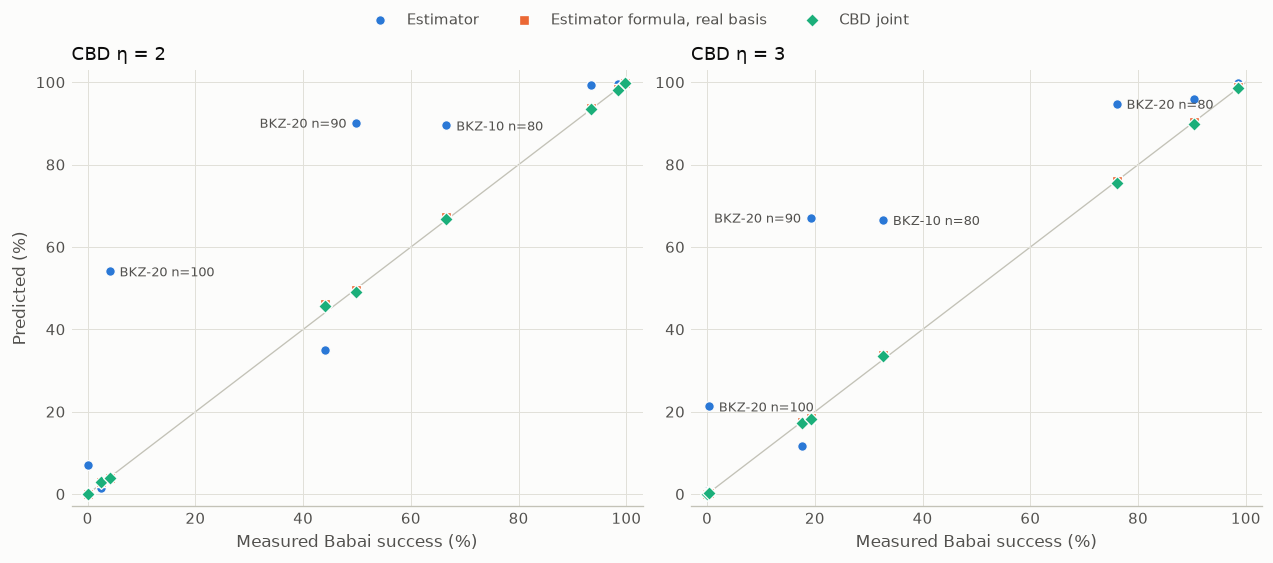

In [4]:
SERIES = {"Estimator": ("#2a78d6", "o"), "Estimator formula, real basis": ("#eb6834", "s"), "CBD joint": ("#1baf7a", "D")}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), dpi=120, constrained_layout=True, facecolor=SURFACE)
for ax, eta in zip(axes, (2, 3)):
    ax.set_facecolor(SURFACE)
    ax.plot([0, 100], [0, 100], color=AXIS, linewidth=0.8, zorder=0)
    pts = [s for s in CAL if s["eta"] == eta]
    for label, (color, marker) in SERIES.items():
        ax.scatter([100 * s["babai"]["k"] / s["babai"]["N"] for s in pts], [100 * MODELS[label](s) for s in pts], color=color,
                   marker=marker, s=34, edgecolors=SURFACE, linewidths=0.8, label=label, zorder=3)
    for s in pts:
        m, e = 100 * s["babai"]["k"] / s["babai"]["N"], 100 * s["estimator"]["beta_params_babai"]
        if e - m > 15:
            left = s["n"] == 90  # BKZ-20 n=90 sits next to BKZ-10 n=80; label it on the other side
            ax.annotate(name(s), (m, e), textcoords="offset points", xytext=(-6 if left else 6, -3), ha="right" if left else "left",
                        fontsize=8, color=INK)
    ax.set_title(f"CBD η = {eta}", loc="left", fontsize=11, color="#0b0b0b")
    ax.set_xlabel("Measured Babai success (%)", color=INK, fontsize=10)
    ax.set_xlim(-3, 103)
    ax.set_ylim(-3, 103)
    ax.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK, labelsize=9, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
axes[0].set_ylabel("Predicted (%)", color=INK, fontsize=10)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside upper center", ncol=3, frameon=False, fontsize=9, labelcolor=INK)
plt.show()

Points on the grey diagonal are perfect predictions; above it the model is too optimistic. The orange squares sit under the green diamonds: on the real basis the estimator's formula and the CBD model agree.

## 2. Where the estimator's error comes from

In points of Babai success, at each setting:

- **(A) profile**: estimator minus the same formula on the real basis.
- **(B) error law**: estimator formula on the real basis minus CBD with independent levels.
- **(C) independence**: CBD with independent levels minus CBD joint.
- **Rest**: CBD joint minus measured, which should be sampling noise only.

They add up to the total, estimator minus measured.

In [5]:
rows = []
for s in CAL:
    m = s["babai"]["k"] / s["babai"]["N"]
    e, sp, cm, cj = s["estimator"]["beta_params_babai"], s["babai"]["sphere"], s["babai"]["cbd_marginals"], s["babai"]["cbd_joint"]
    rows.append([name(s), s["eta"], f"{100 * (e - m):+.1f}", f"{100 * (e - sp):+.1f}", f"{100 * (sp - cm):+.1f}", f"{100 * (cm - cj):+.1f}",
                 f"{100 * (cj - m):+.1f}"])
table(["Setting", "η", "Total", "(A) profile", "(B) error law", "(C) independence", "Rest"], rows)

| Setting | η | Total | (A) profile | (B) error law | (C) independence | Rest |
|---|---|---|---|---|---|---|
| LLL n=70 | 2 | -9.0 | -11.0 | +0.2 | +0.3 | +1.5 |
| LLL n=80 | 2 | -1.0 | -1.4 | -0.0 | +0.1 | +0.3 |
| BKZ-10 n=70 | 2 | +1.1 | +1.1 | +0.2 | +0.0 | -0.2 |
| BKZ-10 n=80 | 2 | +22.9 | +22.2 | +0.4 | +0.1 | +0.3 |
| BKZ-10 n=100 | 2 | +7.1 | +7.0 | -0.0 | +0.0 | +0.1 |
| BKZ-20 n=70 | 2 | +0.2 | +0.1 | +0.0 | +0.0 | +0.1 |
| BKZ-20 n=80 | 2 | +5.9 | +5.5 | +0.3 | +0.0 | +0.1 |
| BKZ-20 n=90 | 2 | +40.3 | +40.6 | +0.2 | +0.2 | -0.7 |
| BKZ-20 n=100 | 2 | +50.0 | +50.1 | -0.0 | +0.1 | -0.2 |
| LLL n=70 | 3 | -6.1 | -5.9 | +0.0 | +0.2 | -0.4 |
| LLL n=80 | 3 | -0.1 | -0.2 | -0.0 | +0.0 | +0.1 |
| BKZ-10 n=70 | 3 | +5.4 | +5.5 | +0.4 | +0.0 | -0.4 |
| BKZ-10 n=80 | 3 | +33.9 | +32.7 | +0.2 | +0.2 | +0.8 |
| BKZ-10 n=100 | 3 | +0.8 | +0.8 | -0.0 | +0.0 | +0.0 |
| BKZ-20 n=70 | 3 | +1.2 | +1.0 | +0.1 | -0.0 | +0.0 |
| BKZ-20 n=80 | 3 | +18.8 | +18.7 | +0.4 | +0.0 | -0.4 |
| BKZ-20 n=90 | 3 | +47.9 | +48.7 | +0.0 | +0.2 | -1.0 |
| BKZ-20 n=100 | 3 | +21.0 | +21.0 | -0.0 | +0.0 | -0.0 |

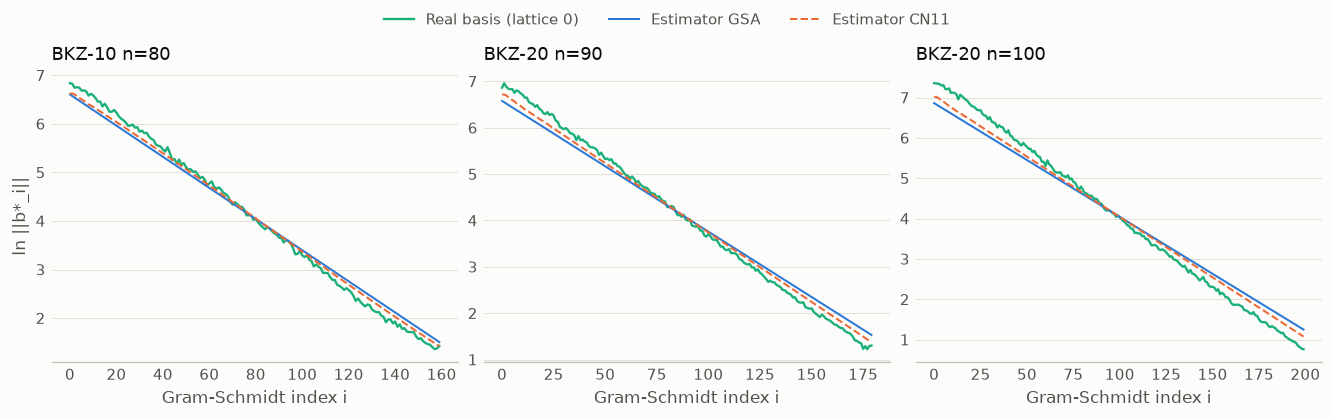

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), dpi=120, constrained_layout=True, facecolor=SURFACE)
for ax, key in zip(axes, ("10,80", "20,90", "20,100")):
    ax.set_facecolor(SURFACE)
    real = np.array(REAL_PROFILES[key]) / 2
    ax.plot(range(len(real)), real, color="#1baf7a", linewidth=1.4, label="Real basis (lattice 0)")
    for label, color, style in (("GSA", "#2a78d6", "-"), ("CN11", "#eb6834", "--")):
        r = PROFILES[key][label]
        if isinstance(r, list):
            ax.plot(range(len(r)), np.array(r) / 2, color=color, linewidth=1.2, linestyle=style, label=f"Estimator {label}")
    beta, n = map(int, key.split(","))
    ax.set_title(f"{RED[beta]} n={n}", loc="left", fontsize=11, color="#0b0b0b")
    ax.set_xlabel("Gram-Schmidt index i", color=INK, fontsize=10)
    ax.grid(True, axis="y", color=GRID, linewidth=0.6)
    ax.tick_params(colors=INK, labelsize=9, length=0)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
axes[0].set_ylabel("ln ||b*_i||", color=INK, fontsize=10)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="outside upper center", ncol=3, frameon=False, fontsize=9, labelcolor=INK)
plt.show()

Babai fails at the last levels, where ||b*_i|| is smallest. The real BKZ bases fall more steeply than the GSA line, so their last vectors are shorter than simulated and Babai fails more often than predicted. That is part (A).

## 3. Lindner-Peikert NearestPlanes

The same comparison for Lindner-Peikert with plane budgets 1024 and 16384 (planes per level chosen from the real basis). **In leaves** is how often the true point was among the leaves, which the models predict; **recovered** is how often the decoder then picked it.

In [7]:
rows = []
for s in CAL:
    for dec in ("lp1024", "lp16384"):
        b = s[dec]
        lo, hi = wilson(b["in_leaves"], b["N"])
        off = [m for m in ("gauss", "sphere", "cbd_joint") if not lo <= b[m] <= hi]
        rows.append([name(s), s["eta"], dec[2:], pct(b["k"] / b["N"]), f"{pct(b['in_leaves'] / b['N'])} ({100 * lo:.1f}-{100 * hi:.1f})",
                     pct(b["gauss"]), pct(b["sphere"]), pct(b["cbd_joint"]), ", ".join(off) or "none", f"{b['nodes']:,.0f}"])
table(["Setting", "η", "Budget", "Recovered", "In leaves (99% CI)", "Gaussian", "Sphere", "CBD joint", "Off", "Nodes"], rows)

| Setting | η | Budget | Recovered | In leaves (99% CI) | Gaussian | Sphere | CBD joint | Off | Nodes |
|---|---|---|---|---|---|---|---|---|---|
| LLL n=70 | 2 | 1024 | 89.7% | 89.7% (87.6-91.5) | 89.4% | 89.9% | 89.5% | none | 134,015 |
| LLL n=70 | 2 | 16384 | 96.9% | 96.9% (95.6-97.9) | 96.6% | 96.9% | 96.7% | none | 2,076,927 |
| LLL n=80 | 2 | 1024 | 27.7% | 27.7% (24.9-30.7) | 26.9% | 27.1% | 26.6% | none | 154,231 |
| LLL n=80 | 2 | 16384 | 48.1% | 48.1% (44.9-51.3) | 45.7% | 46.1% | 45.5% | none | 2,402,559 |
| BKZ-10 n=70 | 2 | 1024 | 100.0% | 100.0% (99.6-100.0) | 100.0% | 100.0% | 100.0% | none | 134,015 |
| BKZ-10 n=70 | 2 | 16384 | 100.0% | 100.0% (99.6-100.0) | 100.0% | 100.0% | 100.0% | none | 2,078,207 |
| BKZ-10 n=80 | 2 | 1024 | 94.9% | 94.9% (93.3-96.2) | 94.8% | 95.2% | 94.9% | none | 154,319 |
| BKZ-10 n=80 | 2 | 16384 | 98.5% | 98.5% (97.5-99.1) | 98.3% | 98.4% | 98.3% | none | 2,404,607 |
| BKZ-10 n=100 | 2 | 1024 | 1.9% | 1.9% (1.2-3.0) | 1.9% | 1.9% | 1.8% | none | 195,263 |
| BKZ-10 n=100 | 2 | 16384 | 5.2% | 5.2% (4.0-6.9) | 5.5% | 5.5% | 5.3% | none | 3,060,351 |
| BKZ-20 n=70 | 2 | 1024 | 100.0% | 100.0% (99.6-100.0) | 100.0% | 100.0% | 100.0% | none | 133,767 |
| BKZ-20 n=70 | 2 | 16384 | 100.0% | 100.0% (99.6-100.0) | 100.0% | 100.0% | 100.0% | none | 2,078,719 |
| BKZ-20 n=80 | 2 | 1024 | 99.8% | 99.8% (99.3-100.0) | 99.7% | 99.8% | 99.7% | none | 154,479 |
| BKZ-20 n=80 | 2 | 16384 | 99.9% | 99.9% (99.4-100.0) | 99.9% | 100.0% | 99.9% | none | 2,405,887 |
| BKZ-20 n=90 | 2 | 1024 | 90.1% | 90.1% (88.0-91.9) | 88.9% | 89.4% | 89.0% | none | 174,975 |
| BKZ-20 n=90 | 2 | 16384 | 95.7% | 95.7% (94.2-96.8) | 95.4% | 95.7% | 95.5% | none | 2,733,567 |
| BKZ-20 n=100 | 2 | 1024 | 29.2% | 29.2% (26.4-32.3) | 30.5% | 30.7% | 30.3% | none | 195,327 |
| BKZ-20 n=100 | 2 | 16384 | 47.2% | 47.2% (44.1-50.5) | 47.6% | 48.1% | 47.5% | none | 3,058,687 |
| LLL n=70 | 3 | 1024 | 66.6% | 66.6% (63.5-69.5) | 67.1% | 67.7% | 67.2% | none | 134,015 |
| LLL n=70 | 3 | 16384 | 85.5% | 85.5% (83.1-87.6) | 84.1% | 84.7% | 84.2% | none | 2,076,927 |
| LLL n=80 | 3 | 1024 | 6.8% | 6.8% (5.3-8.6) | 6.8% | 6.8% | 6.6% | none | 154,231 |
| LLL n=80 | 3 | 16384 | 16.2% | 16.2% (14.0-18.7) | 15.8% | 15.9% | 15.6% | none | 2,402,559 |
| BKZ-10 n=70 | 3 | 1024 | 99.4% | 99.4% (98.7-99.8) | 99.4% | 99.5% | 99.4% | none | 134,015 |
| BKZ-10 n=70 | 3 | 16384 | 99.9% | 99.9% (99.5-100.0) | 99.9% | 99.9% | 99.9% | none | 2,078,207 |
| BKZ-10 n=80 | 3 | 1024 | 79.7% | 79.7% (77.0-82.2) | 79.0% | 79.6% | 79.0% | none | 154,319 |
| BKZ-10 n=80 | 3 | 16384 | 89.8% | 89.8% (87.7-91.6) | 90.0% | 90.5% | 90.1% | none | 2,404,607 |
| BKZ-10 n=100 | 3 | 1024 | 0.1% | 0.1% (0.0-0.5) | 0.1% | 0.1% | 0.1% | none | 195,263 |
| BKZ-10 n=100 | 3 | 16384 | 0.4% | 0.4% (0.2-1.1) | 0.4% | 0.4% | 0.3% | none | 3,060,351 |
| BKZ-20 n=70 | 3 | 1024 | 100.0% | 100.0% (99.6-100.0) | 100.0% | 100.0% | 100.0% | none | 133,767 |
| BKZ-20 n=70 | 3 | 16384 | 100.0% | 100.0% (99.6-100.0) | 100.0% | 100.0% | 100.0% | none | 2,078,719 |
| BKZ-20 n=80 | 3 | 1024 | 97.1% | 97.1% (95.8-98.0) | 97.1% | 97.4% | 97.2% | none | 154,479 |
| BKZ-20 n=80 | 3 | 16384 | 99.1% | 99.1% (98.3-99.6) | 99.1% | 99.2% | 99.1% | none | 2,405,887 |
| BKZ-20 n=90 | 3 | 1024 | 64.2% | 64.2% (61.1-67.3) | 64.2% | 64.7% | 64.1% | none | 174,975 |
| BKZ-20 n=90 | 3 | 16384 | 79.4% | 79.4% (76.7-81.9) | 79.3% | 79.9% | 79.4% | none | 2,733,567 |
| BKZ-20 n=100 | 3 | 1024 | 5.9% | 5.9% (4.6-7.6) | 6.5% | 6.5% | 6.4% | none | 195,327 |
| BKZ-20 n=100 | 3 | 16384 | 14.1% | 14.1% (12.0-16.4) | 14.4% | 14.5% | 14.3% | none | 3,058,687 |

## 4. Do some directions stay close to single coordinates?

Outside the rules. For a unit direction u, the projected CBD error has excess kurtosis -Σu_j⁴/η, so Σu_j⁴ near 1 means the Gaussian picture is wrong there. Shown: the mean over all levels, the mean weighted by where Babai fails, the value at the level that fails most, and that level's failure probability under CBD and under a Gaussian.

In [8]:
table(["Setting", "η", "Σu⁴, all levels", "Σu⁴, weighted by failure", "Σu⁴, worst level", "Worst level fails, CBD", "Worst level fails, Gaussian",
       "Failure in last 10 levels"],
      [[name(s), s["eta"], f"{s['zshape']['s4_mean']:.3f}", f"{s['zshape']['s4_failweighted']:.3f}", f"{s['zshape']['worst_s4']:.3f}",
        pct(s["zshape"]["worst_fail_cbd"]), pct(s["zshape"]["worst_fail_gauss"]), pct(s["zshape"]["fail_share_last10"])] for s in CAL])

| Setting | η | Σu⁴, all levels | Σu⁴, weighted by failure | Σu⁴, worst level | Worst level fails, CBD | Worst level fails, Gaussian | Failure in last 10 levels |
|---|---|---|---|---|---|---|---|
| LLL n=70 | 2 | 0.022 | 0.023 | 0.023 | 10.6% | 10.6% | 86.2% |
| LLL n=80 | 2 | 0.020 | 0.021 | 0.022 | 30.1% | 30.0% | 68.0% |
| BKZ-10 n=70 | 2 | 0.021 | 0.021 | 0.022 | 0.5% | 0.5% | 97.9% |
| BKZ-10 n=80 | 2 | 0.019 | 0.019 | 0.018 | 6.0% | 6.0% | 86.7% |
| BKZ-10 n=100 | 2 | 0.016 | 0.016 | 0.016 | 40.3% | 40.3% | 52.9% |
| BKZ-20 n=70 | 2 | 0.021 | 0.021 | 0.021 | 0.0% | 0.0% | 99.2% |
| BKZ-20 n=80 | 2 | 0.019 | 0.018 | 0.018 | 1.5% | 1.5% | 95.5% |
| BKZ-20 n=90 | 2 | 0.017 | 0.017 | 0.017 | 9.7% | 9.7% | 83.5% |
| BKZ-20 n=100 | 2 | 0.015 | 0.015 | 0.016 | 25.4% | 25.3% | 65.0% |
| LLL n=70 | 3 | 0.022 | 0.023 | 0.024 | 18.7% | 18.6% | 78.6% |
| LLL n=80 | 3 | 0.020 | 0.021 | 0.022 | 39.8% | 39.7% | 60.5% |
| BKZ-10 n=70 | 3 | 0.021 | 0.021 | 0.021 | 2.0% | 2.0% | 94.1% |
| BKZ-10 n=80 | 3 | 0.019 | 0.019 | 0.018 | 12.5% | 12.4% | 78.4% |
| BKZ-10 n=100 | 3 | 0.016 | 0.016 | 0.016 | 49.4% | 49.5% | 46.3% |
| BKZ-20 n=70 | 3 | 0.021 | 0.021 | 0.021 | 0.4% | 0.4% | 97.6% |
| BKZ-20 n=80 | 3 | 0.019 | 0.018 | 0.018 | 4.6% | 4.7% | 89.6% |
| BKZ-20 n=90 | 3 | 0.017 | 0.017 | 0.017 | 17.5% | 17.5% | 74.3% |
| BKZ-20 n=100 | 3 | 0.015 | 0.015 | 0.016 | 35.1% | 35.1% | 56.4% |

## 5. Choosing the final candidate with the CBD prior (rule R2)

The same final lists of 3-plane pruned beam search (`('beam_T', 3, T, 64)`), 16 lattices × 50 targets. **Euclidean** is the usual pick. **Box** drops candidates with any |coordinate| > η, then picks the shortest. **CBD** picks the box candidate with the highest CBD log-likelihood. **In list** is the most any rule could reach. Bonferroni alpha 0.05 / 48.

Every list came out with exactly one candidate. The beam keeps only paths within T·2σ² (at most 36) of the best, and the levels decoded last have the longest Gram-Schmidt vectors (b*₀ is the first basis vector), where any second plane costs at least ||b*_i||²/4. The table records that; the Lindner-Peikert leaves in section 3, which are never pruned, are the real test of R2 and are discussed in the findings.

In [9]:
ALPHA = 0.05 / 48
rows = []
for r in LISTS:
    cells = []
    for rule in ("box", "cbd"):
        x, y, p = mcnemar(r[rule], r["euclid"])
        cells.append(f"{x}/{y}, p={p:.2g}" + (" **helps**" if x > y and p < ALPHA else ""))
    rows.append([name(r), r["eta"], r["cfg"].split(",")[2].strip(), f"{r['list_size']:,.0f}", f"{r['boxed']:.1f}", pct(np.mean(r["euclid"])),
                 pct(np.mean(r["box"])), pct(np.mean(r["cbd"])), pct(np.mean(r["in_list"])), *cells])
table(["Setting", "η", "T", "List size", "Inside box", "Euclidean", "Box", "CBD", "In list", "Box vs Euclidean (only box / only Euclidean)",
       "CBD vs Euclidean"], rows)

| Setting | η | T | List size | Inside box | Euclidean | Box | CBD | In list | Box vs Euclidean (only box / only Euclidean) | CBD vs Euclidean |
|---|---|---|---|---|---|---|---|---|---|---|
| LLL n=80 | 2 | 4.0 | 1 | 0.3 | 25.4% | 25.4% | 25.4% | 25.4% | 0/0, p=1 | 0/0, p=1 |
| LLL n=80 | 2 | 8.0 | 1 | 0.7 | 71.0% | 71.0% | 71.0% | 71.0% | 0/0, p=1 | 0/0, p=1 |
| LLL n=80 | 2 | 12.0 | 1 | 0.8 | 84.9% | 84.9% | 84.9% | 84.9% | 0/0, p=1 | 0/0, p=1 |
| BKZ-10 n=100 | 2 | 4.0 | 1 | 0.0 | 2.9% | 2.9% | 2.9% | 2.9% | 0/0, p=1 | 0/0, p=1 |
| BKZ-10 n=100 | 2 | 8.0 | 1 | 0.2 | 20.9% | 20.9% | 20.9% | 20.9% | 0/0, p=1 | 0/0, p=1 |
| BKZ-10 n=100 | 2 | 12.0 | 1 | 0.2 | 24.9% | 24.9% | 24.9% | 24.9% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=90 | 2 | 4.0 | 1 | 0.9 | 87.0% | 87.0% | 87.0% | 87.0% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=90 | 2 | 8.0 | 1 | 1.0 | 98.2% | 98.2% | 98.2% | 98.2% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=90 | 2 | 12.0 | 1 | 1.0 | 100.0% | 100.0% | 100.0% | 100.0% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=100 | 2 | 4.0 | 1 | 0.3 | 31.8% | 31.8% | 31.8% | 31.8% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=100 | 2 | 8.0 | 1 | 0.8 | 76.6% | 76.6% | 76.6% | 76.6% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=100 | 2 | 12.0 | 1 | 0.9 | 94.5% | 94.5% | 94.5% | 94.5% | 0/0, p=1 | 0/0, p=1 |
| LLL n=80 | 3 | 4.0 | 1 | 0.1 | 9.8% | 9.8% | 9.8% | 9.8% | 0/0, p=1 | 0/0, p=1 |
| LLL n=80 | 3 | 8.0 | 1 | 0.4 | 35.9% | 35.9% | 35.9% | 35.9% | 0/0, p=1 | 0/0, p=1 |
| LLL n=80 | 3 | 12.0 | 1 | 0.4 | 42.5% | 42.5% | 42.5% | 42.5% | 0/0, p=1 | 0/0, p=1 |
| BKZ-10 n=100 | 3 | 4.0 | 1 | 0.0 | 0.1% | 0.1% | 0.1% | 0.1% | 0/0, p=1 | 0/0, p=1 |
| BKZ-10 n=100 | 3 | 8.0 | 1 | 0.0 | 2.6% | 2.6% | 2.6% | 2.6% | 0/0, p=1 | 0/0, p=1 |
| BKZ-10 n=100 | 3 | 12.0 | 1 | 0.0 | 2.9% | 2.9% | 2.9% | 2.9% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=90 | 3 | 4.0 | 1 | 0.6 | 62.9% | 62.9% | 62.9% | 62.9% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=90 | 3 | 8.0 | 1 | 0.9 | 93.0% | 93.0% | 93.0% | 93.0% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=90 | 3 | 12.0 | 1 | 1.0 | 99.4% | 99.4% | 99.4% | 99.4% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=100 | 3 | 4.0 | 1 | 0.1 | 8.4% | 8.4% | 8.4% | 8.4% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=100 | 3 | 8.0 | 1 | 0.4 | 40.0% | 40.0% | 40.0% | 40.0% | 0/0, p=1 | 0/0, p=1 |
| BKZ-20 n=100 | 3 | 12.0 | 1 | 0.5 | 49.6% | 49.6% | 49.6% | 49.6% | 0/0, p=1 | 0/0, p=1 |

## Findings

**1. The estimator's Babai prediction is off at 17 of 18 settings, and almost all of the error is the simulated basis profile.** At BKZ-20, n = 100, η = 2 it predicts 54.1% where 4.1% of 1,600 targets succeed; at BKZ-20, n = 90, η = 3 it predicts 67.1% against 19.2%. With LLL it errs the other way (35.1% predicted, 44.1% measured at n = 70, η = 2). Put the same formula on the real reduced basis instead and it lands inside the 99% interval at all 18 settings. In the decomposition, part (A), the profile, carries the error: up to +50 points. The other parts are small: (B) error law within ±0.4 points, (C) independence within ±0.3, and the remainder within ±1.5, which is sampling noise. The CN11 simulator narrows the gap but doesn't close it (27.3% at BKZ-20, n = 100, η = 2).

**Correction: the BKZ bases were not fully reduced.** They came from fplll BKZ with auto-abort and at most 16 tours. Continuing BKZ on three of them for 100-200 more tours (`converge_test.py`) brought the fitted root-Hermite factor down a long way:

| Basis | Cached δ | After more tours | Estimator's δ |
|---|---|---|---|
| BKZ-20, n = 100 | 1.0175 | 1.0136 | 1.0142 |
| BKZ-10, n = 100 | 1.0192 | 1.0147 (still falling) | 1.0162 |
| BKZ-20, n = 70 | 1.0154 | 1.0136 | 1.0142 |

Converged BKZ reaches the estimator's δ or slightly better. So most of the BKZ gap above reflects bases that were not the fully converged BKZ-β the estimator assumes; it is not an error in the estimator. What stands is narrower: for BKZ stopped early (as here), the estimator's simulated profile overstates decoding success. For LLL, the fitted slope matches the estimator's δ to within 0.0008; that gap comes from the profile's tail and was not looked into further.

**2. At these sizes the exact CBD error adds nothing over a Gaussian of the same variance.** For Babai and both Lindner-Peikert budgets, the Gaussian, the estimator's sphere model and the exact CBD Monte Carlo all agree with each other to within 0.7 points, and with the measurements (no model off at any Babai or Lindner-Peikert setting). The reason is in section 4. The Gram-Schmidt directions are spread over many coordinates, Σu⁴ ≈ 0.015-0.024 on average and at the level that fails most, so the projected CBD error has excess kurtosis of about −0.01 and is Gaussian to within the noise. The Z-shape hypothesis, that some failing levels sit close to a single coordinate, is not supported: the level that fails most has the same Σu⁴ as the rest.

**3. The CBD prior and the ±η box can't help pick the final candidate here (R2: null).** The pre-registered test on pruned-beam lists is empty, because every list has one candidate. The unpruned Lindner-Peikert leaves are a stronger test. On all 28,800 targets (18 settings × 1,600, at both budgets), whenever the true point was among the leaves it was also the shortest leaf. So the most any re-ranking rule could gain is zero. Decoding fails only when the true point is never generated, never when it is generated and then ranked wrongly.

**What this means for novelty.** Directions 2 and 3, a CBD-exact model and a CBD-aware final rule, are measured nulls at toy size and shouldn't be pitched as contributions. Direction 1 is mostly an artifact of under-reduced bases (see the correction under finding 1). What survives is that Wunderer's formula is accurate on the real basis, which is expected and not new. **This study finds no novel contribution.** To check whether the estimator is accurate for converged BKZ, the experiment would have to be redone on fully reduced bases. That would be a validation, not a new method.

## Checks on the statements above

In [10]:
by = {(s["beta"], s["n"], s["eta"]): s for s in CAL}
rate = lambda b: b["k"] / b["N"]


def off(s, value, dec="babai", k="k"):
    lo, hi = wilson(s[dec][k], s[dec]["N"])
    return not lo <= value <= hi


# Finding 1: estimator off at 17 of 18; the same formula on real bases off nowhere; (A) carries the error.
assert sum(off(s, s["estimator"]["beta_params_babai"]) for s in CAL) == 17
assert not any(off(s, f(s)) for s in CAL for m, f in MODELS.items() if m != "Estimator")
s = by[20, 100, 2]
assert round(100 * s["estimator"]["beta_params_babai"], 1) == 54.1 and round(100 * rate(s["babai"]), 1) == 4.1
assert round(100 * s["estimator"]["CN11"], 1) == 27.3
s = by[20, 90, 3]
assert round(100 * s["estimator"]["beta_params_babai"], 1) == 67.1 and round(100 * rate(s["babai"]), 1) == 19.2
s = by[2, 70, 2]
assert round(100 * s["estimator"]["beta_params_babai"], 1) == 35.1 and round(100 * rate(s["babai"]), 1) == 44.1
b = lambda s, k: s["babai"][k]
assert max(abs(s["estimator"]["beta_params_babai"] - b(s, "sphere")) for s in CAL) < 0.51
assert max(abs(b(s, "sphere") - b(s, "cbd_marginals")) for s in CAL) <= 0.0045
assert max(abs(b(s, "cbd_marginals") - b(s, "cbd_joint")) for s in CAL) <= 0.0035
assert max(abs(b(s, "cbd_joint") - rate(s["babai"])) for s in CAL) <= 0.0155

# Finding 2: Gaussian, sphere and CBD agree within 0.7 points; none off for Babai or Lindner-Peikert; Σu⁴ small.
for s in CAL:
    for dec in ("babai", "lp1024", "lp16384"):
        v = [s[dec][m] for m in ("gauss", "sphere", "cbd_joint")]
        assert max(v) - min(v) <= 0.007, (name(s), dec, v)
        if dec != "babai":
            assert not any(off(s, x, dec, "in_leaves") for x in v), (name(s), dec)
z = [s["zshape"] for s in CAL]
assert all(0.015 <= x[k] <= 0.024 for x in z for k in ("s4_mean", "s4_failweighted", "worst_s4"))

# Finding 3: one-candidate beam lists; Lindner-Peikert recovers exactly when the true point is a leaf.
assert all(r["list_size"] == 1 and r["euclid"] == r["box"] == r["cbd"] == r["in_list"] for r in LISTS)
assert sum(s[d]["N"] for s in CAL for d in ("lp16384",)) == 28_800
assert all(s[d]["k"] == s[d]["in_leaves"] for s in CAL for d in ("lp1024", "lp16384"))
print("All numbers quoted in the findings match the data above.")

All numbers quoted in the findings match the data above.


## Limits

- Toy sizes only: n = 70-100, m = n, BKZ block size at most 20, fplll BKZ without pruning strategies. The estimator's GSA and its small-β δ table are meant for much larger dimensions and block sizes, so a large profile error here doesn't by itself mean large errors at cryptographic sizes. Whether the gap shrinks with dimension is the obvious next measurement.
- Only Babai and Lindner-Peikert have closed-form models here. Pruned list decoders (beam with a threshold) were measured, not modelled.
- Wilson intervals treat the 1,600 targets per setting as independent; targets share 16 lattices, so the real uncertainty is somewhat wider.
- Not done yet: BKZ-15/25 bases, Liu-Nguyen pruned enumeration, re-randomised bases, the hybrid attack's meet-in-the-middle probability, Darmstadt or Wenger et al. instances.
- Related work was checked from abstracts and source code only. de Perthuis and Trenkić (PQCrypto 2026, [ePrint 2025/2195](https://eprint.iacr.org/2025/2195)) refine the primal estimate beyond the first two moments of the error, for the uSVP route; Luan et al. ([Symmetry 2023](https://doi.org/10.3390/sym15020355)) model discrete-pruned BDD. Neither abstract covers the Babai/Lindner-Peikert prediction measured here, but their full texts weren't read.

## References

1. R. Lindner, C. Peikert. Better Key Sizes (and Attacks) for LWE-Based Encryption. CT-RSA 2011. [ePrint 2010/613](https://eprint.iacr.org/2010/613).
2. T. Wunderer. A detailed analysis of the hybrid lattice-reduction and meet-in-the-middle attack. J. Math. Cryptology, 2019. DOI 10.1515/jmc-2016-0044. (Source of the estimator's `prob.babai`; model confirmed from the estimator's code, paper not read.)
3. M. R. Albrecht, R. Player, S. Scott. On the concrete hardness of Learning with Errors. J. Math. Cryptology 9(3), 2015. [ePrint 2015/046](https://eprint.iacr.org/2015/046). The lattice estimator.
4. C. P. Schnorr. Lattice reduction by random sampling and birthday methods. STACS 2003. (GSA)
5. Y. Chen, P. Q. Nguyen. BKZ 2.0: Better Lattice Security Estimates. ASIACRYPT 2011. (CN11 simulator)
6. M. Liu, P. Q. Nguyen. Solving BDD by Enumeration: An Update. CT-RSA 2013. [DOI](https://doi.org/10.1007/978-3-642-36095-4_19).
7. P. de Perthuis, F. Trenkić. Refined Modelling of the Primal Attack, and Variants Against Module-Learning With Errors. PQCrypto 2026. [ePrint 2025/2195](https://eprint.iacr.org/2025/2195).
8. L. Luan, Y. Shi, C. Gu, Y. Zheng. Application of Discrete Pruned Enumeration in Solving BDD. Symmetry 15(2):355, 2023. [DOI](https://doi.org/10.3390/sym15020355).
9. X.-W. Chang, Q. Han. Solving box-constrained integer least squares problems. IEEE Trans. Wireless Commun., 2008. (Box constraints in decoding; citation from the research notes, not checked)
10. NIST FIPS 203, Module-Lattice-Based Key-Encapsulation Mechanism Standard, 2024. [DOI](https://doi.org/10.6028/NIST.FIPS.203).

To delete the tools installed for this study: `rm -rf ~/micromamba ~/bin/micromamba ~/lattice-estimator` in WSL.